In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
from scipy import signal
from netCDF4 import Dataset
from osgeo import gdal
from osgeo import osr
#Visualisation specific
import seaborn as sns 
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
%matplotlib inline
import pymannkendall as mk
import statsmodels.api as sm

import cdsapi
import xarray as xr
from urllib.request import urlopen# start the client
import requests
import certifi
import urllib3
import cdsapi
from shapely.geometry import mapping, Point
import geopandas as gpd

from standard_precip.spi import SPI
from standard_precip.utils import plot_index
from scipy import stats as st
import warnings
warnings.filterwarnings("ignore")

c:\Users\Oubaha.ANAS\Anaconda3\lib\site-packages\scipy\__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.26.3
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [5]:
p = pd.read_csv('precip_pixels.csv', low_memory=False)
t = pd.read_csv('t2m_pixels.csv', low_memory=False)
p

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,45.372795,41.519978,38.298520,33.130142,33.649406,43.004400,37.958540,46.379086,40.360332,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,01-02-83,54.538227,44.981575,43.729630,38.954320,39.524376,43.692974,46.819496,46.842700,39.810715,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,01-03-83,43.373627,48.152634,47.043810,59.528854,51.707195,43.105110,41.883816,40.159250,38.529602,...,0.510164,0.706140,0.417943,0.000000,0.000000,0.220665,0.197361,0.209387,0.246599,0.389134
3,01-04-83,55.761684,54.913590,69.151980,59.632690,64.048240,53.445170,56.921368,59.128273,54.414690,...,0.267766,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,01-05-83,35.753826,41.820335,36.096573,33.503025,39.073950,33.861347,29.803953,41.040310,27.788918,...,0.000000,0.000000,0.180426,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
471,01-04-22,29.962677,30.328920,33.085712,31.671246,31.842527,32.053570,29.827665,23.975008,35.034683,...,0.051412,0.032757,0.027820,0.015006,0.018991,0.009296,0.002679,0.006830,0.019800,0.027247
472,01-05-22,47.754380,36.569640,33.544525,31.114515,35.936783,34.583270,34.617690,30.771700,33.049126,...,0.849882,1.175693,0.943517,0.919590,0.857849,1.069258,1.381420,1.566892,1.263503,1.757484
473,01-06-22,11.451672,14.168227,15.077348,9.552426,9.393827,8.527346,7.471623,9.089783,5.421932,...,7.296117,6.383902,5.676613,6.132770,6.896019,6.472976,5.797501,5.668376,6.694219,7.691684
474,01-07-22,3.335845,4.025859,1.709678,0.712577,3.447032,1.103242,1.570361,1.944072,1.790466,...,8.649037,7.615705,9.398964,12.183945,19.726957,16.239513,15.465842,15.721779,15.940118,11.441097


In [8]:
p = p.replace([-99],[np.nan])
p = p[:-8]
t = t[:-8]

In [4]:
#(P - P*)/sd

#reset index
p = p.reset_index(drop=True)
p.set_index('Dates', inplace = True)
#p.index = pd.to_datetime(p.index, format='%Y/%m/%d')

In [9]:
t

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,1983-01-01,15.195984,15.193909,15.205627,15.219391,15.219391,15.223541,15.223541,15.201477,15.191833,...,15.942291,16.016022,16.057373,16.082886,16.338562,16.475006,16.510132,16.617645,16.643158,16.392975
1,1983-02-01,14.286316,14.280121,14.274597,14.260834,14.223602,14.194672,14.174683,14.151245,14.116119,...,19.446503,19.557465,19.647736,19.618103,19.940613,20.200409,20.278290,20.448517,20.567719,20.350647
2,1983-03-01,14.936859,14.944427,14.956146,14.965790,14.956146,14.944427,14.928589,14.905151,14.881744,...,23.845215,23.948578,24.014740,23.948578,24.213898,24.389648,24.444763,24.559845,24.585358,24.405487
3,1983-04-01,14.554382,14.544739,14.540619,14.537170,14.528900,14.517181,14.505463,14.488251,14.474457,...,29.509857,29.697296,29.810333,29.757935,30.048767,30.226562,30.275482,30.374725,30.372650,30.187286
4,1983-05-01,15.450256,15.430267,15.418549,15.408905,15.399261,15.393768,15.385498,15.373779,15.382050,...,34.172485,34.321350,34.399230,34.364075,34.661102,34.866455,34.977386,35.110413,35.192413,35.094543
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,2021-08-01,21.932892,21.903961,21.872253,21.829529,21.786804,21.745453,21.710297,21.681366,21.659302,...,35.735443,35.933228,36.024870,36.034515,36.237823,36.357025,36.419067,36.547913,36.462463,36.247467
464,2021-09-01,21.899810,21.889465,21.879822,21.874329,21.868103,21.860535,21.856384,21.860535,21.842620,...,34.754820,34.997375,35.159332,35.126250,35.391570,35.612762,35.735443,35.907715,35.940796,35.758880
465,2021-10-01,21.205872,21.158997,21.104553,21.039795,20.948120,20.877838,20.826843,20.797913,20.772400,...,30.149384,30.317505,30.438110,30.426392,30.735138,30.977692,31.086578,31.238892,31.276093,31.085205
466,2021-11-01,18.321167,18.266724,18.210236,18.155090,18.071014,18.012451,17.981445,17.962128,17.960052,...,24.483368,24.643219,24.811370,24.832733,25.120117,25.333038,25.455719,25.627990,25.694153,25.586640


**Percent of Normal Index**

In [10]:
#Old calculation
pixels = list(p.columns)[1:]
PNI=pd.DataFrame()
PNI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    PNI[pixel] =  (ma/np.nanmean(ma))*100.0

In [11]:
pixels = list(p.columns)[1:]
PNI=pd.DataFrame()
PNI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    pa = np.array([[np.nanmean(ma.to_list()[i*12:(i + 1)*12])]*12 for i in range(39)]).flatten()
    PNI[pixel] =  (ma/pa)*100.0

In [12]:
PNI

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01-03-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,23.226158,21.652888,20.500001,18.983482,18.229517,16.960840,21.853893,20.082047,17.638767,12.272166
3,01-04-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,18.464653,17.243842,16.804627,15.250137,14.057528,11.748217,13.652342,12.187320,11.020581,7.873549
4,01-05-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,24.037771,26.378568,24.998827,21.834347,20.555926,18.834584,25.761330,25.687310,24.693906,18.603738
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,267.013349,265.519117,258.264089,267.347469,278.309560,292.927789,316.874176,327.304785,317.639599,329.302830
464,01-09-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,345.352991,339.233694,332.393792,336.813444,343.476219,349.175120,354.241276,355.788967,351.633643,352.360229
465,01-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,316.622507,309.635576,300.446588,299.515081,294.188540,292.224439,285.856226,265.581837,221.678183,176.165865
466,01-11-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,93.519063,90.437035,95.926133,87.454429,82.069052,76.031468,52.810785,41.614872,50.299996,44.450176


In [13]:
pixels = list(p.columns)[1:]
PNI_classes = pd.DataFrame()
PNI_classes["Dates"]=p["Dates"]
Int = []
for pixel in pixels:
    for i in PNI[pixel]:
        if i <= 40: Int.append(-3) #Extremly dry
        elif 40 < i <= 55 : Int.append(-2) #Severely dry
        elif 55 < i <= 80 : Int.append(-1) #Moderately dry
        elif 80 < i <= 110 : Int.append(0) #Normal
        else : Int.append(1) #Wet
    PNI_classes[pixel] = Int
    Int = []

In [14]:
PNI_classes

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
1,01-02-83,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
2,01-03-83,1,1,1,1,1,1,1,1,1,...,-3,-3,-3,-3,-3,-3,-3,-3,-3,-3
3,01-04-83,1,1,1,1,1,1,1,1,1,...,-3,-3,-3,-3,-3,-3,-3,-3,-3,-3
4,01-05-83,1,1,1,1,1,1,1,1,1,...,-3,-3,-3,-3,-3,-3,-3,-3,-3,-3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
464,01-09-21,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
465,01-10-21,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
466,01-11-21,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,-1,-2,-2,-2,-2


In [15]:
PNI_classes.to_csv("outputchirps/PNI.csv")

**Deciles Index**

In [16]:
pixels = list(p.columns)[1:]
DI=pd.DataFrame()
DI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    DI[pixel] =  pd.qcut(ma, 10, labels=False, duplicates='drop')

In [17]:
DI = DI.replace([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], [-3, -2, -1, 0, 0, 0, 0, 1, 2, 3])
DI

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01-03-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,-2.0,-1.0,-2.0,-1.0,0.0,0.0,0.0,0.0,0.0
3,01-04-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-3.0,-3.0,-3.0,-3.0,-3.0,-3.0,-3.0,-3.0,-3.0,-2.0
4,01-05-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0
464,01-09-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0
465,01-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.0,2.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0
466,01-11-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
[698, 699, 
       766, 767, 768, 769, 770, 771, 772,
       837, 838, 839, 840, 841, 842, 843, 844, 845, 
       910, 911, 912, 913, 914, 915, 
       983, 984, 985]

In [249]:
ono = DI['845'].to_list()
c = 0
for i in ono:
    if i == -3: c+=1
c

46

In [18]:
DI.to_csv("outputchirps/DI.csv")

In [72]:
dfmean = pd.DataFrame()
dfmean["Dates"]=DI["Dates"]
dfmean["Average"]=DI.mean(axis=1, skipna=True)
dfmean

,Dates,Average
0,1983-01-01,NaN
1,1983-02-01,NaN
2,1983-03-01,0.145522
3,1983-04-01,0.311982
4,1983-05-01,-0.186774
...,...,...
471,2022-04-01,-0.131841
472,2022-05-01,-0.242537
473,2022-06-01,-0.629768
474,2022-07-01,-1.393449


In [74]:
dfmean = dfmean.reset_index(drop=True)
dfmean.set_index('Dates', inplace = True)
dfmean.index = pd.to_datetime(dfmean.index.to_numpy())

<Axes: xlabel='Year', ylabel='DI'>

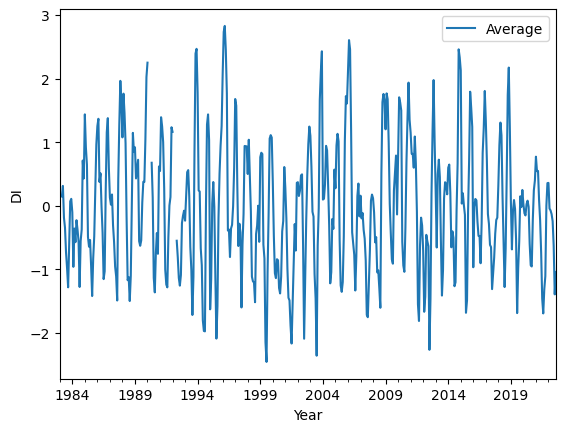

In [75]:
#plt.plot(dfmean['Dates'], dfmean['Average'])
dfmean.plot(xlabel='Year', ylabel='DI')

**Z-score index**

In [144]:
#Old calculation
pixels = list(p.columns)[1:]
ZSI=pd.DataFrame()
ZSI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    ZSI[pixel] =  (ma - ma.mean(skipna=True))/ma.std(skipna=True)

In [19]:
pixels = list(p.columns)[1:]
ZSI=pd.DataFrame()
ZSI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    pa = np.array([[np.nanmean(ma.to_list()[i*12:(i + 1)*12])]*12 for i in range(39)]).flatten()
    ps = np.array([[np.nanstd(ma.to_list()[i*12:(i + 1)*12])]*12 for i in range(39)]).flatten()
    ZSI[pixel] = (ma - pa)/ps

In [20]:
ZSI

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01-03-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.785759,-0.817734,-0.831120,-0.796258,-0.798043,-0.840869,-0.839434,-0.813938,-0.839344,-0.865858
3,01-04-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.834492,-0.863752,-0.869753,-0.832951,-0.838759,-0.893653,-0.927534,-0.894343,-0.906790,-0.909271
4,01-05-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.777452,-0.768410,-0.784088,-0.768239,-0.775338,-0.821896,-0.797461,-0.756850,-0.767445,-0.803366
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.346696,1.367871,1.353608,1.408294,1.469773,1.542635,1.677415,1.758086,1.760925,1.818277
464,01-09-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.978380,1.977058,1.987627,1.992878,2.006930,1.992384,1.966431,1.978397,2.035971,2.001113
465,01-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.746715,1.732455,1.714388,1.678997,1.600661,1.537011,1.437507,1.280691,0.984500,0.603964
466,01-11-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.052258,-0.079030,-0.034843,-0.105576,-0.147802,-0.191650,-0.364985,-0.451579,-0.402123,-0.440487


In [21]:
ZSI.to_csv("outputchirps/ZSI.csv")

In [ ]:
dfmean = pd.DataFrame()
dfmean["Dates"]=ZSI["Dates"]
dfmean["Average"]=ZSI.mean(axis=1, skipna=True)
dfmean

In [110]:
dfmean = dfmean.reset_index(drop=True)
dfmean.set_index('Dates', inplace = True)
dfmean.index = pd.to_datetime(dfmean.index.to_numpy())

<Axes: xlabel='Year', ylabel='ZSI'>

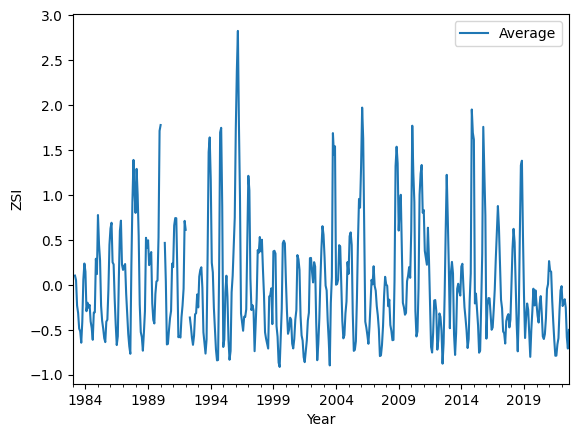

In [111]:
dfmean.plot(xlabel='Year', ylabel='ZSI')

**China Z-Index**

In [146]:
#Old calculation
pixels = list(p.columns)[1:]
CZI=pd.DataFrame()
CZI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    zsi = (ma - ma.mean(skipna=True))/ma.std(skipna=True)
    cs  = np.power(zsi, 3)/len(ma)
    CZI[pixel] =  6.0/cs*np.power((cs/2.0*zsi + 1.0), 1.0/3.0)-6.0/cs + cs/6.0

In [22]:
pixels = list(p.columns)[1:]
CZI=pd.DataFrame()
CZI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    pa = np.array([[np.nanmean(ma.to_list()[i*12:(i + 1)*12])]*12 for i in range(39)]).flatten()
    ps = np.array([[np.nanstd(ma.to_list()[i*12:(i + 1)*12])]*12 for i in range(39)]).flatten()
    zsi = (ma - pa)/ps
    cs  = np.power(zsi, 3)/len(ma)
    #CZI[pixel] = (6.0/cs)*(np.power((1.0 + (cs/2.0)*zsi), 1.0/3.0)) - (6.0/cs) + (cs/6.0)
    CZI[pixel] = cs

In [23]:
CZI

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01-03-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-1.036626e-03,-0.001168,-1.226721e-03,-0.001079,-0.001086,-0.001270,-0.001264,-0.001152,-0.001263,-0.001387
3,01-04-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-1.241709e-03,-0.001377,-1.405860e-03,-0.001235,-0.001261,-0.001525,-0.001705,-0.001529,-0.001593,-0.001606
4,01-05-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-1.004096e-03,-0.000969,-1.030027e-03,-0.000969,-0.000996,-0.001186,-0.001084,-0.000926,-0.000966,-0.001108
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5.218706e-03,0.005469,5.299472e-03,0.005968,0.006784,0.007844,0.010085,0.011611,0.011667,0.012845
464,01-09-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.654563e-02,0.016512,1.677873e-02,0.016912,0.017272,0.016899,0.016248,0.016546,0.018033,0.017123
465,01-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.138728e-02,0.011111,1.076667e-02,0.010114,0.008763,0.007759,0.006347,0.004488,0.002039,0.000471
466,01-11-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-3.049458e-07,-0.000001,-9.038703e-08,-0.000003,-0.000007,-0.000015,-0.000104,-0.000197,-0.000139,-0.000183


In [24]:
CZI.to_csv("outputchirps/CZI.csv")

<Axes: xlabel='Year', ylabel='CZI'>

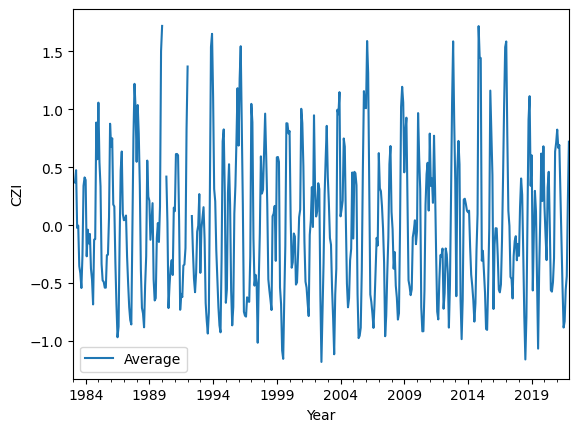

In [220]:
dfmean = pd.DataFrame()
dfmean["Dates"]=CZI["Dates"]
dfmean["Average"]=CZI.mean(axis=1, skipna=True)
dfmean = dfmean.reset_index(drop=True)
dfmean.set_index('Dates', inplace = True)
dfmean.index = pd.to_datetime(dfmean.index.to_numpy())
dfmean.plot(xlabel='Year', ylabel='CZI')

**RAI**

In [25]:
pixels = list(p.columns)[1:]
RAI=pd.DataFrame()
RAI["Dates"]=p["Dates"]
for pixel in pixels:
    ma = p[pixel].rolling(window=3).sum()
    y = ma.copy()
    x1 = ma.copy().sort_values(ascending=False).dropna()
    x_avg  = x1.mean()    
    mx_avg = x1.head(10).mean()
    mn_avg = x1.tail(10).mean()
    anom   = ma - x_avg

    rai_plus  = 3.0*anom[anom>=0]/(mx_avg-x_avg)
    rai_minus = -3.0*anom[anom<0]/(mn_avg-x_avg)     
    y.loc[anom>=0] = rai_plus.values
    y.loc[anom<0] = rai_minus.values
    RAI[pixel] =  y

In [26]:
RAI

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01-03-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-2.770215,-2.802785,-2.836609,-2.854491,-2.857376,-2.857542,-2.840056,-2.840293,-2.860735,-2.873107
3,01-04-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-2.883483,-2.907118,-2.925256,-2.944058,-2.954359,-2.976691,-2.977758,-2.975031,-2.980468,-2.970329
4,01-05-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-2.750908,-2.690960,-2.728688,-2.786096,-2.803296,-2.814713,-2.774451,-2.744630,-2.733098,-2.733161
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.032369,0.790072,0.649772,0.545453,0.547313,0.747074,0.825527,0.769243,0.667262,0.882737
464,01-09-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.565771,1.213952,1.055986,0.867339,0.819205,1.003501,0.988960,0.884346,0.797903,0.986761
465,01-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.370150,1.043754,0.880923,0.694509,0.613564,0.743867,0.689864,0.519824,0.298477,0.191859
466,01-11-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.629820,-0.975109,-1.042715,-1.375420,-1.450931,-1.333368,-1.885128,-2.215751,-2.069195,-2.098503


In [27]:
RAI.to_csv("outputchirps/RAI.csv")

<Axes: xlabel='Year', ylabel='RAI'>

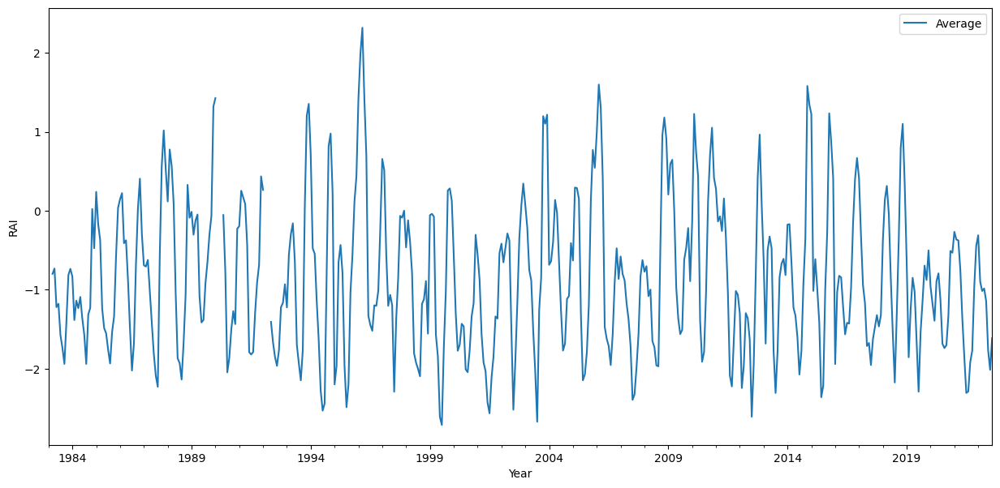

In [28]:
dfmean = pd.DataFrame()
dfmean["Dates"]=RAI["Dates"]
dfmean["Average"]=RAI.mean(axis=1, skipna=True)
dfmean = dfmean.reset_index(drop=True)
dfmean.set_index('Dates', inplace = True)
dfmean.index = pd.to_datetime(dfmean.index.to_numpy())
dfmean.plot(figsize=(15, 7), xlabel='Year', ylabel='RAI')

**SPI 3**

In [61]:
nans = list(dict.fromkeys(nans))
nans
#(1990-02-01, 1992-02-01, 1984-02-01, 1984-05-01, 1984-06-01)

[85, 109, 13, 16, 17]

In [28]:
spi = SPI()

In [29]:
def spi_value(p, pixel):
    return spi.calculate(
        p, 
        'Dates', 
        pixel, 
        freq="M", 
        scale=3,
        fit_type="lmom", 
        dist_type="gam"
    )

In [75]:
df_spi=spi_value(p, '4822')

In [76]:
df_spi

,Dates,4822_scale_3,4822_scale_3_calculated_index
0,1983-01-01,NaN,NaN
1,1983-02-01,NaN,NaN
2,1983-03-01,0.246599,0.045667
3,1983-04-01,0.246599,0.022404
4,1983-05-01,0.246599,-0.179676
...,...,...,...
471,2022-04-01,0.500907,0.207108
472,2022-05-01,1.356771,0.298157
473,2022-06-01,7.977522,0.561127
474,2022-07-01,23.897840,0.289689


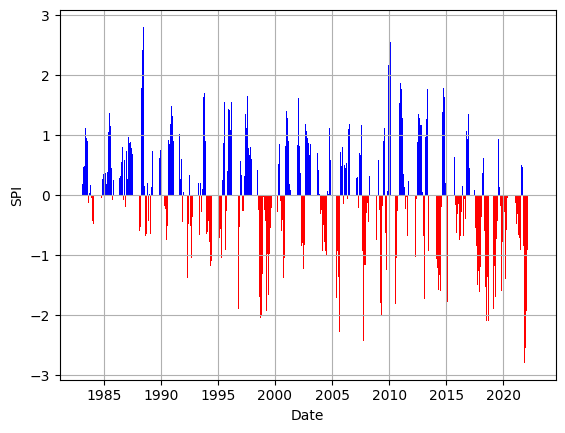

In [167]:
fig = plot_index(df_spi, 'Dates', '0_scale_3_calculated_index')

In [30]:
# Needs optimisation !!
pixels = list(p.columns)[1:]
spi_data=pd.DataFrame()
spi_data["Dates"]=p["Dates"]
for pixel in pixels:
    #fill missing data (-99.0) with a moving average (not a good idea for rainfall data)
    #ma = p[pixel].rolling(window=3 , min_periods=1).mean()
    #for i in range(476):
    #    if pd.isnull(p[pixel][i]):
    #        p[pixel][i] = ma[i]
    x = spi_value(p, pixel)
    spi_data[pixel] = x[pixel + '_scale_3_calculated_index']

In [31]:
df = spi_data[[str(i) for i in range(4824)]]
df.insert(0, 'Dates', p["Dates"])
df

,Dates,0,1,2,3,4,5,6,7,8,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01-03-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.514597,-0.540595,-0.557972,-0.530734,-0.507785,-0.519451,-0.495876,-0.497043,-0.527725,-0.596167
3,01-04-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.611205,-0.634696,-0.639515,-0.615881,-0.604126,-0.650685,-0.656984,-0.663574,-0.683568,-0.741117
4,01-05-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.499722,-0.455234,-0.473097,-0.474293,-0.461537,-0.480250,-0.436035,-0.408987,-0.407479,-0.449154
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.141504,1.039796,0.939712,0.910360,0.956437,1.105808,1.173874,1.142616,1.077444,1.171010
464,01-09-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.394595,1.269465,1.166426,1.106432,1.132052,1.259819,1.270882,1.212892,1.161167,1.229403
465,01-10-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.306327,1.181388,1.073079,1.004727,1.001439,1.103770,1.087801,0.975961,0.805076,0.694768
466,01-11-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.321702,0.235861,0.219539,0.152617,0.152811,0.191975,0.033005,-0.092467,-0.034770,-0.068291


In [933]:
dfmean = pd.DataFrame()
dfmean["Dates"]=df["Dates"]
dfmean["Average"]=df.mean(axis=1, skipna=True)
dfmean

,Dates,Average
0,01-01-83,NaN
1,01-02-83,NaN
2,01-03-83,0.090936
3,01-04-83,0.171679
4,01-05-83,-0.121787
...,...,...
463,01-08-21,-1.004478
464,01-09-21,-0.726878
465,01-10-21,-0.611393
466,01-11-21,-0.051201


In [133]:
dfmean = dfmean.reset_index(drop=True)
dfmean.set_index('Dates', inplace = True)
dfmean.index = pd.to_datetime(dfmean.index.to_numpy())

<Axes: xlabel='Year', ylabel='SPI3'>

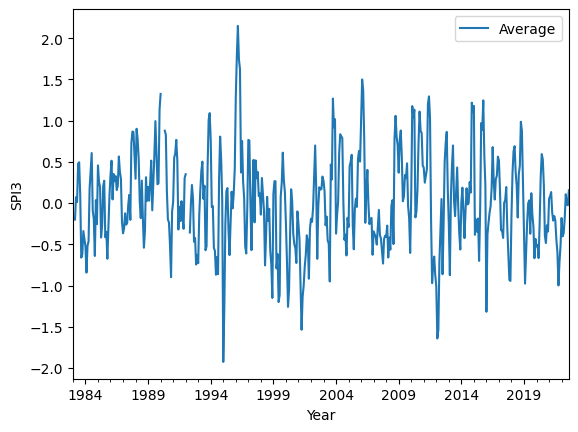

In [134]:
#plt.plot(dfmean['Dates'], dfmean['Average'])
dfmean.plot(xlabel='Year', ylabel='SPI3')
#fig = plot_index(dfmean, 'Dates', 'Average')

In [32]:
df.to_csv("outputchirps/SPI3.csv")

**SPEI**

In [ ]:
#see SPEI_package in R studio

In [161]:
spei = pd.read_csv('spei3_thorthwaite.csv', low_memory=False)

In [163]:
spei = spei.drop(columns='Unnamed: 0')
spei

,Dates,spei3$fitted,spei3$fitted.1,spei3$fitted.2,spei3$fitted.3,spei3$fitted.4,spei3$fitted.5,spei3$fitted.6,spei3$fitted.7,spei3$fitted.8,...,spei3$fitted.4814,spei3$fitted.4815,spei3$fitted.4816,spei3$fitted.4817,spei3$fitted.4818,spei3$fitted.4819,spei3$fitted.4820,spei3$fitted.4821,spei3$fitted.4822,spei3$fitted.4823
0,1983-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1983-02-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1983-03-01,0.266574,0.171241,0.037820,0.075758,0.063070,0.153254,0.157710,0.236095,-0.023911,...,0.500481,0.578952,0.634251,0.660912,0.770060,0.803850,0.859592,0.915240,0.968892,1.064163
3,1983-04-01,0.602232,0.533202,0.747785,0.784670,0.781340,0.499433,0.678306,0.655357,0.372343,...,-0.189733,-0.144631,-0.085641,-0.051326,0.067125,0.118371,0.211062,0.293303,0.381153,0.507308
4,1983-05-01,0.724621,0.916248,1.048500,1.160215,1.213706,0.810783,0.834465,1.009732,0.575250,...,-0.828575,-0.781231,-0.709800,-0.679139,-0.650587,-0.607287,-0.552720,-0.491976,-0.454987,-0.400318
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
471,2022-04-01,-0.490763,-0.512699,-0.487312,-0.685110,-0.409628,-0.296691,-0.403401,-0.488757,-0.413724,...,0.125572,0.144508,0.125746,0.111184,0.165310,0.142696,0.112295,0.077251,0.045194,-0.021504
472,2022-05-01,0.221295,-0.028520,-0.084371,-0.237974,0.251254,0.178479,0.015660,-0.159311,-0.040024,...,0.492186,0.527347,0.502225,0.501621,0.518809,0.528879,0.503839,0.456888,0.446283,0.441143
473,2022-06-01,0.201983,0.032350,0.078069,-0.104813,0.078264,-0.091661,-0.144669,-0.381430,-0.121536,...,0.523078,0.563041,0.539238,0.568855,0.696780,0.728207,0.701552,0.650300,0.664925,0.707084
474,2022-07-01,0.713291,0.533308,0.449680,0.220636,0.473998,0.251753,0.244248,0.184900,0.153823,...,0.288588,0.267801,0.215166,0.278259,0.537283,0.536638,0.540905,0.532145,0.534922,0.528474


In [164]:
speimean = pd.DataFrame()
speimean["Dates"]=spei["Dates"]
speimean["Average"]=spei.mean(axis=1, skipna=True)
speimean

,Dates,Average
0,1983-01-01,NaN
1,1983-02-01,NaN
2,1983-03-01,-0.122181
3,1983-04-01,-0.023228
4,1983-05-01,-0.079087
...,...,...
471,2022-04-01,0.021819
472,2022-05-01,-0.123980
473,2022-06-01,-0.649486
474,2022-07-01,-0.976145


In [165]:
speimean = speimean.reset_index(drop=True)
speimean.set_index('Dates', inplace = True)
speimean.index = pd.to_datetime(speimean.index.to_numpy())

<Axes: xlabel='Year', ylabel='SPEI3'>

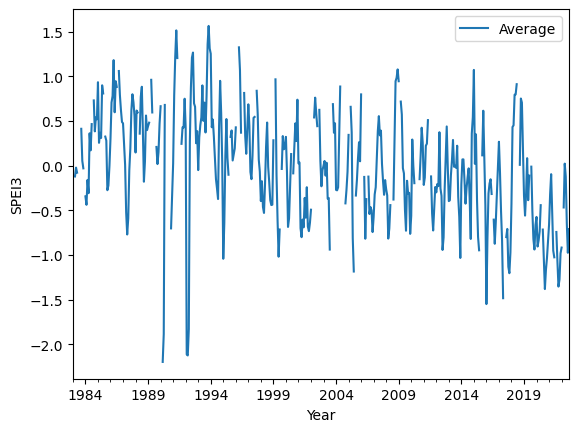

In [167]:
speimean.plot(xlabel='Year', ylabel='SPEI3')

**Drought indices analysis**

**aridity categories**

In [2]:
p = pd.read_csv('precip_pixels.csv', low_memory=False)
pet = pd.read_csv('output/PEthorn.csv', low_memory=False)
pet = pet.drop(['Unnamed: 0'], axis=1)
p = p.drop(['Dates'], axis=1)
p = p.replace([-99],[np.nan])
p = p[:-8]

In [3]:
pixels = list(p.columns)[0:]
AI=[]
for pixel in pixels:
    pa = [sum(p[pixel].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
    peta = [sum(pet[pixel].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
    p_pet = [pa[i]/peta[i] for i in range(39)]
    AI.append(np.nanmean(p_pet))

In [4]:
AI_classes = []
for i in AI:
    if i <= 0.05: AI_classes.append(5) #Hyper-arid climate zone
    elif 0.05 < i <= 0.2 : AI_classes.append(4) #Arid climate zone
    elif 0.2 < i <= 0.5 : AI_classes.append(3) #Semi-arid climate zone
    elif 0.5 < i <= 0.75 : AI_classes.append(2) #Sub-humid climate zone
    else : AI_classes.append(1) #Humid climate zone

In [7]:
shp = pd.read_csv('shapfiles/01shp_ext.csv', low_memory=False)
shp = shp.values.tolist()
shp = np.reshape(shp, (-1, 72))
shp

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [54]:
print(shp.shape)

(67, 72)


In [15]:
I = np.array(AI)
I = np.reshape(I, (-1, 72))
I = I*shp
I = I.flatten()

INA = []
for i in range(4824):
    if I[i] == 0 : INA.append(np.nan)
    else : INA.append(I[i])

In [16]:
np.nanmean(INA)

0.21054625878821034

In [10]:
pet = pd.read_csv('output/PEthorn_r.csv', low_memory=False)
pet = pet.drop(['Unnamed: 0'], axis=1)
pet = pet[:-8]
pet = pet.drop(['Dates'], axis=1)
pet.columns = [str(i) for i in range(4824)]
pet

,0,1,2,3,4,5,6,7,8,9,...,4814,4815,4816,4817,4818,4819,4820,4821,4822,4823
0,50.201395,50.040833,49.946984,49.863889,49.727035,49.605725,49.450031,49.162405,48.926444,48.690510,...,18.104517,17.595392,17.098454,17.071584,16.898990,16.564640,16.132833,15.868924,15.719403,15.074727
1,40.670635,40.594839,40.509118,40.381034,40.159640,39.974429,39.827202,39.660815,39.417752,39.128619,...,35.742387,35.487944,35.282285,34.850552,35.563714,36.357462,36.164941,36.510628,37.149464,35.997705
2,49.025681,49.114816,49.213924,49.300792,49.302646,49.284677,49.233764,49.136024,49.018260,48.963262,...,86.327936,86.729726,86.786842,85.580463,87.723478,89.126810,89.128134,89.865098,89.918817,87.753593
3,45.477146,45.575144,45.690596,45.810499,45.932739,46.028495,46.116473,46.171735,46.227003,46.296600,...,183.879285,190.135428,194.396187,193.577436,203.741258,210.664899,213.290484,217.774867,218.477554,212.426125
4,52.583447,52.729794,52.912847,53.109605,53.337948,53.585793,53.808762,54.009398,54.316841,54.663055,...,315.008818,328.089506,337.680643,339.258340,363.644278,382.676122,395.013681,410.309093,419.312364,412.029397
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,99.181942,99.266357,99.318225,99.279758,99.262223,99.251638,99.287058,99.373543,99.503488,99.508326,...,410.073808,429.339499,442.286845,445.751640,472.913562,492.309518,504.537692,523.726116,522.499933,503.614130
464,95.283718,95.294870,95.302333,95.342931,95.397479,95.436943,95.498158,95.623858,95.563071,95.501131,...,404.941769,423.513297,437.399919,436.217894,463.092833,485.498877,498.887244,518.102763,522.744318,504.288087
465,92.436189,91.949344,91.394462,90.761724,89.945669,89.294727,88.789003,88.452524,88.126957,87.796426,...,255.307597,261.645879,266.207542,264.989633,278.396892,289.318146,294.173979,301.515900,302.772980,292.218159
466,68.311462,67.746223,67.157297,66.580626,65.843029,65.270912,64.872951,64.549181,64.317509,64.122771,...,110.297369,111.505354,113.218641,112.920231,115.990928,118.354523,119.502176,121.497210,122.045081,120.061464


In [27]:
t = t.drop(['Dates'], axis=1)

In [14]:
pixels = list(p.columns)[0:]
rainfall_avg=[]
temp_avg=[]
pet_avg=[]
for pixel in pixels:
    pa = [sum(p[pixel].to_list()[i*12:(i + 1)*12]) for i in range(39)]
    ta = [sum(t[pixel].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
    peta = [sum(pet[pixel].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
    #p_pet = [pa[i] for i in range(39)]
    if AI_classes[int(pixel)] == 2:    #subhumid regions
        rainfall_avg.append(pa)
        temp_avg.append(ta)
        pet_avg.append(peta)

print(np.nanmin(rainfall_avg))
print(np.nanmean(rainfall_avg))
print(np.nanmax(rainfall_avg))
print('-------------------------')
print(np.nanmin(temp_avg))
print(np.nanmean(temp_avg))
print(np.nanmax(temp_avg))
print('-------------------------')
print(np.nanmin(pet_avg))
print(np.nanmean(pet_avg))
print(np.nanmax(pet_avg))

147.012813
493.19718901920965
1500.7716805
-------------------------
7.504897983333333
17.40244161182706
20.107508291666665
-------------------------
39.96233847883102
69.38720959025724
89.77687114147967


In [19]:
pixels = list(p.columns)[0:]
rainfall_avg=[]
temp_avg=[]
pet_avg=[]
for pixel in pixels:
    pa = [sum(p[pixel].to_list()[i*12:(i + 1)*12]) for i in range(39)]
    ta = [sum(t[pixel].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
    peta = [sum(pet[pixel].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
    #p_pet = [pa[i] for i in range(39)]
    if AI_classes[int(pixel)] == 3:    #semi-arid regions
        rainfall_avg.append(pa)
        temp_avg.append(ta)
        pet_avg.append(peta)

print(np.nanmin(rainfall_avg))
print(np.nanmean(rainfall_avg))
print(np.nanmax(rainfall_avg))
print('-------------------------')
print(np.nanmin(temp_avg))
print(np.nanmean(temp_avg))
print(np.nanmax(temp_avg))
print('-------------------------')
print(np.nanmin(pet_avg))
print(np.nanmean(pet_avg))
print(np.nanmax(pet_avg))

47.158552900000004
305.02091294925583
966.240816
-------------------------
9.55154915
18.268648450780056
22.250175666666667
-------------------------
45.39922318108291
72.85944787516327
108.77607900868874


In [18]:
pixels = list(p.columns)[0:]
rainfall_avg=[]
temp_avg=[]
pet_avg=[]
for pixel in pixels:
    pa = [sum(p[pixel].to_list()[i*12:(i + 1)*12]) for i in range(39)]
    ta = [sum(t[pixel].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
    peta = [sum(pet[pixel].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
    #p_pet = [pa[i] for i in range(39)]
    if AI_classes[int(pixel)] == 4 or AI_classes[int(pixel)] == 5:    #arid regions
        rainfall_avg.append(pa)
        temp_avg.append(ta)
        pet_avg.append(peta)

print(np.nanmin(rainfall_avg))
print(np.nanmean(rainfall_avg))
print(np.nanmax(rainfall_avg))
print('-------------------------')
print(np.nanmin(temp_avg))
print(np.nanmean(temp_avg))
print(np.nanmax(temp_avg))
print('-------------------------')
print(np.nanmin(pet_avg))
print(np.nanmean(pet_avg))
print(np.nanmax(pet_avg))

0.34169683
68.95383588720524
462.88066169999996
-------------------------
14.757921833333334
24.003043538063146
30.502716166666662
-------------------------
59.71757861592685
112.52311547120178
164.8177650915987


In [ ]:
0.34169683
68.95383588720524
462.88066169999996
#-------------------------
14.757921833333334
24.003043538063146
30.502716166666662
#-------------------------
59.71757861592685
112.52311547120178
164.8177650915987

In [54]:
I = np.array(rainfall_avg)
I = np.reshape(I, (-1, 72))
I = I*shp
I = I.flatten()

INA = []
for i in range(4824):
    if I[i] == 0 : INA.append(np.nan)
    else : INA.append(I[i])

print(np.nanmin(INA))
print(np.nanmean(INA))
print(np.nanmax(INA))

41.102887127405396
192.8450113175209
573.4437629897224


In [ ]:
#shpa = []
#for i in range(4824):
#    if I[i] == 4 or I[i] == 5 : shpa.append(1)
#    else: shpa.append(0)
shp = shp.flatten()
annual = pd.DataFrame()
annual["Dates"]=p["Dates"]
p = p.drop(['Dates'], axis=1)
#newp = p.drop(['Dates'], axis=1)
newp = p * np.array(shp)
newp = newp.replace(0, np.nan)
annual['p'] = newp.mean(axis=1, skipna=True)

newt = t.drop(['Dates'], axis=1)
newt *= np.array(shp)
newt = newt.replace(0, np.nan)
annual['t'] = newt.mean(axis=1, skipna=True)

pa = [np.nansum(annual['p'].to_list()[i*12:(i + 1)*12]) for i in range(39)]
ta = [sum(annual['t'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

datetime_series = pd.Series(pd.date_range("1983", periods=39, freq="Y"))
avgs = pd.DataFrame()
avgs["Dates"]=datetime_series
avgs['p'] = pa
avgs['t'] = ta
#avgs.set_index("Dates", inplace = True)
#avgs.index = pd.to_datetime(avgs.index, format='%Y/%m/%d')
print(np.min(pa))
print(np.min(ta))
print(np.mean(pa))
print(np.mean(ta))
print(np.max(pa))
print(np.max(ta))
avgs

In [46]:
print(shp.shape)

(66, 72)


(67, 72)


<Figure size 640x480 with 0 Axes>

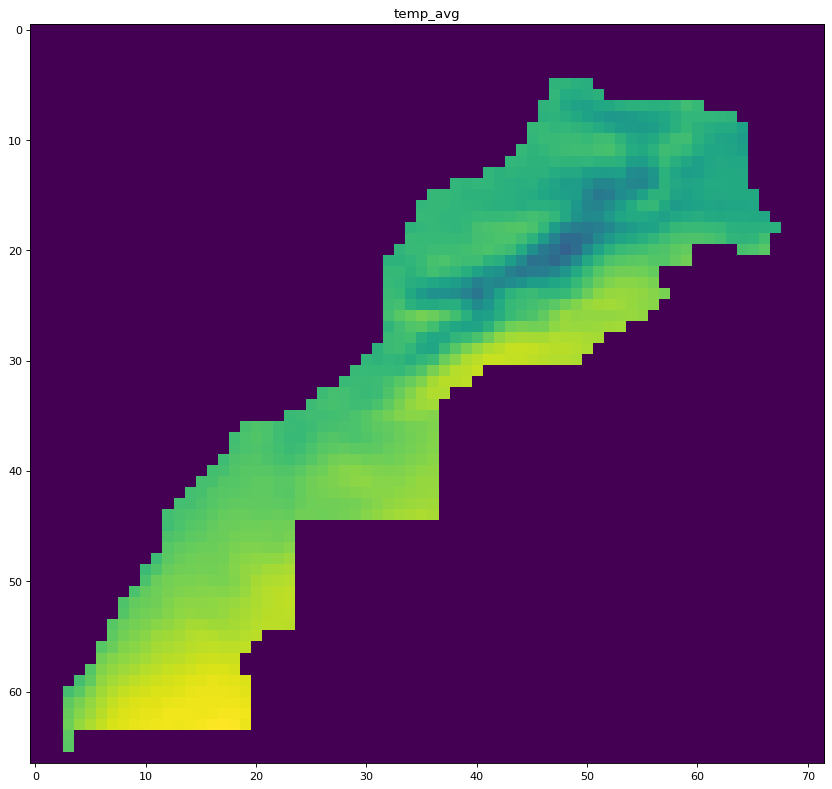

In [62]:
I = np.array(temp_avg)
I = np.reshape(I, (-1, 72))
print(I.shape)
I = I*shp
plt.figure()
plt.figure(figsize=(14, 12), dpi=80)
plt.title('temp_avg')
plt.imshow(I)

In [63]:
# export
driver = gdal.GetDriverByName("GTiff")
driver.Register()
outds = driver.Create("output/temp_avg.tif", xsize = I.shape[1],
                      ysize = I.shape[0], bands = 1, 
                      eType = gdal.GDT_Float32)
#outds.SetGeoTransform(gt)
#outds.SetProjection(proj)
gt = [-17.875, 0.25, 0, 37.125, 0, -0.25]
outds.SetGeoTransform(gt)

# Get raster projection
epsg = 4326
srs = osr.SpatialReference()
srs.ImportFromEPSG(epsg)
proj = srs.ExportToWkt()
outds.SetProjection(proj)

outband = outds.GetRasterBand(1)
outband.WriteArray(I)
outband.SetNoDataValue(np.nan)
outband.FlushCache()

# close your datasets and bands!!!
outband = None
outds = None

<Figure size 640x480 with 0 Axes>

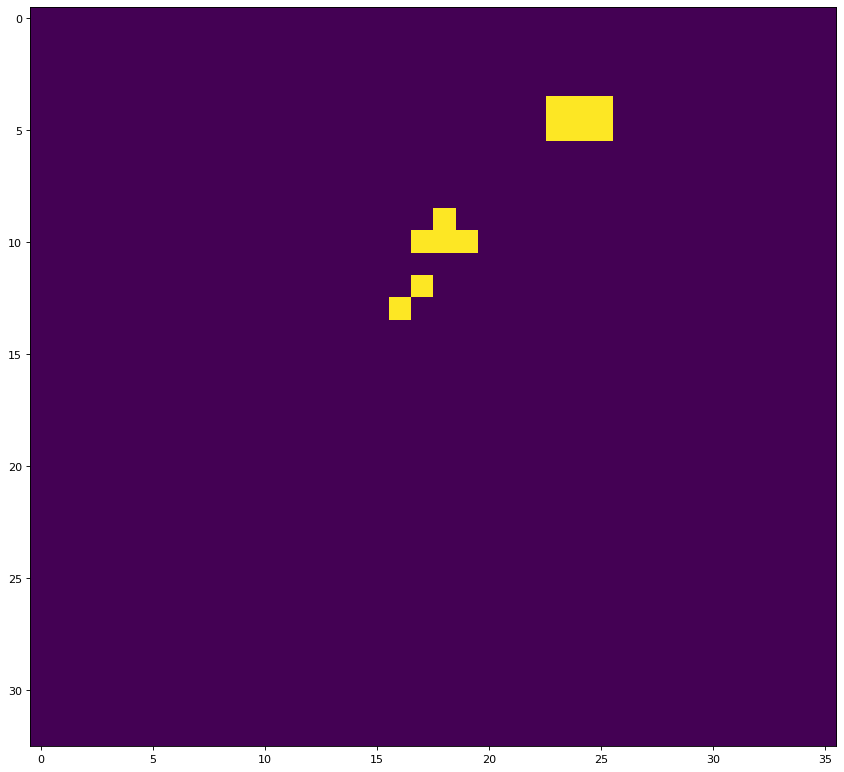

In [923]:
[1906, 1907, 1908,
       1977, 1978, 1979,
       2049, 2050,
       2121]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)

shpa = np.reshape(shpa, (-1, 72))
plt.figure()
plt.figure(figsize=(14, 12), dpi=80)
plt.imshow(shpa)
# export
driver = gdal.GetDriverByName("GTiff")
driver.Register()
outds = driver.Create("output/souss.tif", xsize = shpa.shape[1],
                      ysize = shpa.shape[0], bands = 1, 
                      eType = gdal.GDT_Float32)


# Specify raster location through geotransform array
# (uperleftx, scalex, skewx, uperlefty, skewy, scaley)
# Scale = size of one pixel in units of raster projection
# this example below assumes 100x100
gt = [-17.875, 0.25, 0, 37.125, 0, -0.25]
outds.SetGeoTransform(gt)

# Get raster projection
epsg = 4326
srs = osr.SpatialReference()
srs.ImportFromEPSG(epsg)
proj = srs.ExportToWkt()
outds.SetProjection(proj)

#outds.SetGeoTransform(gt)
#outds.SetProjection(proj)
outband = outds.GetRasterBand(1)
outband.WriteArray(shpa)
outband.SetNoDataValue(np.nan)
outband.FlushCache()

# close your datasets and bands!!!
outband = None
outds = None

**trend significance map**

In [159]:
SPI = pd.read_csv('output/SPI3_R.csv', low_memory=False)
SPI = SPI.drop(['Unnamed: 0'], axis=1)
SPI = SPI[:-8]
SPI = SPI.drop(['Dates'], axis=1)
SPI.columns = [str(i) for i in range(4824)]

SPEI = pd.read_csv('output/spei.csv', low_memory=False)
SPEI = SPEI.drop(['Unnamed: 0'], axis=1)
SPEI = SPEI[:-8]
SPEI = SPEI.drop(['Dates'], axis=1)
SPEI.columns = [str(i) for i in range(4824)]

mPDSI = pd.read_csv('output/mPDSI.csv', low_memory=False)
mPDSI = mPDSI.drop(['Unnamed: 0'], axis=1)

PalmerZ = pd.read_csv('output/PalmerZ.csv', low_memory=False)
PalmerZ = PalmerZ.drop(['Unnamed: 0'], axis=1)

In [162]:
pixels = list(p.columns)[1:]
ptrend=[]
ttrend=[]
spitrend=[]
speitrend=[]
scpdsitrend=[]
pzitrend=[]

lat = [[37 - 0.25*i]*72 for i in range(67)]
lat = np.reshape(lat, (-1,4824))
lon = [0.25*i - 17.75 for i in range(72)]*67
for pixel in pixels:
    ptrend.append(mk.original_test(p[pixel]).z)
    ttrend.append(mk.original_test(t[pixel]).z)
    spitrend.append(mk.original_test(SPI[pixel]).z)
    speitrend.append(mk.original_test(SPEI[pixel]).z)
    scpdsitrend.append(mk.original_test(mPDSI[pixel]).z)
    pzitrend.append(mk.original_test(PalmerZ[pixel]).z)

C = pd.DataFrame()
C['Lat'] = pd.Series(lat[0])
C['Lon'] = pd.Series(lon)
C['pZ'] = pd.Series(ptrend)
C['tZ'] = pd.Series(ttrend)
C['spiZ'] = pd.Series(spitrend)
C['speiZ'] = pd.Series(speitrend)
C['scpdsiZ'] = pd.Series(scpdsitrend)
C['pziZ'] = pd.Series(pzitrend)
C['Coordinates'] = C[['Lon', 'Lat']].values.tolist()
C['Coordinates'] = C['Coordinates'].apply(Point)
trends = gpd.GeoDataFrame(C, geometry = 'Coordinates')
trends = trends.set_crs('epsg:4326')

trends.to_file('output/mkZ.shp')

**Morocco**

In [79]:
avgs.to_csv("output/pt_avgs.csv")

rainfall :  Mann_Kendall_Test(trend='no trend', h=False, p=0.7348263750767032, z=-0.33871243101105464, Tau=-0.03913630229419703, s=-29.0, var_s=6833.666666666667, slope=-0.3336473135127349, intercept=205.9910593559312)
temps :  Mann_Kendall_Test(trend='increasing', h=True, p=4.812539262810667e-05, z=4.064549172132655, Tau=0.45479082321187586, s=337.0, var_s=6833.666666666667, slope=0.026333258114481506, intercept=19.662358510398025)


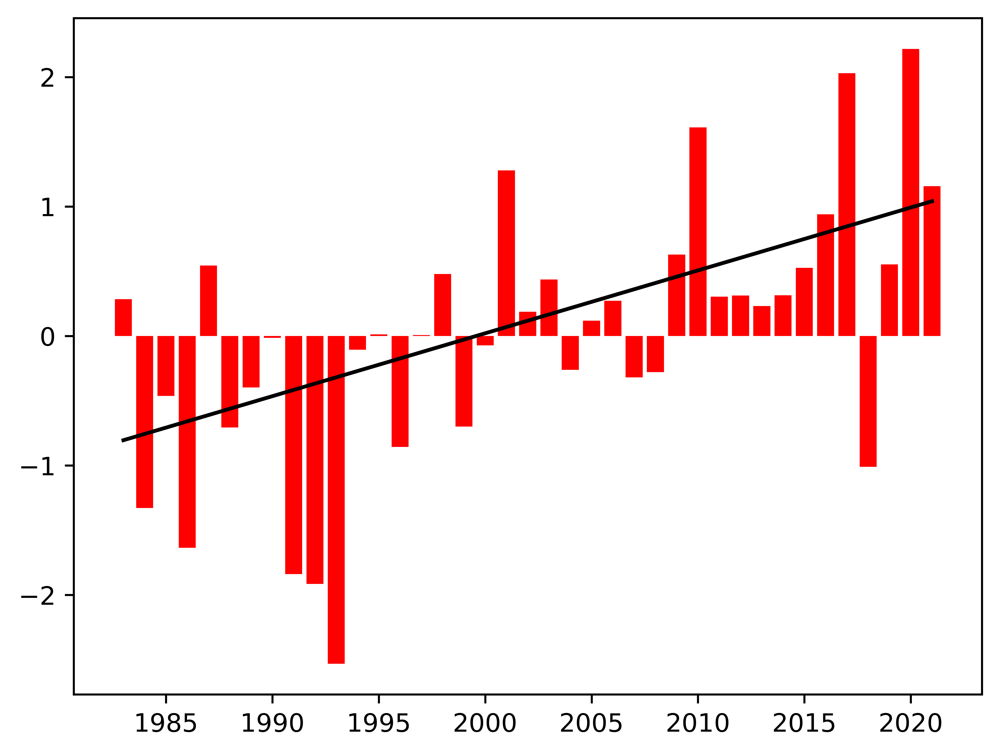

In [77]:
shp = pd.read_csv('shapfiles/01shp.csv', low_memory=False)
shp = shp.values.tolist()
shp = np.reshape(shp, (-1, 72))
shp = shp.flatten()

annual = pd.DataFrame()
annual["Dates"]=p["Dates"]
newp = p.drop(['Dates'], axis=1)
newp *= np.array(shp)
newp = newp.replace(0, np.nan)
annual['p'] = newp.mean(axis=1, skipna=True)

newt = t.drop(['Dates'], axis=1)
newt *= np.array(shp)
newt = newt.replace(0, np.nan)
annual['t'] = newt.mean(axis=1, skipna=True)

pa = [np.nansum(annual['p'].to_list()[i*12:(i + 1)*12]) for i in range(39)]
ta = [sum(annual['t'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

datetime_series = pd.Series(pd.date_range("1983", periods=39, freq="Y"))
avgs = pd.DataFrame()
avgs["Dates"]=datetime_series
avgs['Precipitation'] = (pa - np.mean(pa))/np.std(pa) 
avgs['Temperature'] = (ta - np.mean(ta))/np.std(ta) 
avgs.set_index("Dates", inplace = True)
avgs.index = pd.to_datetime(avgs.index, format='%YYYY/%m/%d').year

plt.rcParams['figure.dpi'] = 800
plt.rcParams['savefig.dpi'] = 800
#avgs.loc[:,['p','t']].plot(secondary_y=['t'], mark_right=False, figsize = (20,5), kind='bar', grid=True, xlabel='Years', title='Precipitation (mm) and temperature (°C) time series in Morocco')
#avgs.loc[:,['Temperature']].plot(figsize = (15,5), kind='bar', xlabel='Year', color='orange', title='Temperature variation in Morocco')

# Sen's slope
from scipy.stats import theilslopes
y = avgs.loc[:,['Temperature']]
x = avgs.index
slp, intcp, lo, hi = theilslopes(y, x)

# Plot
y2 = slp*x + intcp
plt.bar(x, height=avgs['Temperature'], color='red') 
plt.plot(x, y2, color='grey')

#avgs.loc[:,['t']].plot(figsize = (20,5), kind='bar', grid=True, xlabel='Year', title='Temperature variation in Morocco')
ptrend = mk.original_test(pa)
ttrend = mk.original_test(ta)
# perform Mann-Kendall Trend Test
print('rainfall : ', ptrend)
print('temps : ', ttrend)
#avgs

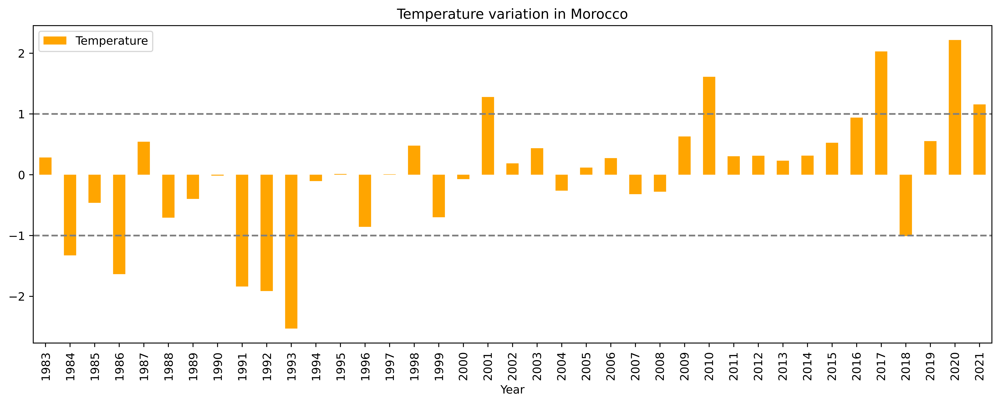

rainfall :  Mann_Kendall_Test(trend='no trend', h=False, p=0.7348263750767032, z=-0.33871243101105464, Tau=-0.03913630229419703, s=-29.0, var_s=6833.666666666667, slope=-0.3336473135127349, intercept=205.9910593559312)
temps :  Mann_Kendall_Test(trend='increasing', h=True, p=4.812539262810667e-05, z=4.064549172132655, Tau=0.45479082321187586, s=337.0, var_s=6833.666666666667, slope=0.026333258114481506, intercept=19.662358510398025)


In [62]:
shp = pd.read_csv('shapfiles/01shp.csv', low_memory=False)
shp = shp.values.tolist()
shp = np.reshape(shp, (-1, 72))
shp = shp.flatten()

annual = pd.DataFrame()
annual["Dates"]=p["Dates"]
newp = p.drop(['Dates'], axis=1)
newp *= np.array(shp)
newp = newp.replace(0, np.nan)
annual['p'] = newp.mean(axis=1, skipna=True)

newt = t.drop(['Dates'], axis=1)
newt *= np.array(shp)
newt = newt.replace(0, np.nan)
annual['t'] = newt.mean(axis=1, skipna=True)

pa = [np.nansum(annual['p'].to_list()[i*12:(i + 1)*12]) for i in range(39)]
ta = [sum(annual['t'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

datetime_series = pd.Series(pd.date_range("1983", periods=39, freq="Y"))
avgs = pd.DataFrame()
avgs["Dates"]=datetime_series
avgs['Precipitation'] = (pa - np.mean(pa))/np.std(pa) 
avgs['Temperature'] = (ta - np.mean(ta))/np.std(ta) 
avgs.set_index("Dates", inplace = True)
avgs.index = pd.to_datetime(avgs.index, format='%YYYY/%m/%d').year

plt.rcParams['figure.dpi'] = 800
plt.rcParams['savefig.dpi'] = 800
#avgs.loc[:,['p','t']].plot(secondary_y=['t'], mark_right=False, figsize = (20,5), kind='bar', grid=True, xlabel='Years', title='Precipitation (mm) and temperature (°C) time series in Morocco')
ax = avgs.loc[:,['Temperature']].plot(figsize = (15,5), kind='bar', xlabel='Year', color='orange', title='Temperature variation in Morocco')
ax.axhline(y=1, color='grey', ls='--')
ax.axhline(y=-1, color='grey', ls='--')

# Sen's slope
from scipy.stats import theilslopes
y = avgs.loc[:,['Temperature']]
x = avgs.index
slp, intcp, lo, hi = theilslopes(y, x)

# Plot
y2 = slp*x + intcp
ax.plot(x, y2, color='black')
plt.show()

#avgs.loc[:,['t']].plot(figsize = (20,5), kind='bar', grid=True, xlabel='Year', title='Temperature variation in Morocco')
ptrend = mk.original_test(pa)
ttrend = mk.original_test(ta)
# perform Mann-Kendall Trend Test
print('rainfall : ', ptrend)
print('temps : ', ttrend)
#avgs

In [95]:
shp = pd.read_csv('shapfiles/01shp.csv', low_memory=False)
shp = shp.values.tolist()
shp = np.reshape(shp, (-1, 72))
shp = shp.flatten()

DI_ma = pd.DataFrame()
DI_ma["Dates"]=p["Dates"]
DI = pd.read_csv('output/DI.csv', low_memory=False)
DI = DI.drop(['Unnamed: 0'], axis=1)
DI = DI[:-8]
DI = DI.drop(['Dates'], axis=1)
DI *= np.array(shp)
DI = DI.replace(0, np.nan)
DI_ma["DI"]=DI.mean(axis=1, skipna=True)
PNI = pd.read_csv('output/PNI.csv', low_memory=False)
PNI = PNI.drop(['Unnamed: 0'], axis=1)
#PNI = PNI[:-8]
PNI = PNI.drop(['Dates'], axis=1)
PNI *= np.array(shp)
PNI = PNI.replace(0, np.nan)
DI_ma["PNI"]=PNI.mean(axis=1, skipna=True)
RAI = pd.read_csv('output/RAI.csv', low_memory=False)
RAI = RAI.drop(['Unnamed: 0'], axis=1)
RAI = RAI[:-8]
RAI = RAI.drop(['Dates'], axis=1)
RAI *= np.array(shp)
RAI = RAI.replace(0, np.nan)
DI_ma["RAI"]=RAI.mean(axis=1, skipna=True)
ZSI = pd.read_csv('output/ZSI.csv', low_memory=False)
ZSI = ZSI.drop(['Unnamed: 0'], axis=1)
#ZSI = ZSI[:-8]
ZSI = ZSI.drop(['Dates'], axis=1)
ZSI *= np.array(shp)
ZSI = ZSI.replace(0, np.nan)
DI_ma["ZSI"]=ZSI.mean(axis=1, skipna=True)
CZI = pd.read_csv('output/CZI.csv', low_memory=False)
CZI = CZI.drop(['Unnamed: 0'], axis=1)
#CZI = CZI[:-8]
CZI = CZI.drop(['Dates'], axis=1)
CZI *= np.array(shp)
CZI = CZI.replace(0, np.nan)
DI_ma["CZI"]=CZI.mean(axis=1, skipna=True)
SPI = pd.read_csv('output/SPI3_R.csv', low_memory=False)
SPI = SPI.drop(['Unnamed: 0'], axis=1)
SPI = SPI.drop(['Dates'], axis=1)
SPI *= np.array(shp)
SPI = SPI.replace(0, np.nan)
SPI = SPI.replace(-np.inf, np.nan)
DI_ma["SPI"]=SPI.mean(axis=1, skipna=True)
SPEI = pd.read_csv('output/spei.csv', low_memory=False)
SPEI = SPEI.drop(['Unnamed: 0'], axis=1)
SPEI = SPEI[:-8]
SPEI = SPEI.drop(['Dates'], axis=1)
SPEI *= np.array(shp)
SPEI = SPEI.replace(0, np.nan)
DI_ma["SPEI"]=SPEI.mean(axis=1, skipna=True)
PDSI = pd.read_csv('output/PDSI.csv', low_memory=False)
PDSI = PDSI.drop(['Unnamed: 0'], axis=1)
PDSI *= np.array(shp)
PDSI = PDSI.replace(0, np.nan)
DI_ma["PDSI"]=PDSI.mean(axis=1, skipna=True)
mPDSI = pd.read_csv('output/mPDSI.csv', low_memory=False)
mPDSI = mPDSI.drop(['Unnamed: 0'], axis=1)
mPDSI *= np.array(shp)
mPDSI = mPDSI.replace(0, np.nan)
DI_ma["scPDSI"]=mPDSI.mean(axis=1, skipna=True)
PalmerZ = pd.read_csv('output/PalmerZ.csv', low_memory=False)
PalmerZ = PalmerZ.drop(['Unnamed: 0'], axis=1)
PalmerZ *= np.array(shp)
PalmerZ = PalmerZ.replace(0, np.nan)
DI_ma["PZI"]=PalmerZ.mean(axis=1, skipna=True)
DI_ma

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.638508,-0.638508,-1.915525
1,01-02-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.131512,-0.126904,0.558639
2,01-03-83,-0.940415,0.258201,-0.984569,0.425195,0.425218,-0.650273,-0.735213,-1.092595,-1.079616,-2.098050
3,01-04-83,0.073846,0.741585,-0.757647,0.788317,0.787924,-0.273731,-0.594182,-1.215056,-1.202707,-1.014774
4,01-05-83,-1.757463,-0.904348,-1.856910,-0.169450,-0.169461,-0.755287,-0.808587,-1.214027,-1.180072,-0.464101
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-2.370930,-2.733863,-2.574476,-1.031625,-1.031422,-0.638494,-0.607683,-2.587279,-2.513554,-1.220706
464,01-09-21,-2.175316,-2.012101,-1.997847,-0.641993,-0.641867,-0.668544,-1.110270,-2.778780,-2.774127,-1.461901
465,01-10-21,-1.597996,-1.912065,-1.878901,-0.467604,-0.467809,-1.102322,-1.221075,-3.092113,-3.124460,-1.984311
466,01-11-21,0.181628,-0.103185,-0.966803,0.300350,0.298805,-0.722606,-1.030900,-2.866898,-2.756758,-0.285731


In [96]:
DIc_ma = pd.DataFrame()
DIc_ma['Dates'] = DI_ma['Dates']
#DIc_ma['DI'] = DI_ma['DI'].round(0)

index = DI_ma['DI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['DI'] = ic

DIc_ma['PNI'] = DI_ma['PNI'].round(0)

index = DI_ma['RAI'].to_list()
ic = []
for i in index:
    if i <= -3: ic.append(-3)
    elif -3 < i <= -2 : ic.append(-2)
    elif -2 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 2 : ic.append(1)
    elif 2 < i < 3 : ic.append(2)
    elif 3 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['RAI'] = ic

index = DI_ma['ZSI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['ZSI'] = ic

index = DI_ma['CZI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['CZI'] = ic

index = DI_ma['SPI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['SPI'] = ic

index = DI_ma['SPEI'].to_list()
ic = []
for i in index:
    if i <= -1.83: ic.append(-3)
    elif -1.83 < i < -1.43 : ic.append(-2)
    elif -1.43 <= i < -1 : ic.append(-1)
    elif -1 <= i <= 1 : ic.append(0)
    elif 1 < i <= 1.43 : ic.append(1)
    elif 1.43 < i < 1.83 : ic.append(2)
    elif 1.83 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['SPEI'] = ic

index = DI_ma['PDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    #elif 1 < i <= 3 : ic.append(1)
    #elif 3 < i < 4 : ic.append(2)
    #elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['PDSI'] = ic

index = DI_ma['scPDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    #elif 1 < i <= 3 : ic.append(1)
    #elif 3 < i < 4 : ic.append(2)
    #elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['scPDSI'] = ic

index = DI_ma['PZI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    #elif 1 < i <= 3 : ic.append(1)
    #elif 3 < i < 4 : ic.append(2)
    #elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_ma['PZI'] = ic
DIc_ma

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,-1.0
1,01-02-83,NaN,1.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0
2,01-03-83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,-1.0,-1.0
3,01-04-83,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-1.0,-1.0,-1.0
4,01-05-83,-2.0,-1.0,-1.0,0.0,0.0,0.0,0.0,-1.0,-1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.0,-3.0,-2.0,-1.0,-1.0,0.0,0.0,-1.0,-1.0,-1.0
464,01-09-21,-3.0,-2.0,-1.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0
465,01-10-21,-2.0,-2.0,-1.0,0.0,0.0,-1.0,-1.0,-2.0,-2.0,-1.0
466,01-11-21,0.0,-0.0,0.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,0.0


In [33]:
DI_ma.to_csv('output/DI_ma.csv')

<AxesSubplot:title={'center':'Morocco'}, ylabel='Value'>

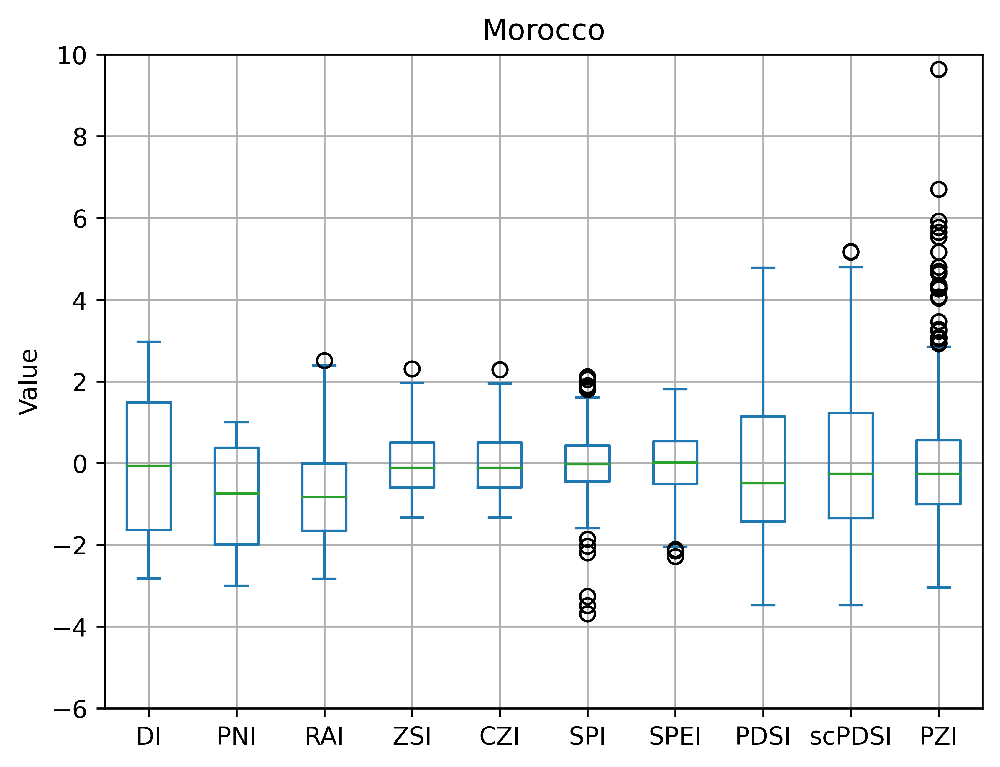

In [28]:
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
DI_ma.plot(kind='box', title='Morocco', grid = True, ylim = (-6, 10), ylabel='Value')

In [51]:
DI_ma

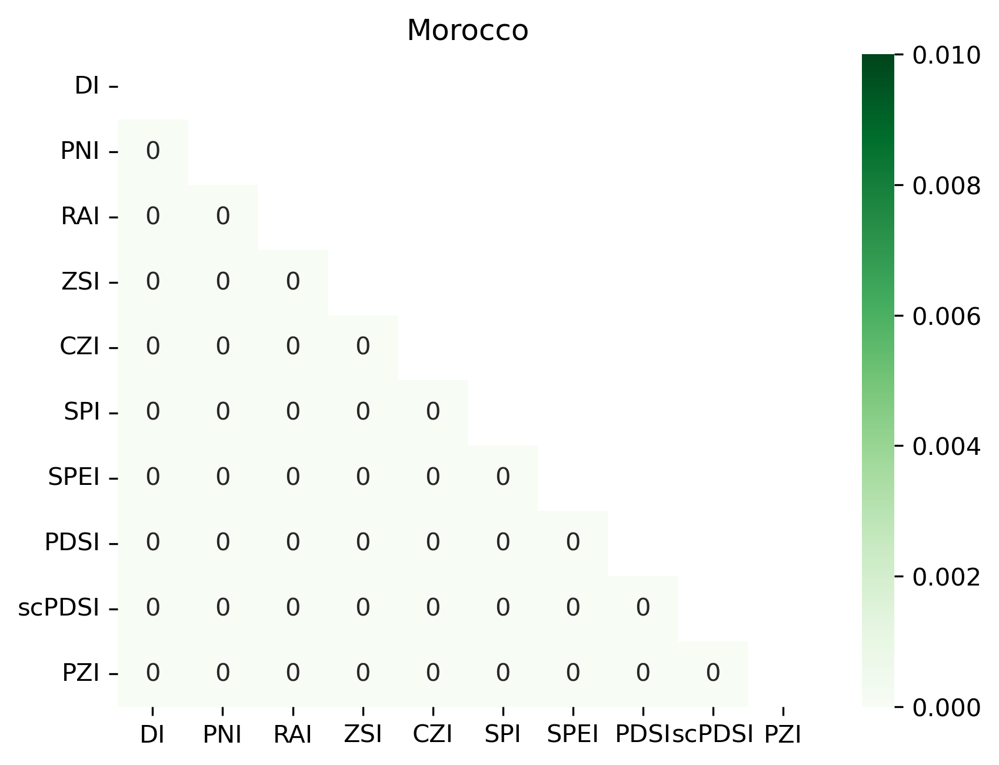

In [92]:
def calculate_pvalues(df):
    dfcols = pd.DataFrame(columns=df.columns)
    pvalues = dfcols.transpose().join(dfcols, how='outer')
    for r in df.columns:
        for c in df.columns:
            tmp = df[df[r].notnull() & df[c].notnull()]
            pvalues[r][c] = round(stats.pearsonr(tmp[r], tmp[c])[1], 4)
    return pvalues

#DI_ma = DI_ma.drop(['Dates'], axis=1)
DI_ma.replace([np.inf, -np.inf], np.nan, inplace=True)
DI_ma.dropna()
matrix = DI_ma.corr()
pvalue = calculate_pvalues(DI_ma)
mask = np.triu(np.ones_like(matrix, dtype=bool))

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
pvalue = pvalue.astype(float).round(3)
sns.heatmap(pvalue, annot=True, vmax=0.01, cmap='Greens', mask=mask)
#sns.heatmap(matrix, annot=True, vmax=1, vmin=-1, center=0, cmap='vlag', mask=mask)
plt.title("Morocco")
plt.show()

Text(0, 1, 'SPEI')

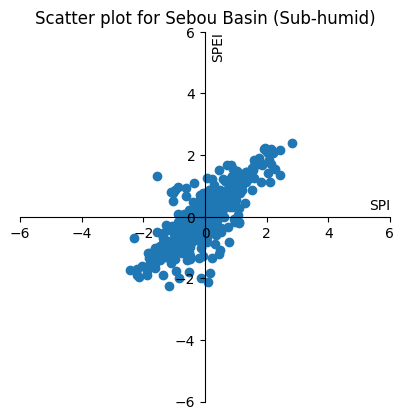

In [ ]:
x=DI_ma['SPI']
y=DI_ma['SPEI']
fig, ax = plt.subplots()
ax.scatter(x, y)
ax.set_aspect('equal')

# set the x-spine (see below for more info on `set_position`)
ax.spines['left'].set_position('zero')

# turn off the right spine/ticks
ax.spines['right'].set_color('none')
ax.yaxis.tick_left()

# set the y-spine
ax.spines['bottom'].set_position('zero')

# turn off the top spine/ticks
ax.spines['top'].set_color('none')
ax.xaxis.tick_bottom()
ax.set_ylim(-6, 6)
ax.set_xlim(-6, 6)
ax.set_title('Scatter plot for Sebou Basin (Sub-humid)')
ax.set_xlabel('SPI', loc='right', labelpad=-30)
ax.set_ylabel('SPEI', loc='top', labelpad=-36)

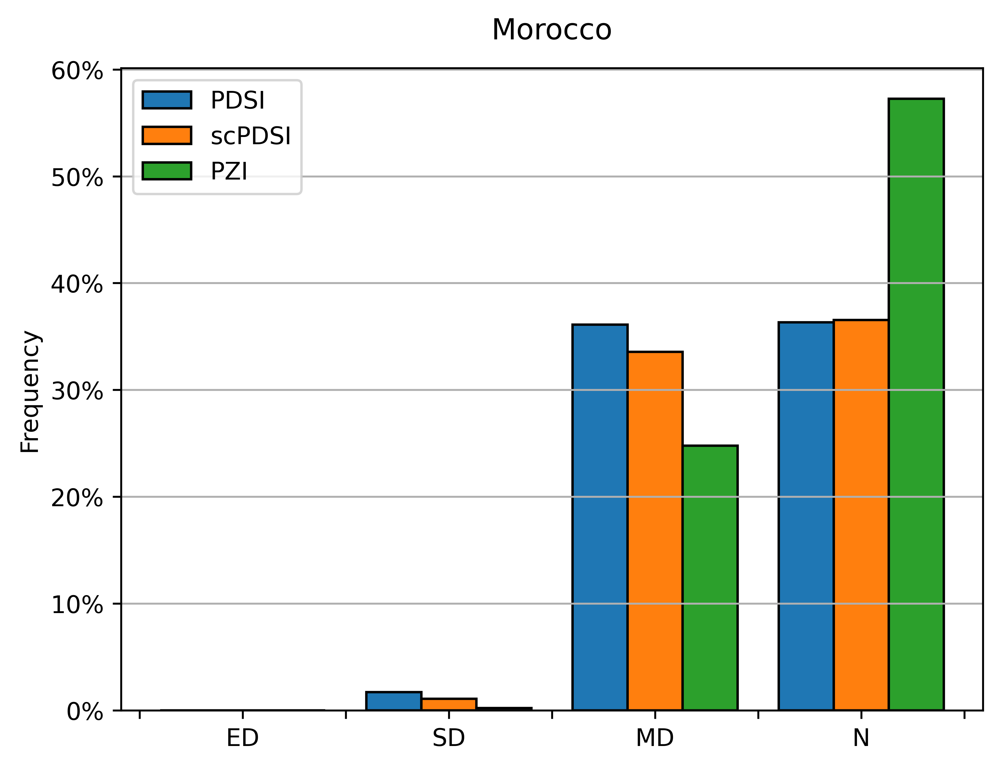

In [117]:
#create relative frequency histogram with percentages on y-axis
data = DIc_ma[['PDSI', 'scPDSI', 'PZI']]
#data = [1, 2 , 3, 0, -3, -1, -2, 0, -1, 0, 2, 2, 0, 0, -2]
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
fig = plt.figure()
ax = fig.add_subplot(111)
ax.hist(data, edgecolor='black', weights=np.ones_like(data)*100 / len(data), label=['PDSI', 'scPDSI', 'PZI'], bins=[-3,-2,-1,0,1], align='left') #, 'ZSI', 'CZI', 'SPI', 'SPEI', 'PDSI', 'scPDSI', 'PZI'
ax.set_xticklabels(['', '', 'ED', '', 'SD', '', 'MD', '', 'N'])
ax.yaxis.set_major_formatter(PercentFormatter())
ax.grid(axis='y')
ax.set_title('Morocco', pad = 12)
ax.set_ylabel('Frequency')
ax.legend()

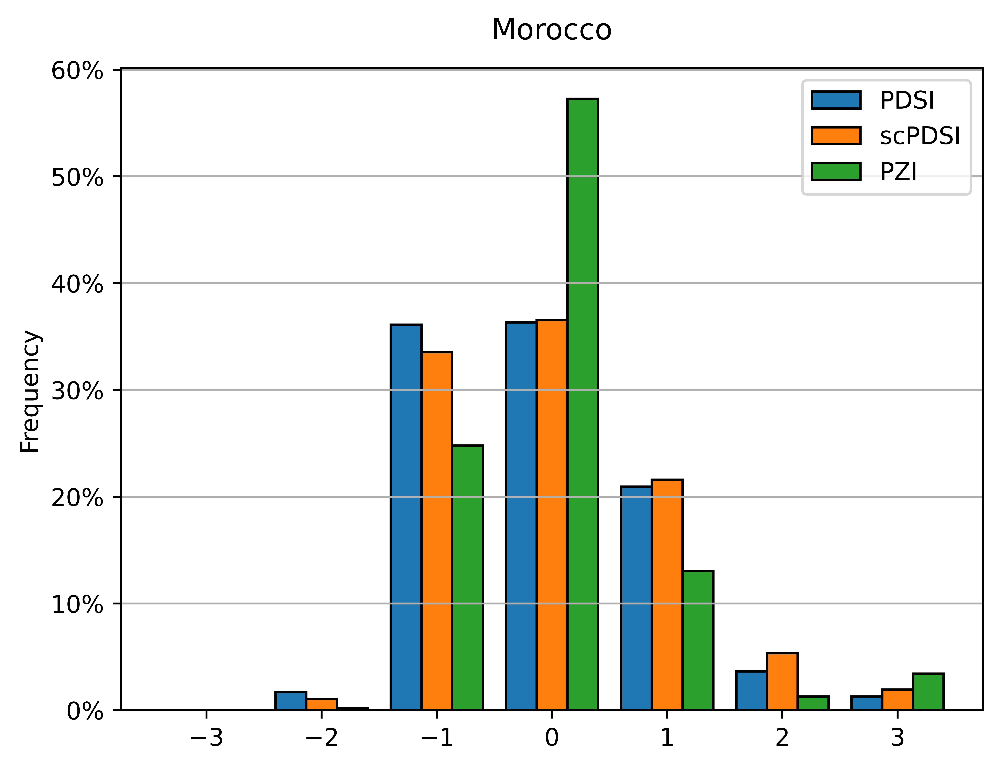

In [10]:
#create relative frequency histogram with percentages on y-axis
data = DIc_ma[['PDSI', 'scPDSI', 'PZI']]
#data = [1, 2 , 3, 0, -3, -1, -2, 0, -1, 0, 2, 2, 0, 0, -2]
plt.rcParams['figure.dpi'] = 1200
plt.rcParams['savefig.dpi'] = 1200
fig = plt.figure()
ax = fig.add_subplot(111)
ax.hist(data, edgecolor='black', weights=np.ones_like(data)*100 / len(data), label=['PDSI', 'scPDSI', 'PZI'], bins=[-3,-2,-1,0,1,2,3,4], align='left') #, 'ZSI', 'CZI', 'SPI', 'SPEI', 'PDSI', 'scPDSI', 'PZI'
ax.yaxis.set_major_formatter(PercentFormatter())
ax.grid(axis='y')
ax.set_title('Morocco', pad = 12)
ax.set_ylabel('Frequency')
ax.legend()

In [ ]:
DI_sebou.set_index("Dates", inplace = True)
DI_sebou.index = pd.to_datetime(DI_sebou.index)

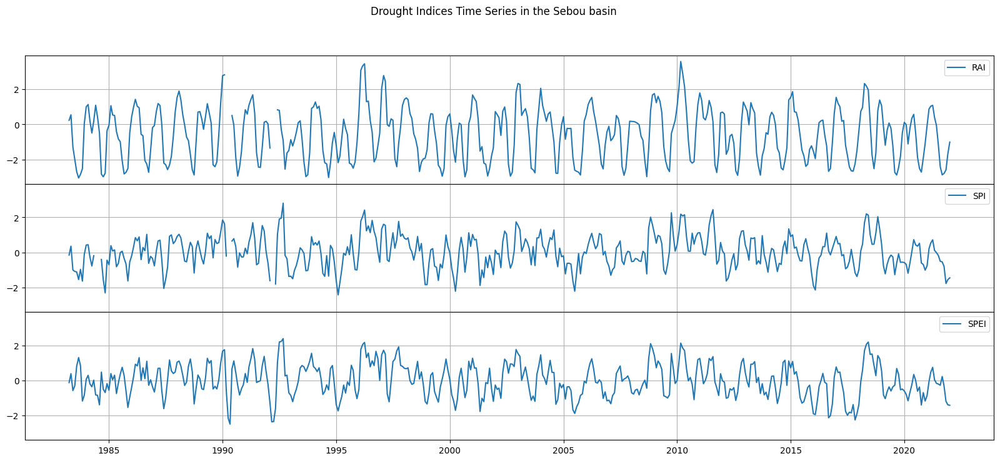

In [ ]:
datetime_series = pd.Series(pd.date_range("1983", periods=468, freq="M"))
data = DI_sebou
fig = plt.figure(figsize=(20, 8))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
fig.suptitle('Drought Indices Time Series in the Sebou basin')
axs[0].plot(datetime_series, data['RAI'], label='RAI')
axs[0].legend()
axs[1].plot(datetime_series, data['SPI'], label='SPI')
axs[1].legend()
axs[2].plot(datetime_series, data['SPEI'], label='SPEI')
axs[2].legend()

# Hide x labels and tick labels for all but bottom plot.
for ax in axs:
    ax.grid()
    ax.label_outer()

In [ ]:
data = DI_sebou
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
#fig.suptitle('Drought Indices Time Series')
axs[0].plot(data.index, data['PDSI'], label='PDSI')
axs[0].legend()
axs[1].plot(data.index, data['scPDSI'], label='scPDSI')
axs[1].legend()
axs[2].plot(data.index, data['PZI'], label='PZI')
axs[2].legend()
for ax in axs:
    ax.grid()
    ax.label_outer()

In [74]:
DI_ma[142:146]

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
142,01-11-94,2.187994,0.853379,0.549943,0.882212,0.881196,0.347097,0.553609,-0.851375,-0.224486,-1.776612
143,01-12-94,1.500000,-0.244558,-0.414377,0.185686,0.185545,-0.345184,-0.162108,-1.556717,-1.191985,-2.190074
144,01-01-95,-2.165803,-2.546906,-2.462795,-0.816135,-0.816144,-2.195984,-1.457334,-2.104968,-1.931500,-2.122837
145,01-02-95,-1.674716,-2.122492,-2.036109,-0.603315,-0.603356,-1.350187,-0.877452,-2.336941,-2.265592,-1.385675


In [127]:
DI_ma[142:146]

,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
Dates,,,,,,,,,,
01-11-94,2.187994,0.853379,0.549943,0.882212,0.881196,0.347097,0.553609,-0.851375,-0.224486,-1.776612
01-12-94,1.500000,-0.244558,-0.414377,0.185686,0.185545,-0.345184,-0.162108,-1.556717,-1.191985,-2.190074
01-01-95,-2.165803,-2.546906,-2.462795,-0.816135,-0.816144,-2.195984,-1.457334,-2.104968,-1.931500,-2.122837
01-02-95,-1.674716,-2.122492,-2.036109,-0.603315,-0.603356,-1.350187,-0.877452,-2.336941,-2.265592,-1.385675


In [79]:
#DI_ma.set_index("Dates", inplace = True)
plt.rcParams['figure.dpi'] = 1200
plt.rcParams['savefig.dpi'] = 1200
#DI_ma.index = pd.to_datetime(DI_ma.index, format='%d/%mm/%YYYY')
DI_ma[383:409].loc[:,['RAI','SPI','SPEI','PDSI','scPDSI','PZI']].plot(secondary_y=['PDSI','scPDSI', 'PZI'], mark_right=False, grid=True, figsize = (20,5), xlabel='Month')

<Axes: xlabel='Month'>

RAI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.7531271266832609, z=0.3145186859388365, Tau=0.03643724696356275, s=27.0, var_s=6833.666666666667, slope=0.0024459175446129113, intercept=-0.8083554057143629)
SPI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.30956401229803676, z=1.0161372930331638, Tau=0.11470985155195682, s=85.0, var_s=6833.666666666667, slope=0.007543718443764497, intercept=-0.13844403030471553)
SPEI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.07732844750887047, z=-1.7664018944164983, Tau=-0.19838056680161945, s=-147.0, var_s=6831.666666666667, slope=-0.01739903556371081, intercept=0.38363467516789074)
scPDSI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.2358223797536274, z=-1.1854935085386913, Tau=-0.13360323886639677, s=-99.0, var_s=6833.666666666667, slope=-0.020523388499802096, intercept=0.10625737776532479)
PZI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.45325103254848376, z=-0.7500060972387639, Tau=-0.08502024291497975, s=-63.0,

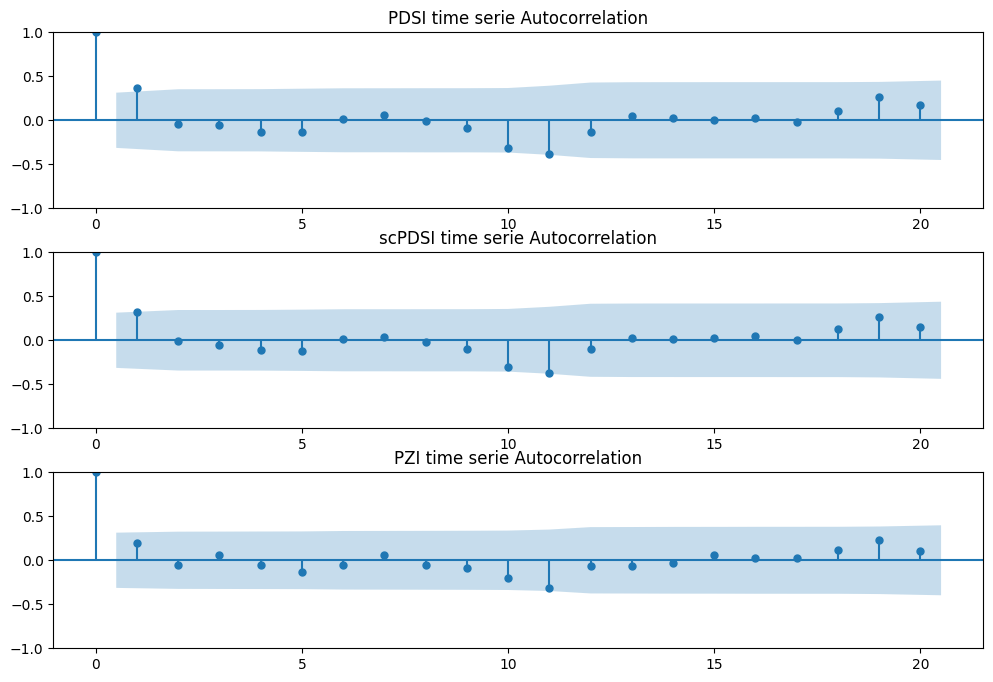

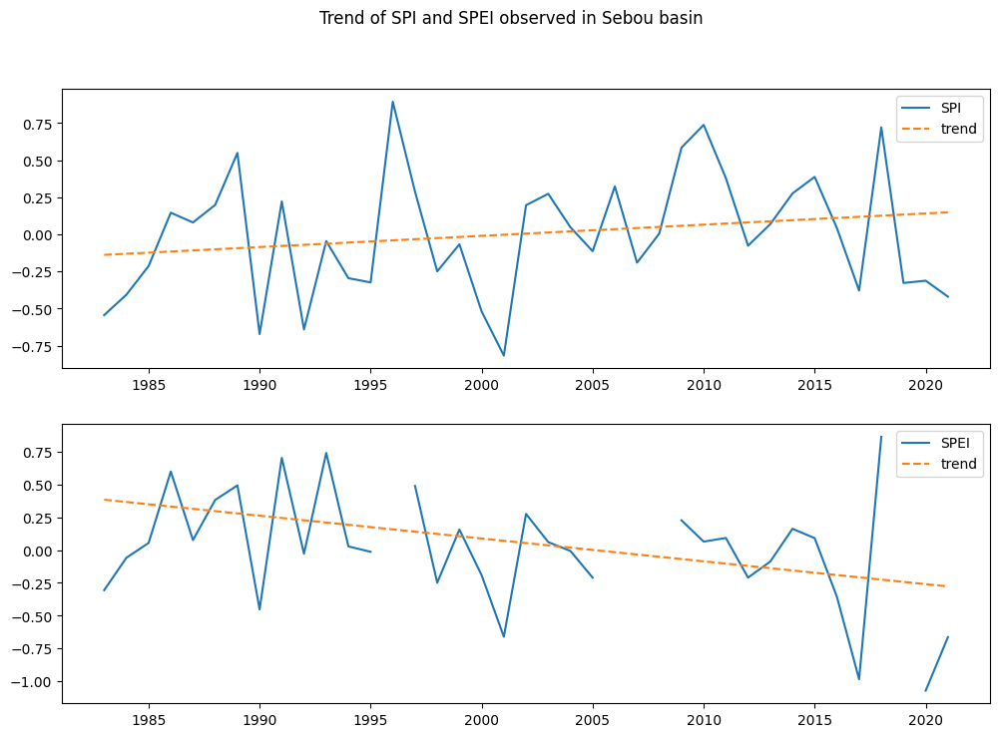

In [36]:
#trend analysis of spi and spei
arai = [np.nansum(DI_ma['RAI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspi = [np.nansum(DI_ma['SPI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspei = [np.nansum(DI_ma['SPEI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apdsi = [np.nansum(DI_ma['PDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
ascpdsi = [np.nansum(DI_ma['scPDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apzi = [np.nansum(DI_ma['PZI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

rai_trend = mk.original_test(arai)
spi_trend = mk.original_test(aspi)
spei_trend = mk.original_test(aspei)
pdsi_trend = mk.original_test(apdsi)
scpdsi_trend = mk.original_test(ascpdsi)
pzi_trend = mk.original_test(apzi)
# perform Mann-Kendall Trend Test
print('RAI : ', rai_trend)
print('SPI : ', spi_trend)
print('SPEI : ', spei_trend)
print('scPDSI : ', scpdsi_trend)
print('PZI : ', pzi_trend)

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(3, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(apdsi, lags=20, ax=axs[0], alpha=0.05, title='PDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ascpdsi, lags=20, ax=axs[1], alpha=0.05, title='scPDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(apzi, lags=20, ax=axs[2], alpha=0.05, title='PZI time serie Autocorrelation')
plt.show()

datetime_series = pd.Series(pd.date_range("1982", periods=39, freq="Y"))

fig, ax = plt.subplots(2, figsize=(12, 8))
fig.suptitle('Trend of SPI and SPEI observed in Sebou basin')
ax[0].plot(datetime_series, aspi, label='SPI')
spi_line = np.arange(len(aspi)) * spi_trend.slope + spi_trend.intercept
ax[0].plot(datetime_series, spi_line, linestyle='--', label='trend')
ax[0].legend()

ax[1].plot(datetime_series, aspei, label='SPEI')
spei_line = np.arange(len(aspei)) * spei_trend.slope + spei_trend.intercept
ax[1].plot(datetime_series, spei_line, linestyle='--', label='trend')
ax[1].legend()

plt.show()

**Sebou basin**

In [ ]:
pop = [698, 699, 700, 701, 702, 
       767, 768, 769, 770, 771, 772, 773, 774, 
       838, 839, 840, 841, 842, 843, 844, 845, 846, 847, 
       911, 912, 913, 914, 915, 916, 917, 
       984, 985, 986, 987, 988, 989, 
       1057, 1058, 1059, 1060, 1061, 
       1131]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
DI_sebou = pd.DataFrame()
DI_sebou["Dates"]=p["Dates"]
DI_sebou = DI_sebou[:-8]
DI = pd.read_csv('output/DI.csv', low_memory=False)
DI = DI.drop(['Unnamed: 0'], axis=1)
DI = DI[:-8]
DI = DI.drop(['Dates'], axis=1)
DI *= np.array(shpa)
DI = DI.replace(0, np.nan)
DI_sebou["DI"]=DI.mean(axis=1, skipna=True)
PNI = pd.read_csv('output/PNI.csv', low_memory=False)
PNI = PNI.drop(['Unnamed: 0'], axis=1)
PNI = PNI[:-8]
PNI = PNI.drop(['Dates'], axis=1)
PNI *= np.array(shpa)
PNI = PNI.replace(0, np.nan)
DI_sebou["PNI"]=PNI.mean(axis=1, skipna=True)
#DI_sebou
RAI = pd.read_csv('output/RAI.csv', low_memory=False)
RAI = RAI.drop(['Unnamed: 0'], axis=1)
RAI = RAI[:-8]
RAI = RAI.drop(['Dates'], axis=1)
RAI *= np.array(shpa)
RAI = RAI.replace(0, np.nan)
DI_sebou["RAI"]=RAI.mean(axis=1, skipna=True)
#DI_sebou
ZSI = pd.read_csv('output/ZSI.csv', low_memory=False)
ZSI = ZSI.drop(['Unnamed: 0'], axis=1)
ZSI = ZSI[:-8]
ZSI = ZSI.drop(['Dates'], axis=1)
ZSI *= np.array(shpa)
ZSI = ZSI.replace(0, np.nan)
DI_sebou["ZSI"]=ZSI.mean(axis=1, skipna=True)
#DI_sebou
CZI = pd.read_csv('output/CZI.csv', low_memory=False)
CZI = CZI.drop(['Unnamed: 0'], axis=1)
CZI = CZI[:-8]
CZI = CZI.drop(['Dates'], axis=1)
CZI *= np.array(shpa)
CZI = CZI.replace(0, np.nan)
DI_sebou["CZI"]=CZI.mean(axis=1, skipna=True)
#DI_sebou
SPI = pd.read_csv('output/spi3.csv', low_memory=False)
SPI = SPI.drop(['Unnamed: 0'], axis=1)
SPI = SPI[:-8]
SPI = SPI.drop(['Dates'], axis=1)
SPI *= np.array(shpa)
SPI = SPI.replace(0, np.nan)
DI_sebou["SPI"]=SPI.mean(axis=1, skipna=True)
#DI_sebou
SPEI = pd.read_csv('output/spei3_thorthwaite.csv', low_memory=False)
SPEI = SPEI.drop(['Unnamed: 0'], axis=1)
SPEI = SPEI[:-8]
SPEI = SPEI.drop(['Dates'], axis=1)
SPEI *= np.array(shpa)
SPEI = SPEI.replace(0, np.nan)
DI_sebou["SPEI"]=SPEI.mean(axis=1, skipna=True)
#DI_sebou
PDSI = pd.read_csv('output/PDSI.csv', low_memory=False)
PDSI = PDSI.drop(['Unnamed: 0'], axis=1)
#PDSI = PDSI[:-8]
#PDSI = PDSI.drop(['Dates'], axis=1)
PDSI *= np.array(shpa)
PDSI = PDSI.replace(0, np.nan)
DI_sebou["PDSI"]=PDSI.mean(axis=1, skipna=True)
#DI_sebou
mPDSI = pd.read_csv('output/mPDSI.csv', low_memory=False)
mPDSI = mPDSI.drop(['Unnamed: 0'], axis=1)
#mPDSI = mPDSI[:-8]
#mPDSI = mPDSI.drop(['Dates'], axis=1)
mPDSI *= np.array(shpa)
mPDSI = mPDSI.replace(0, np.nan)
DI_sebou["mPDSI"]=mPDSI.mean(axis=1, skipna=True)
#DI_sebou
PalmerZ = pd.read_csv('output/PalmerZ.csv', low_memory=False)
PalmerZ = PalmerZ.drop(['Unnamed: 0'], axis=1)
#PalmerZ = PalmerZ[:-8]
#PalmerZ = PalmerZ.drop(['Dates'], axis=1)
PalmerZ *= np.array(shpa)
PalmerZ = PalmerZ.replace(0, np.nan)
DI_sebou["PalmerZ"]=PalmerZ.mean(axis=1, skipna=True)
DI_sebou

**Sebou Basin with mask on pixel > 1000m**

In [ ]:
pop = [698, 699, 
       766, 767, 768, 769, 770, 771, 772,
       837, 838, 839, 840, 841, 842, 843, 844, 845, 
       910, 911, 912, 913, 914, 915, 
       983, 984, 985]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
annual = pd.DataFrame()
annual["Dates"]=p["Dates"]
newp = p.drop(['Dates'], axis=1)
newp *= np.array(shpa)
newp = newp.replace(0, np.nan)
annual['p'] = newp.mean(axis=1, skipna=True)

newt = t.drop(['Dates'], axis=1)
newt *= np.array(shpa)
newt = newt.replace(0, np.nan)
annual['t'] = newt.mean(axis=1, skipna=True)

pa = [np.nansum(annual['p'].to_list()[i*12:(i + 1)*12]) for i in range(39)]
ta = [sum(annual['t'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

datetime_series = pd.Series(pd.date_range("1983", periods=39, freq="Y"))
avgs = pd.DataFrame()
avgs["Dates"]=datetime_series
avgs['p'] = pa
avgs['t'] = ta
avgs.set_index("Dates", inplace = True)
avgs.index = pd.to_datetime(avgs.index, format='%Y/%m/%d')

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(2, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(pa, lags=20, ax=axs[0], alpha=0.05, title='P time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ta, lags=20, ax=axs[1], alpha=0.05, title='T time serie Autocorrelation')
plt.show()

avgs.loc[:,['p','t']].plot(secondary_y=['t'], mark_right=False, figsize = (20,5), grid=True, xlabel='Years', title='Precipitation (mm) and temperature (°C) time series in the Sebou basin')

ptrend = mk.original_test(pa)
ttrend = mk.original_test(ta)
# perform Mann-Kendall Trend Test
print('rainfall : ', ptrend)
print('temps : ', ttrend)

In [26]:
pop = [698, 699, 
       766, 767, 768, 769, 770, 771, 772,
       837, 838, 839, 840, 841, 842, 843, 844, 845, 
       910, 911, 912, 913, 914, 915, 
       983, 984, 985]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
DI_sebou = pd.DataFrame()
DI_sebou["Dates"]=p["Dates"]
DI = pd.read_csv('output/DI.csv', low_memory=False)
DI = DI.drop(['Unnamed: 0'], axis=1)
DI = DI[:-8]
DI = DI.drop(['Dates'], axis=1)
DI *= np.array(shpa)
DI = DI.replace(0, np.nan)
DI_sebou["DI"]=DI.mean(axis=1, skipna=True)
PNI = pd.read_csv('output/PNI.csv', low_memory=False)
PNI = PNI.drop(['Unnamed: 0'], axis=1)
#PNI = PNI[:-8]
PNI = PNI.drop(['Dates'], axis=1)
PNI *= np.array(shpa)
PNI = PNI.replace(0, np.nan)
DI_sebou["PNI"]=PNI.mean(axis=1, skipna=True)
RAI = pd.read_csv('output/RAI.csv', low_memory=False)
RAI = RAI.drop(['Unnamed: 0'], axis=1)
RAI = RAI[:-8]
RAI = RAI.drop(['Dates'], axis=1)
RAI *= np.array(shpa)
RAI = RAI.replace(0, np.nan)
DI_sebou["RAI"]=RAI.mean(axis=1, skipna=True)
ZSI = pd.read_csv('output/ZSI.csv', low_memory=False)
ZSI = ZSI.drop(['Unnamed: 0'], axis=1)
#ZSI = ZSI[:-8]
ZSI = ZSI.drop(['Dates'], axis=1)
ZSI *= np.array(shpa)
ZSI = ZSI.replace(0, np.nan)
DI_sebou["ZSI"]=ZSI.mean(axis=1, skipna=True)
CZI = pd.read_csv('output/CZI.csv', low_memory=False)
CZI = CZI.drop(['Unnamed: 0'], axis=1)
#CZI = CZI[:-8]
CZI = CZI.drop(['Dates'], axis=1)
CZI *= np.array(shpa)
CZI = CZI.replace(0, np.nan)
DI_sebou["CZI"]=CZI.mean(axis=1, skipna=True)
SPI = pd.read_csv('output/SPI3_R.csv', low_memory=False)
SPI = SPI.drop(['Unnamed: 0'], axis=1)
SPI = SPI.drop(['Dates'], axis=1)
SPI *= np.array(shpa)
SPI = SPI.replace(0, np.nan)
SPI = SPI.replace(-np.inf, np.nan)
DI_sebou["SPI"]=SPI.mean(axis=1, skipna=True)
SPEI = pd.read_csv('output/spei.csv', low_memory=False)
SPEI = SPEI.drop(['Unnamed: 0'], axis=1)
SPEI = SPEI[:-8]
SPEI = SPEI.drop(['Dates'], axis=1)
SPEI *= np.array(shpa)
SPEI = SPEI.replace(0, np.nan)
DI_sebou["SPEI"]=SPEI.mean(axis=1, skipna=True)
PDSI = pd.read_csv('output/PDSI.csv', low_memory=False)
PDSI = PDSI.drop(['Unnamed: 0'], axis=1)
PDSI *= np.array(shpa)
PDSI = PDSI.replace(0, np.nan)
DI_sebou["PDSI"]=PDSI.mean(axis=1, skipna=True)
mPDSI = pd.read_csv('output/mPDSI.csv', low_memory=False)
mPDSI = mPDSI.drop(['Unnamed: 0'], axis=1)
mPDSI *= np.array(shpa)
mPDSI = mPDSI.replace(0, np.nan)
DI_sebou["scPDSI"]=mPDSI.mean(axis=1, skipna=True)
PalmerZ = pd.read_csv('output/PalmerZ.csv', low_memory=False)
PalmerZ = PalmerZ.drop(['Unnamed: 0'], axis=1)
PalmerZ *= np.array(shpa)
PalmerZ = PalmerZ.replace(0, np.nan)
DI_sebou["PZI"]=PalmerZ.mean(axis=1, skipna=True)
DI_sebou

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.933192,-0.933192,-2.799576
1,01-02-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,1.123539,1.123539,3.370617
2,01-03-83,1.100000,1.000000,0.228651,0.848568,0.848554,-0.148566,-0.119493,-0.645141,-0.458213,-1.763763
3,01-04-83,1.470588,1.000000,0.543788,1.216664,1.216132,0.357410,0.390407,-0.904982,-0.835710,-0.978870
4,01-05-83,-1.000000,-1.000000,-1.292413,-0.164539,-0.164541,-1.011717,-0.571797,-0.956656,-0.895518,-0.434661
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.000000,-3.000000,-2.879971,-1.151832,-1.151625,-0.535858,0.231045,-0.899669,-0.290673,-0.436939
464,01-09-21,-3.000000,-3.000000,-2.800253,-1.112160,-1.112024,-0.795722,-0.307710,-1.188361,-0.918078,-0.983365
465,01-10-21,-2.444444,-3.000000,-2.597315,-1.015230,-1.015203,-1.772584,-1.187626,-1.971561,-1.939648,-2.716804
466,01-11-21,-1.000000,-1.444444,-1.683189,-0.569179,-0.569223,-1.549402,-1.385910,-2.236491,-2.229581,-1.404002


In [28]:
DIc_sebou = pd.DataFrame()
DIc_sebou['Dates'] = DI_sebou['Dates']
#DIc_sebou['DI'] = DI_sebou['DI'].round(0)

index = DI_sebou['DI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['DI'] = ic

DIc_sebou['PNI'] = DI_sebou['PNI'].round(0)
DIc_sebou['PNI'] = DIc_sebou['PNI'].replace(1, np.nan)

index = DI_sebou['RAI'].to_list()
ic = []
for i in index:
    if i <= -3: ic.append(-3)
    elif -3 < i <= -2 : ic.append(-2)
    elif -2 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 2 : ic.append(1)
    elif 2 < i < 3 : ic.append(2)
    elif 3 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['RAI'] = ic

index = DI_sebou['ZSI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['ZSI'] = ic

index = DI_sebou['CZI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['CZI'] = ic

index = DI_sebou['SPI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['SPI'] = ic

index = DI_sebou['SPEI'].to_list()
ic = []
for i in index:
    if i <= -1.83: ic.append(-3)
    elif -1.83 < i < -1.43 : ic.append(-2)
    elif -1.43 <= i < -1 : ic.append(-1)
    elif -1 <= i <= 1 : ic.append(0)
    elif 1 < i <= 1.43 : ic.append(1)
    elif 1.43 < i < 1.83 : ic.append(2)
    elif 1.83 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['SPEI'] = ic

index = DI_sebou['PDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['PDSI'] = ic

index = DI_sebou['scPDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['scPDSI'] = ic

index = DI_sebou['PZI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_sebou['PZI'] = ic
DIc_sebou

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,-1
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,2
2,01-03-83,1.0,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0
3,01-04-83,1.0,NaN,0.0,1.0,1.0,0.0,0.0,0,0,0
4,01-05-83,-1.0,-1.0,-1.0,0.0,0.0,-1.0,0.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.0,-3.0,-2.0,-1.0,-1.0,0.0,0.0,0,0,0
464,01-09-21,-3.0,-3.0,-2.0,-1.0,-1.0,0.0,0.0,0,0,0
465,01-10-21,-3.0,-3.0,-2.0,-1.0,-1.0,-2.0,-1.0,0,0,-1
466,01-11-21,-1.0,-1.0,-1.0,0.0,0.0,-2.0,-1.0,-1,-1,0


In [1009]:
DI_sebou.to_csv('output/DI_sebou.csv')

In [14]:
DI_sebou['rand'] = (np.random.rand(len(DI_sebou)))/5
DI_sebou['CZI'] = DI_sebou['CZI'].sub(DI_sebou['rand'])
DI_sebou['rand'] = (np.random.rand(len(DI_sebou)))/5
DI_sebou['ZSI'] = DI_sebou['ZSI'].sub(DI_sebou['rand'])
DI_sebou = DI_sebou.drop(['rand'], axis=1)

DI_sebou

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.933192,-0.933192,-2.799576
1,01-02-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,1.123539,1.123539,3.370617
2,01-03-83,1.100000,1.000000,0.228651,0.789848,0.833458,-0.148566,-0.119493,-0.645141,-0.458213,-1.763763
3,01-04-83,1.470588,1.000000,0.543788,1.178080,1.202420,0.357410,0.390407,-0.904982,-0.835710,-0.978870
4,01-05-83,-1.000000,-1.000000,-1.292413,-0.192945,-0.166254,-1.011717,-0.571797,-0.956656,-0.895518,-0.434661
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.000000,-3.000000,-2.879971,-1.229689,-1.299680,-0.535858,0.231045,-0.899669,-0.290673,-0.436939
464,01-09-21,-3.000000,-3.000000,-2.800253,-1.272141,-1.296795,-0.795722,-0.307710,-1.188361,-0.918078,-0.983365
465,01-10-21,-2.444444,-3.000000,-2.597315,-1.035984,-1.141806,-1.772584,-1.187626,-1.971561,-1.939648,-2.716804
466,01-11-21,-1.000000,-1.444444,-1.683189,-0.611357,-0.581997,-1.549402,-1.385910,-2.236491,-2.229581,-1.404002


<AxesSubplot:title={'center':'Sebou Basin (Subhumid)'}>

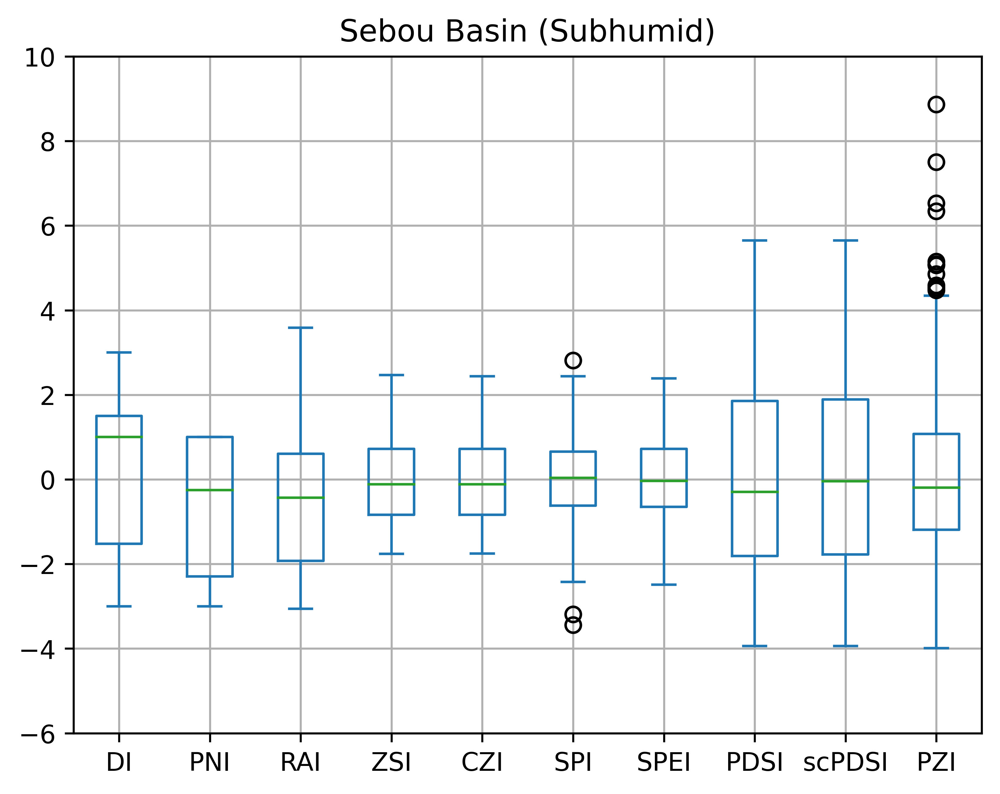

In [29]:
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
DI_sebou.plot(kind='box', title='Sebou Basin (Subhumid)', grid = True, ylim = (-6, 10))

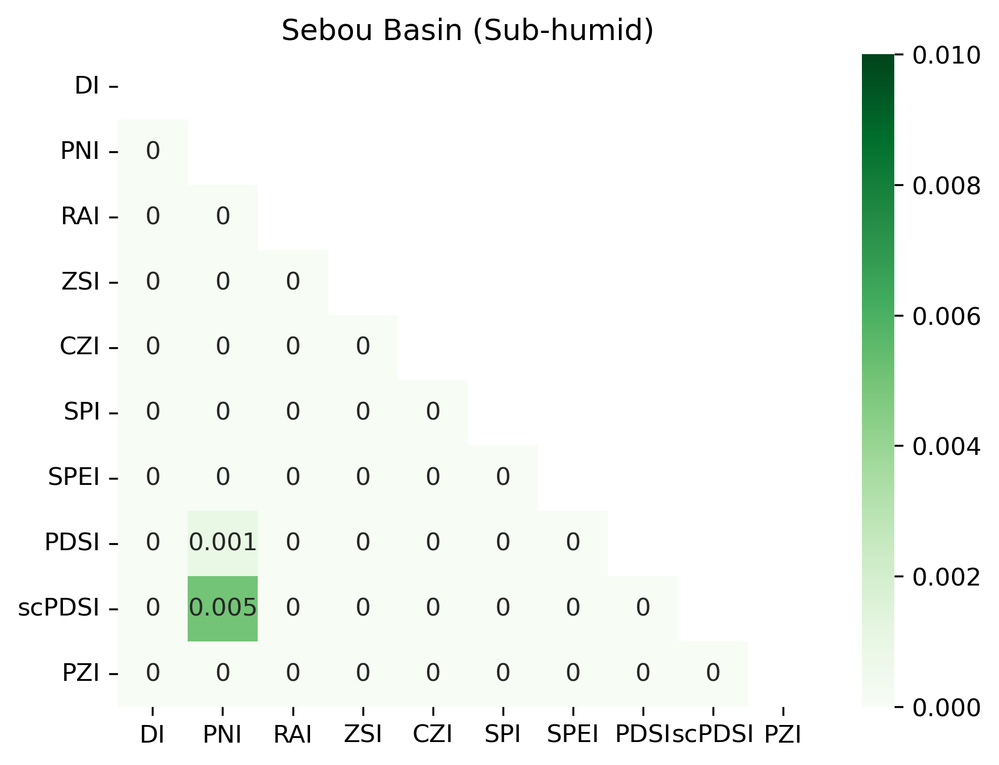

In [91]:
#DI_sebou = DI_sebou.drop(['Dates'], axis=1)
#DI_sebou.replace([np.inf, -np.inf], np.nan, inplace=True)
#DI_sebou.dropna()
pvalue = calculate_pvalues(DI_sebou)
matrix = DI_sebou.corr().round(2)
mask = np.triu(np.ones_like(matrix, dtype=bool))

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
pvalue = pvalue.astype(float).round(3)
sns.heatmap(pvalue, annot=True, vmax=0.01, cmap='Greens', mask=mask)
#sns.heatmap(matrix, annot=True, vmax=1, vmin=-1, center=0, cmap='vlag', mask=mask)
plt.title("Sebou Basin (Sub-humid)")
plt.show()

Text(0, 1, 'SPEI')

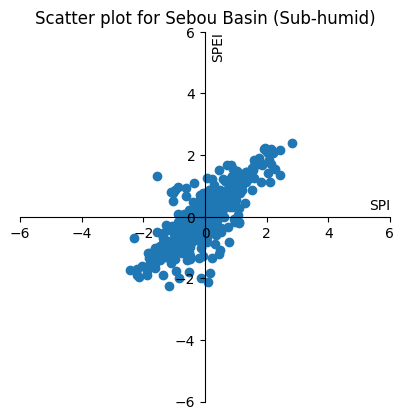

In [986]:
x=DI_sebou['SPI']
y=DI_sebou['SPEI']
fig, ax = plt.subplots()
ax.scatter(x, y)
ax.set_aspect('equal')

# set the x-spine (see below for more info on `set_position`)
ax.spines['left'].set_position('zero')

# turn off the right spine/ticks
ax.spines['right'].set_color('none')
ax.yaxis.tick_left()

# set the y-spine
ax.spines['bottom'].set_position('zero')

# turn off the top spine/ticks
ax.spines['top'].set_color('none')
ax.xaxis.tick_bottom()
ax.set_ylim(-6, 6)
ax.set_xlim(-6, 6)
ax.set_title('Scatter plot for Sebou Basin (Sub-humid)')
ax.set_xlabel('SPI', loc='right', labelpad=-30)
ax.set_ylabel('SPEI', loc='top', labelpad=-36)

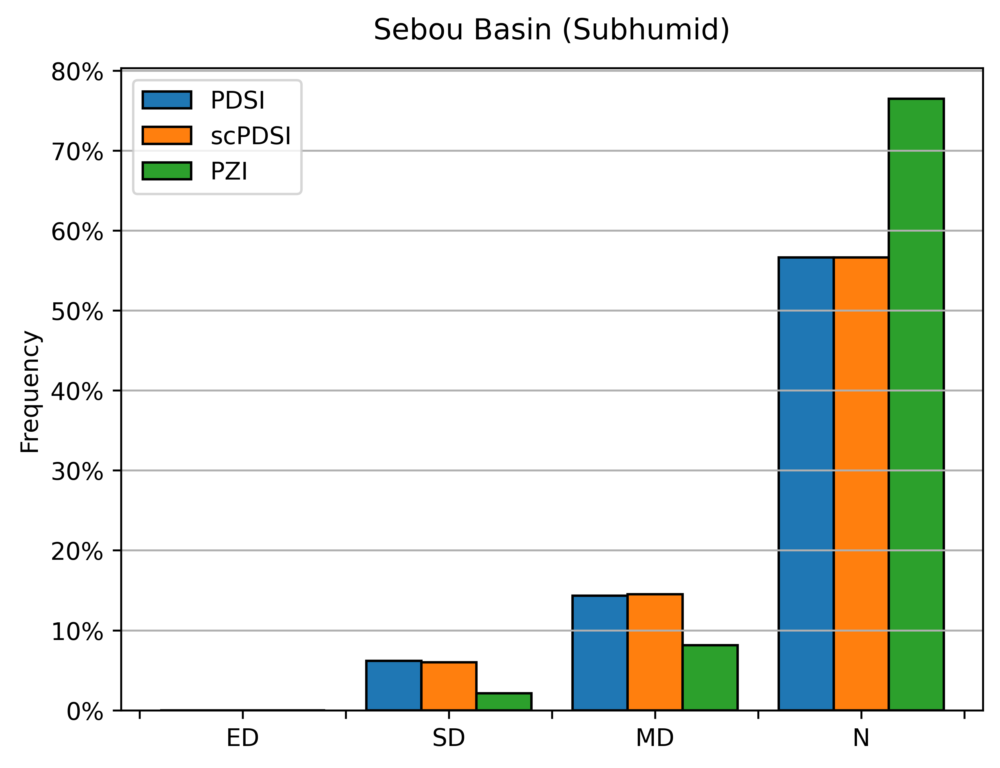

In [125]:
#create relative frequency histogram with percentages on y-axis
data = DIc_sebou[['PDSI', 'scPDSI', 'PZI']]
#data = [1, 2 , 3, 0, -3, -1, -2, 0, -1, 0, 2, 2, 0, 0, -2]
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
fig = plt.figure()
ax = fig.add_subplot(111)
ax.hist(data, edgecolor='black', weights=np.ones_like(data)*100 / len(data), label=['PDSI', 'scPDSI', 'PZI'], bins=[-3,-2,-1,0,1], align='left') #, 'ZSI', 'CZI', 'SPI', 'SPEI', 'PDSI', 'scPDSI', 'PZI'
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xticklabels(['', '', 'ED', '', 'SD', '', 'MD', '', 'N'])
ax.grid(axis='y')
ax.set_title('Sebou Basin (Subhumid)', pad = 12)
ax.set_ylabel('Frequency')
ax.legend()

In [991]:
DI_sebou.set_index("Dates", inplace = True)
DI_sebou.index = pd.to_datetime(DI_sebou.index)

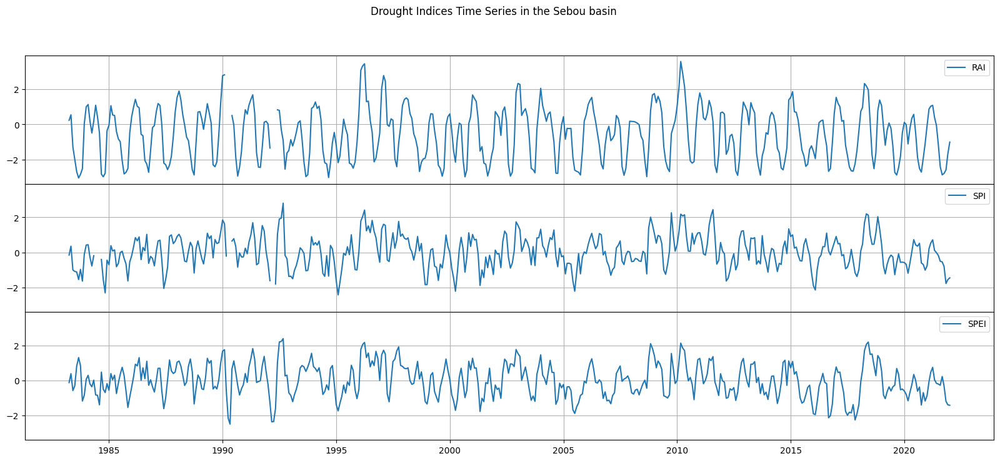

In [996]:
datetime_series = pd.Series(pd.date_range("1983", periods=468, freq="M"))
data = DI_sebou
fig = plt.figure(figsize=(20, 8))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
fig.suptitle('Drought Indices Time Series in the Sebou basin')
axs[0].plot(datetime_series, data['RAI'], label='RAI')
axs[0].legend()
axs[1].plot(datetime_series, data['SPI'], label='SPI')
axs[1].legend()
axs[2].plot(datetime_series, data['SPEI'], label='SPEI')
axs[2].legend()

# Hide x labels and tick labels for all but bottom plot.
for ax in axs:
    ax.grid()
    ax.label_outer()

In [ ]:
data = DI_sebou
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
#fig.suptitle('Drought Indices Time Series')
axs[0].plot(data.index, data['PDSI'], label='PDSI')
axs[0].legend()
axs[1].plot(data.index, data['scPDSI'], label='scPDSI')
axs[1].legend()
axs[2].plot(data.index, data['PZI'], label='PZI')
axs[2].legend()
for ax in axs:
    ax.grid()
    ax.label_outer()

In [733]:
DI_sebou[394:398]

,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
Dates,,,,,,,,,,
2015-11-01,NaN,-1.000000,-1.225764,-0.432412,-0.432436,-1.132312,-1.129152,-1.528141,-1.528141,-2.614881
2015-12-01,-1.000000,-1.259259,-1.534790,-0.589316,-0.589361,-1.900441,-1.898273,-2.585471,-2.585471,-3.644187
2016-01-01,-1.038462,-2.296296,-1.958559,-0.914368,-0.914402,-2.142553,-1.942987,-3.239650,-3.239650,-2.761445
2016-02-01,-1.000000,-1.000000,-0.858311,-0.287819,-0.287830,-1.009878,-1.246258,-2.996684,-2.945870,-0.272154


<Axes: title={'center': 'Time series of Drought Indices in Sebou basin during 2019 drought spell'}, xlabel='Months'>

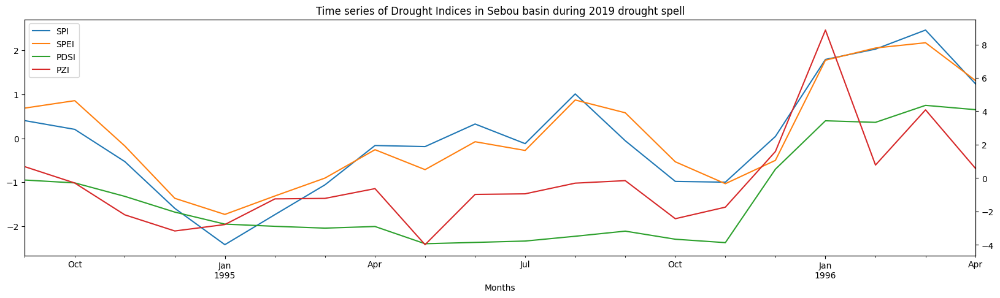

In [776]:
DI_sebou[140:160].loc[:,['SPI','SPEI','PDSI','PZI']].plot(secondary_y=['PDSI', 'PZI'], mark_right=False, figsize = (20,5), xlabel='Months', title='Time series of Drought Indices in Sebou basin during 2019 drought spell')

RAI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.5945442759036266, z=-0.5322623915888002, Tau=-0.06072874493927125, s=-45.0, var_s=6833.666666666667, slope=-0.00417011533096282, intercept=-0.5464188308007206)
SPI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.6114052024347298, z=0.5080686465165819, Tau=0.058029689608636977, s=43.0, var_s=6833.666666666667, slope=0.003160564414023759, intercept=-0.16639861979634024)
SPEI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.07339972979721177, z=-1.790337135344146, Tau=-0.20107962213225372, s=-149.0, var_s=6833.666666666667, slope=-0.011492629365016577, intercept=0.17883727679524972)
scPDSI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.2358223797536274, z=-1.1854935085386913, Tau=-0.13360323886639677, s=-99.0, var_s=6833.666666666667, slope=-0.03515823312374043, intercept=0.5782043050777238)
PZI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.08584114842248192, z=-1.7177559001274914, Tau=-0.19298245614035087, s=-143.0

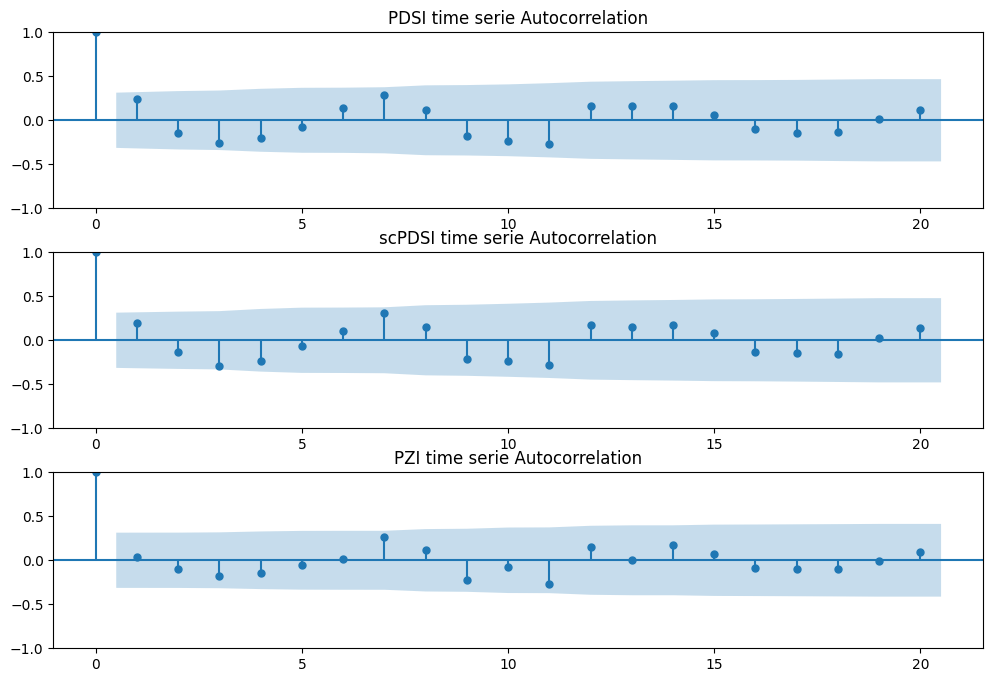

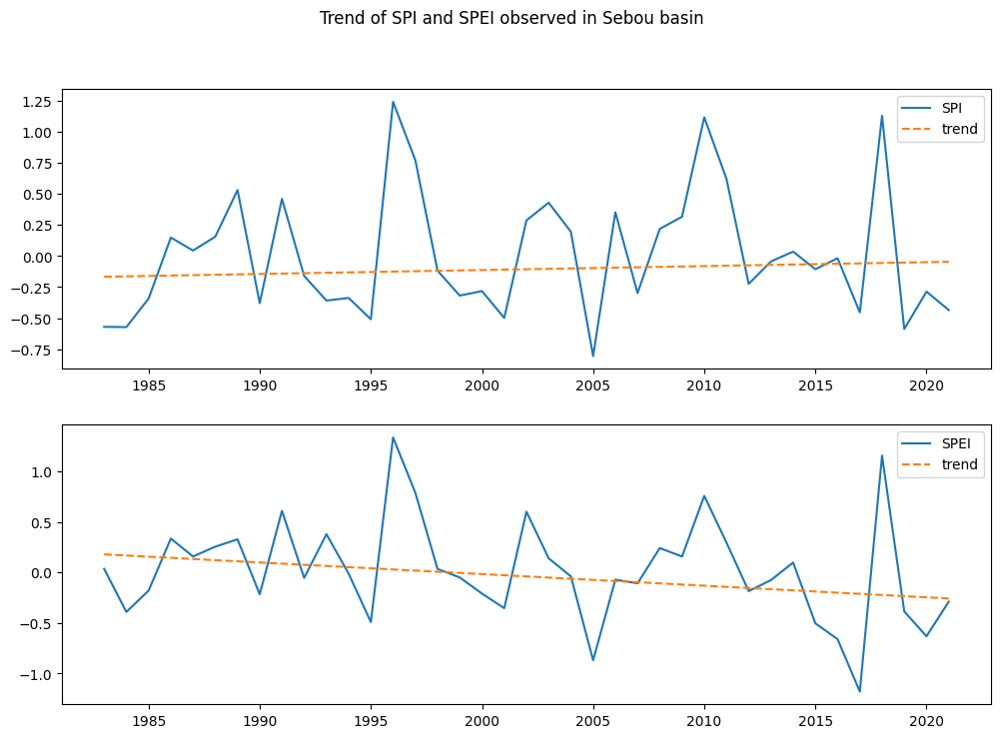

In [37]:
#trend analysis of spi and spei
arai = [np.nansum(DI_sebou['RAI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspi = [np.nansum(DI_sebou['SPI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspei = [np.nansum(DI_sebou['SPEI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apdsi = [np.nansum(DI_sebou['PDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
ascpdsi = [np.nansum(DI_sebou['scPDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apzi = [np.nansum(DI_sebou['PZI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

rai_trend = mk.original_test(arai)
spi_trend = mk.original_test(aspi)
spei_trend = mk.original_test(aspei)
pdsi_trend = mk.original_test(apdsi)
scpdsi_trend = mk.original_test(ascpdsi)
pzi_trend = mk.original_test(apzi)
# perform Mann-Kendall Trend Test
print('RAI : ', rai_trend)
print('SPI : ', spi_trend)
print('SPEI : ', spei_trend)
print('scPDSI : ', scpdsi_trend)
print('PZI : ', pzi_trend)

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(3, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(apdsi, lags=20, ax=axs[0], alpha=0.05, title='PDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ascpdsi, lags=20, ax=axs[1], alpha=0.05, title='scPDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(apzi, lags=20, ax=axs[2], alpha=0.05, title='PZI time serie Autocorrelation')
plt.show()

datetime_series = pd.Series(pd.date_range("1982", periods=39, freq="Y"))

fig, ax = plt.subplots(2, figsize=(12, 8))
fig.suptitle('Trend of SPI and SPEI observed in Sebou basin')
ax[0].plot(datetime_series, aspi, label='SPI')
spi_line = np.arange(len(aspi)) * spi_trend.slope + spi_trend.intercept
ax[0].plot(datetime_series, spi_line, linestyle='--', label='trend')
ax[0].legend()

ax[1].plot(datetime_series, aspei, label='SPEI')
spei_line = np.arange(len(aspei)) * spei_trend.slope + spei_trend.intercept
ax[1].plot(datetime_series, spei_line, linestyle='--', label='trend')
ax[1].legend()

plt.show()

**Tensift Basin with mask on pixels > 1000m**

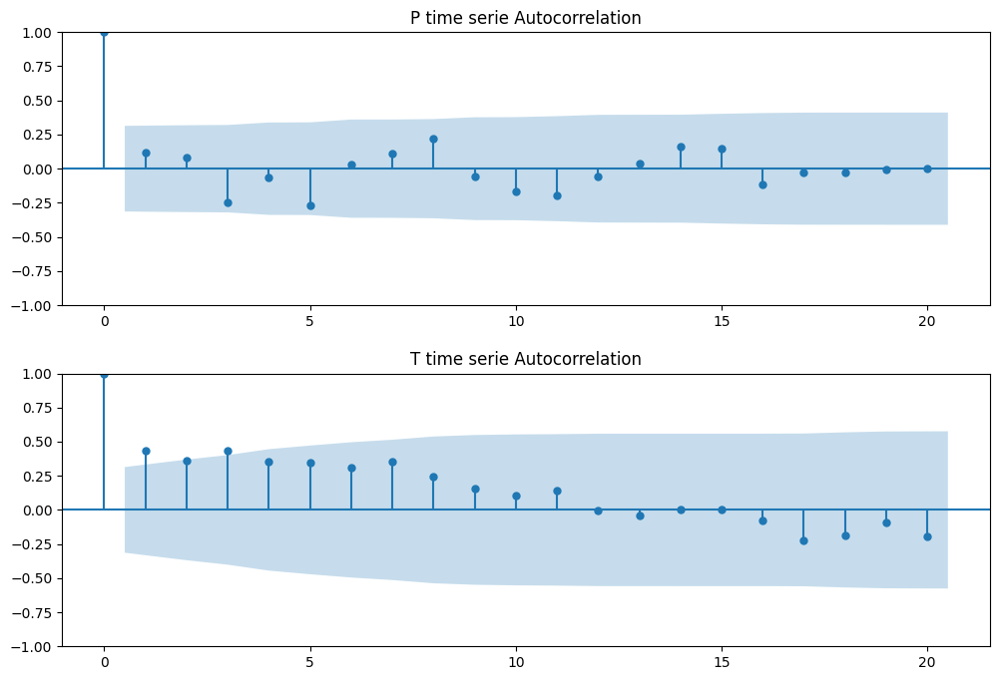

rainfall :  Mann_Kendall_Test(trend='no trend', h=False, p=0.21724725095772923, z=-1.2338809986831276, Tau=-0.13900134952766532, s=-103.0, var_s=6833.666666666667, slope=-1.3496569628211224, intercept=287.0320591447155)
temps :  Mann_Kendall_Test(trend='increasing', h=True, p=1.0231315816788822e-06, z=4.887136504588074, Tau=0.5465587044534413, s=405.0, var_s=6833.666666666667, slope=0.038038574548907786, intercept=18.3182940098528)


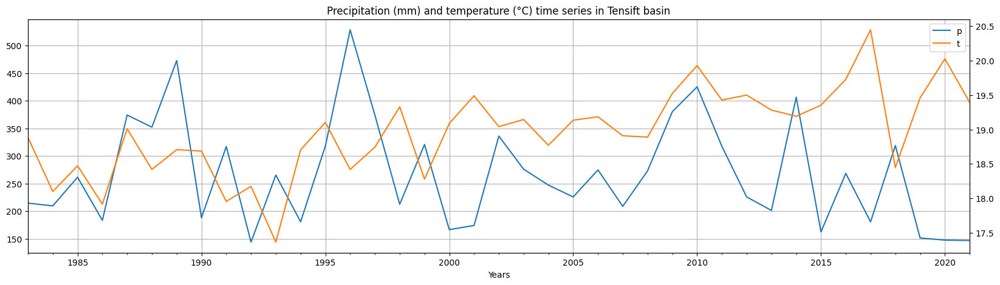

In [46]:
pop = [1477,
       1547, 1548, 1549, 1550, 1551, 1552, 1553,
       1619, 1620, 1621, 1622, 1623]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
annual = pd.DataFrame()
annual["Dates"]=p["Dates"]
newp = p.drop(['Dates'], axis=1)
newp *= np.array(shpa)
newp = newp.replace(0, np.nan)
annual['p'] = newp.mean(axis=1, skipna=True)

newt = t.drop(['Dates'], axis=1)
newt *= np.array(shpa)
newt = newt.replace(0, np.nan)
annual['t'] = newt.mean(axis=1, skipna=True)

pa = [np.nansum(annual['p'].to_list()[i*12:(i + 1)*12]) for i in range(39)]
ta = [sum(annual['t'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

datetime_series = pd.Series(pd.date_range("1983", periods=39, freq="Y"))
avgs = pd.DataFrame()
avgs["Dates"]=datetime_series
avgs['p'] = pa
avgs['t'] = ta
avgs.set_index("Dates", inplace = True)
avgs.index = pd.to_datetime(avgs.index, format='%Y/%m/%d')

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(2, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(pa, lags=20, ax=axs[0], alpha=0.05, title='P time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ta, lags=20, ax=axs[1], alpha=0.05, title='T time serie Autocorrelation')
plt.show()

avgs.loc[:,['p','t']].plot(secondary_y=['t'], mark_right=False, figsize = (20,5), grid=True, xlabel='Years', title='Precipitation (mm) and temperature (°C) time series in Tensift basin')

ptrend = mk.original_test(pa)
ttrend = mk.original_test(ta)
# perform Mann-Kendall Trend Test
print('rainfall : ', ptrend)
print('temps : ', ttrend)

In [30]:
pop = [1477,
       1547, 1548, 1549, 1550, 1551, 1552, 1553,
       1619, 1620, 1621, 1622, 1623]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
DI_tensift = pd.DataFrame()
DI_tensift["Dates"]=p["Dates"]
DI = pd.read_csv('output/DI.csv', low_memory=False)
DI = DI.drop(['Unnamed: 0'], axis=1)
DI = DI[:-8]
DI = DI.drop(['Dates'], axis=1)
DI *= np.array(shpa)
DI = DI.replace(0, np.nan)
DI_tensift["DI"]=DI.mean(axis=1, skipna=True)
PNI = pd.read_csv('output/PNI.csv', low_memory=False)
PNI = PNI.drop(['Unnamed: 0'], axis=1)
#PNI = PNI[:-8]
PNI = PNI.drop(['Dates'], axis=1)
PNI *= np.array(shpa)
PNI = PNI.replace(0, np.nan)
DI_tensift["PNI"]=PNI.mean(axis=1, skipna=True)
RAI = pd.read_csv('output/RAI.csv', low_memory=False)
RAI = RAI.drop(['Unnamed: 0'], axis=1)
RAI = RAI[:-8]
RAI = RAI.drop(['Dates'], axis=1)
RAI *= np.array(shpa)
RAI = RAI.replace(0, np.nan)
DI_tensift["RAI"]=RAI.mean(axis=1, skipna=True)
ZSI = pd.read_csv('output/ZSI.csv', low_memory=False)
ZSI = ZSI.drop(['Unnamed: 0'], axis=1)
#ZSI = ZSI[:-8]
ZSI = ZSI.drop(['Dates'], axis=1)
ZSI *= np.array(shpa)
ZSI = ZSI.replace(0, np.nan)
DI_tensift["ZSI"]=ZSI.mean(axis=1, skipna=True)
CZI = pd.read_csv('output/CZI.csv', low_memory=False)
CZI = CZI.drop(['Unnamed: 0'], axis=1)
#CZI = CZI[:-8]
CZI = CZI.drop(['Dates'], axis=1)
CZI *= np.array(shpa)
CZI = CZI.replace(0, np.nan)
DI_tensift["CZI"]=CZI.mean(axis=1, skipna=True)
SPI = pd.read_csv('output/SPI3_R.csv', low_memory=False)
SPI = SPI.drop(['Unnamed: 0'], axis=1)
SPI = SPI.drop(['Dates'], axis=1)
SPI *= np.array(shpa)
SPI = SPI.replace(0, np.nan)
SPI = SPI.replace(-np.inf, np.nan)
DI_tensift["SPI"]=SPI.mean(axis=1, skipna=True)
SPEI = pd.read_csv('output/spei.csv', low_memory=False)
SPEI = SPEI.drop(['Unnamed: 0'], axis=1)
SPEI = SPEI[:-8]
SPEI = SPEI.drop(['Dates'], axis=1)
SPEI *= np.array(shpa)
SPEI = SPEI.replace(0, np.nan)
DI_tensift["SPEI"]=SPEI.mean(axis=1, skipna=True)
PDSI = pd.read_csv('output/PDSI.csv', low_memory=False)
PDSI = PDSI.drop(['Unnamed: 0'], axis=1)
PDSI *= np.array(shpa)
PDSI = PDSI.replace(0, np.nan)
DI_tensift["PDSI"]=PDSI.mean(axis=1, skipna=True)
mPDSI = pd.read_csv('output/mPDSI.csv', low_memory=False)
mPDSI = mPDSI.drop(['Unnamed: 0'], axis=1)
mPDSI *= np.array(shpa)
mPDSI = mPDSI.replace(0, np.nan)
DI_tensift["scPDSI"]=mPDSI.mean(axis=1, skipna=True)
PalmerZ = pd.read_csv('output/PalmerZ.csv', low_memory=False)
PalmerZ = PalmerZ.drop(['Unnamed: 0'], axis=1)
PalmerZ *= np.array(shpa)
PalmerZ = PalmerZ.replace(0, np.nan)
DI_tensift["PZI"]=PalmerZ.mean(axis=1, skipna=True)
DI_tensift

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.850896,-0.850896,-2.552689
1,01-02-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.443737,0.443737,1.523993
2,01-03-83,NaN,1.000000,0.146360,0.816568,0.816596,-0.437423,-0.607345,-1.084055,-1.084055,-2.565271
3,01-04-83,1.000000,1.000000,0.222876,0.943934,0.943875,-0.192261,-0.368510,-1.794608,-1.794608,-2.466632
4,01-05-83,NaN,-1.000000,-1.678299,-0.327750,-0.327763,-1.146464,-0.947906,-1.913811,-1.913811,-0.912142
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.000000,-3.000000,-2.942431,-0.970301,-0.970308,-0.879114,-0.255884,-3.736202,-3.736202,-0.452698
464,01-09-21,-2.923077,-3.000000,-2.814719,-0.895720,-0.895767,-0.707271,-0.702612,-3.618085,-3.618085,-0.800135
465,01-10-21,-2.923077,-3.000000,-2.799088,-0.886728,-0.886778,-1.561841,-1.077091,-4.005120,-4.005120,-2.279095
466,01-11-21,-1.000000,-1.384615,-2.016920,-0.431850,-0.431874,-1.318611,-1.128440,-4.048464,-4.048464,-1.367612


In [1012]:
DI_tensift.to_csv('output/DI_tensift.csv')

In [31]:
DIc_tensift = pd.DataFrame()
DIc_tensift['Dates'] = DI_tensift['Dates']
#DIc_tensift['DI'] = DI_tensift['DI'].round(0)

index = DI_tensift['DI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['DI'] = ic

DIc_tensift['PNI'] = DI_tensift['PNI'].round(0)
DIc_tensift['PNI'] = DIc_tensift['PNI'].replace(1, np.nan)

index = DI_tensift['RAI'].to_list()
ic = []
for i in index:
    if i <= -3: ic.append(-3)
    elif -3 < i <= -2 : ic.append(-2)
    elif -2 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 2 : ic.append(1)
    elif 2 < i < 3 : ic.append(2)
    elif 3 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['RAI'] = ic

index = DI_tensift['ZSI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['ZSI'] = ic

index = DI_tensift['CZI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['CZI'] = ic

index = DI_tensift['SPI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['SPI'] = ic

index = DI_tensift['SPEI'].to_list()
ic = []
for i in index:
    if i <= -1.83: ic.append(-3)
    elif -1.83 < i < -1.43 : ic.append(-2)
    elif -1.43 <= i < -1 : ic.append(-1)
    elif -1 <= i <= 1 : ic.append(0)
    elif 1 < i <= 1.43 : ic.append(1)
    elif 1.43 < i < 1.83 : ic.append(2)
    elif 1.83 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['SPEI'] = ic

index = DI_tensift['PDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['PDSI'] = ic

index = DI_tensift['scPDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['scPDSI'] = ic

index = DI_tensift['PZI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_tensift['PZI'] = ic
DIc_tensift

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,-1
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0
2,01-03-83,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,0,-1
3,01-04-83,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0,0,-1
4,01-05-83,NaN,-1.0,-1.0,0.0,0.0,-1.0,0.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.0,-3.0,-2.0,0.0,0.0,0.0,0.0,-2,-2,0
464,01-09-21,-3.0,-3.0,-2.0,0.0,0.0,0.0,0.0,-2,-2,0
465,01-10-21,-3.0,-3.0,-2.0,0.0,0.0,-2.0,-1.0,-3,-3,-1
466,01-11-21,-1.0,-1.0,-2.0,0.0,0.0,-1.0,-1.0,-3,-3,0


In [17]:
DI_tensift['rand'] = (np.random.rand(len(DI_tensift)))/5
DI_tensift['CZI'] = DI_tensift['CZI'].sub(DI_tensift['rand'])
DI_tensift['rand'] = (np.random.rand(len(DI_tensift)))/5
DI_tensift['ZSI'] = DI_tensift['ZSI'].sub(DI_tensift['rand'])
DI_tensift = DI_tensift.drop(['rand'], axis=1)

DI_tensift

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.850896,-0.850896,-2.552689
1,01-02-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.443737,0.443737,1.523993
2,01-03-83,NaN,1.000000,0.146360,0.731499,0.702058,-0.437423,-0.607345,-1.084055,-1.084055,-2.565271
3,01-04-83,1.000000,1.000000,0.222876,0.744454,0.855191,-0.192261,-0.368510,-1.794608,-1.794608,-2.466632
4,01-05-83,NaN,-1.000000,-1.678299,-0.427991,-0.403050,-1.146464,-0.947906,-1.913811,-1.913811,-0.912142
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.000000,-3.000000,-2.942431,-1.010994,-1.161425,-0.879114,-0.255884,-3.736202,-3.736202,-0.452698
464,01-09-21,-2.923077,-3.000000,-2.814719,-0.901240,-0.991991,-0.707271,-0.702612,-3.618085,-3.618085,-0.800135
465,01-10-21,-2.923077,-3.000000,-2.799088,-1.014409,-0.892827,-1.561841,-1.077091,-4.005120,-4.005120,-2.279095
466,01-11-21,-1.000000,-1.384615,-2.016920,-0.502144,-0.581178,-1.318611,-1.128440,-4.048464,-4.048464,-1.367612


<AxesSubplot:title={'center':'Tensift Basin (Semi-arid)'}, ylabel='Value'>

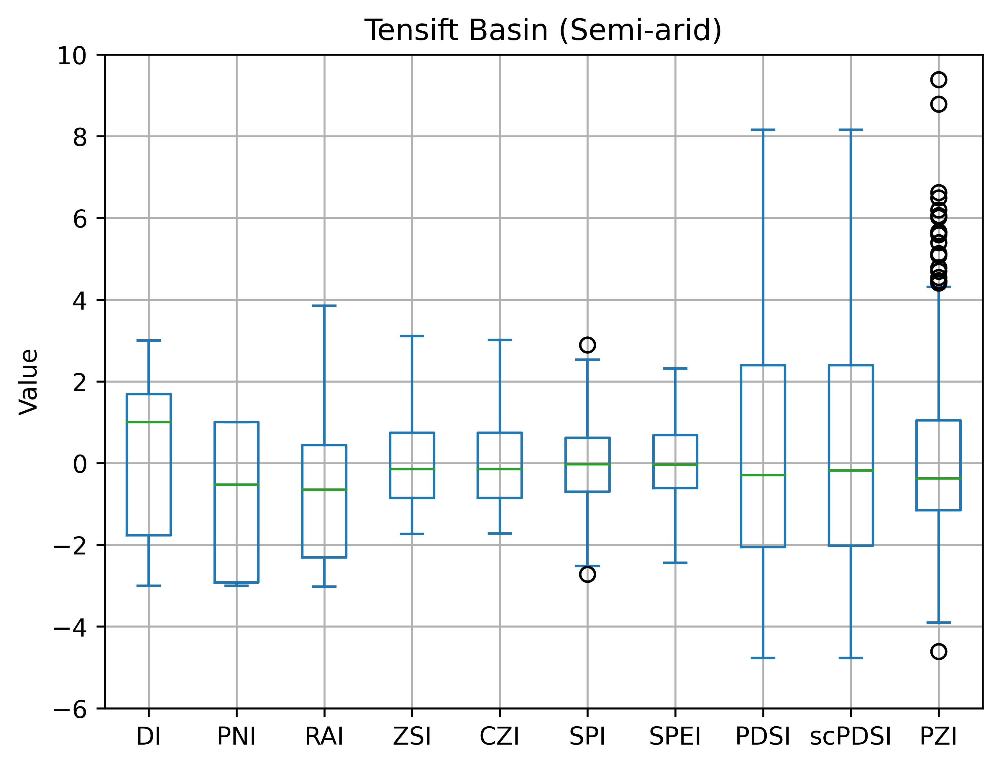

In [27]:
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
DI_tensift.plot(kind='box', title='Tensift Basin (Semi-arid)', grid = True, ylim = (-6, 10), ylabel='Value')

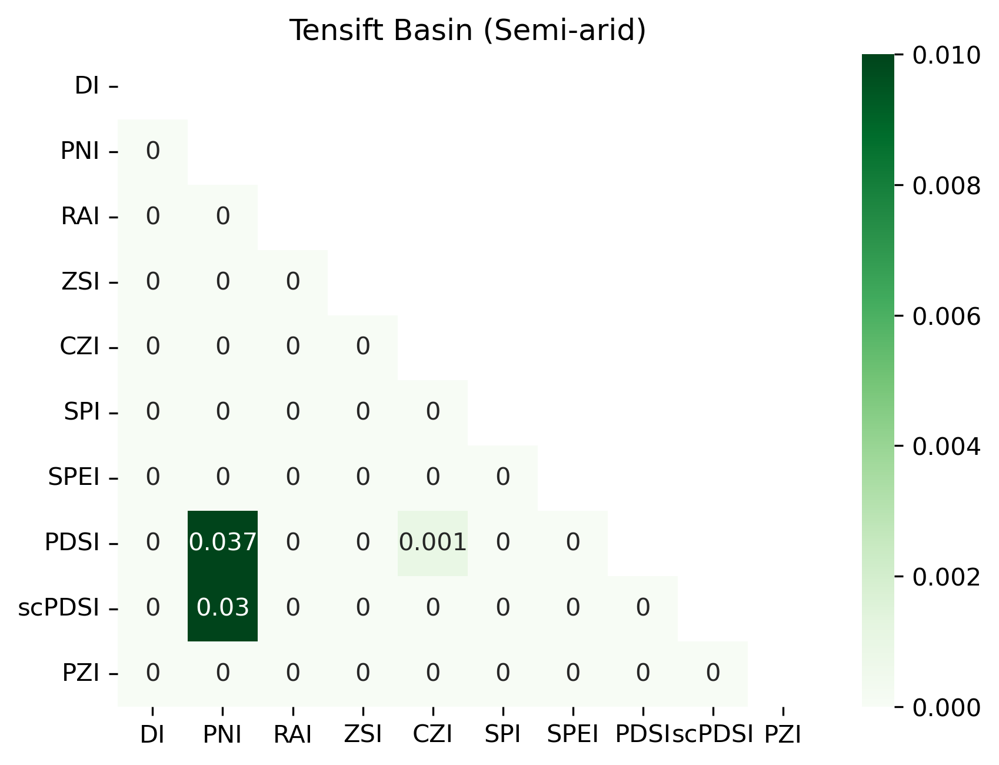

In [94]:
#DI_tensift = DI_tensift.drop(['Dates'], axis=1)
#DI_tensift.replace([np.inf, -np.inf], np.nan, inplace=True)
#DI_tensift.dropna()
pvalue = calculate_pvalues(DI_tensift)
matrix = DI_tensift.corr().round(2)
mask = np.triu(np.ones_like(matrix, dtype=bool))

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
pvalue = pvalue.astype(float).round(3)
sns.heatmap(pvalue, annot=True, vmax=0.01, cmap='Greens', mask=mask)
#sns.heatmap(matrix, annot=True, vmax=1, vmin=-1, center=0, cmap='vlag', mask=mask)
plt.title("Tensift Basin (Semi-arid)")
plt.show()

Text(0, 1, 'PZI')

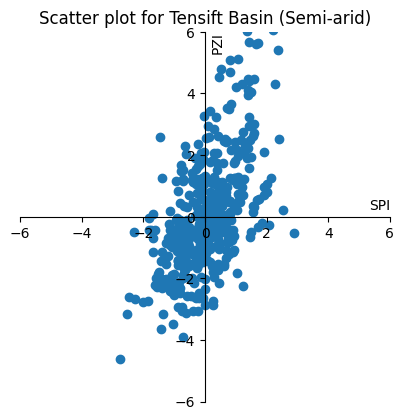

In [61]:
x=DI_tensift['SPI']
y=DI_tensift['PZI']
fig, ax = plt.subplots()
ax.scatter(x, y)
ax.set_aspect('equal')

# set the x-spine (see below for more info on `set_position`)
ax.spines['left'].set_position('zero')

# turn off the right spine/ticks
ax.spines['right'].set_color('none')
ax.yaxis.tick_left()

# set the y-spine
ax.spines['bottom'].set_position('zero')

# turn off the top spine/ticks
ax.spines['top'].set_color('none')
ax.xaxis.tick_bottom()
ax.set_ylim(-6, 6)
ax.set_xlim(-6, 6)
ax.set_title('Scatter plot for Tensift Basin (Semi-arid)')
ax.set_xlabel('SPI', loc='right', labelpad=-30)
ax.set_ylabel('PZI', loc='top', labelpad=-36)

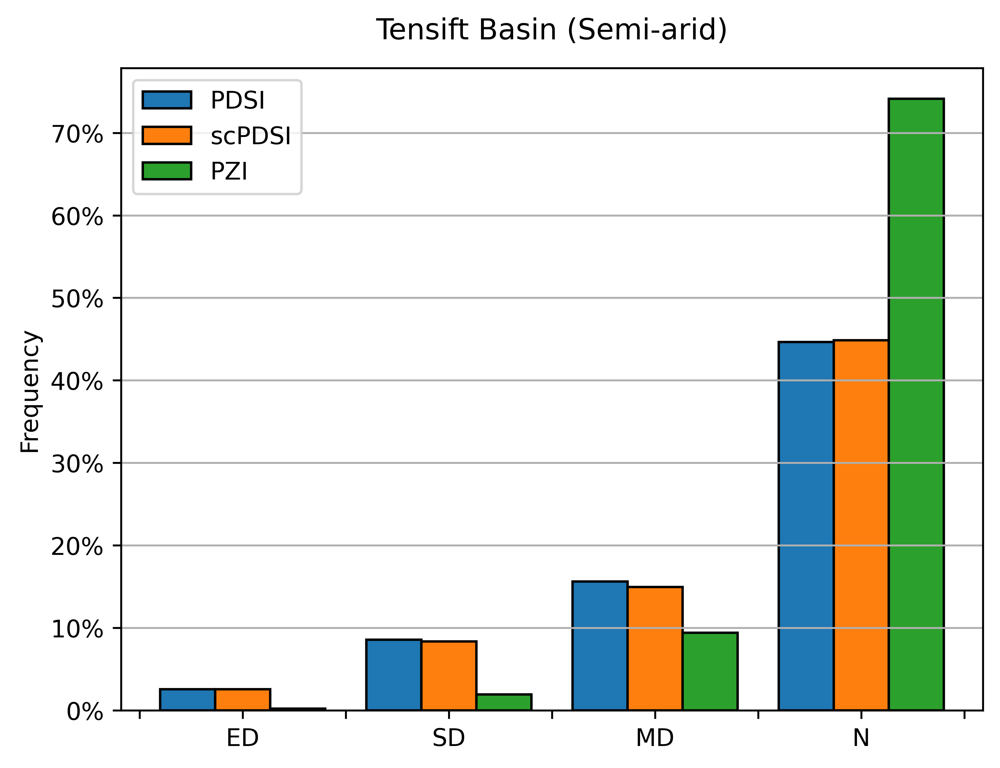

In [131]:
#create relative frequency histogram with percentages on y-axis
data = DIc_tensift[['PDSI', 'scPDSI', 'PZI']]
#data = [1, 2 , 3, 0, -3, -1, -2, 0, -1, 0, 2, 2, 0, 0, -2]
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
fig = plt.figure()
ax = fig.add_subplot(111)
ax.hist(data, edgecolor='black', weights=np.ones_like(data)*100 / len(data), label=['PDSI', 'scPDSI', 'PZI'], bins=[-3,-2,-1,0,1], align='left') #, 'ZSI', 'CZI', 'SPI', 'SPEI', 'PDSI', 'scPDSI', 'PZI'
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xticklabels(['', '', 'ED', '', 'SD', '', 'MD', '', 'N'])
ax.grid(axis='y')
ax.set_title('Tensift Basin (Semi-arid)', pad = 12)
ax.set_ylabel('Frequency')
ax.legend()

In [417]:
DI_tensift.set_index("Dates", inplace = True)
DI_tensift.index = pd.to_datetime(DI_tensift.index, format='%Y/%m/%d')

In [ ]:

data = DI_tensift
fig = plt.figure(figsize=(20, 8))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
fig.suptitle('Drought Indices Time Series in the Tensift basin')
axs[0].plot(data.index, data['RAI'], label='RAI')
axs[0].legend()
axs[1].plot(data.index, data['SPI'], label='SPI')
axs[1].legend()
axs[2].plot(data.index, data['SPEI'], label='SPEI')
axs[2].legend()
#axs[3].plot(data.index, data['PDSI'])
#axs[4].plot(data.index, data['scPDSI'])
#axs[5].plot(data.index, data['PZI'])
#axs[2].plot(x, y, '+')

# Hide x labels and tick labels for all but bottom plot.
for ax in axs:
    ax.grid()
    ax.label_outer()

In [ ]:
data = DI_tensift
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
#fig.suptitle('Drought Indices Time Series')
axs[0].plot(data.index, data['PDSI'], label='PDSI')
axs[0].legend()
axs[1].plot(data.index, data['scPDSI'], label='scPDSI')
axs[1].legend()
axs[2].plot(data.index, data['PZI'], label='PZI')
axs[2].legend()
for ax in axs:
    ax.grid()
    ax.label_outer()

<Axes: title={'center': 'Time series of Drought Indices in Tensift basin during 2019 drought spell'}, xlabel='Months'>

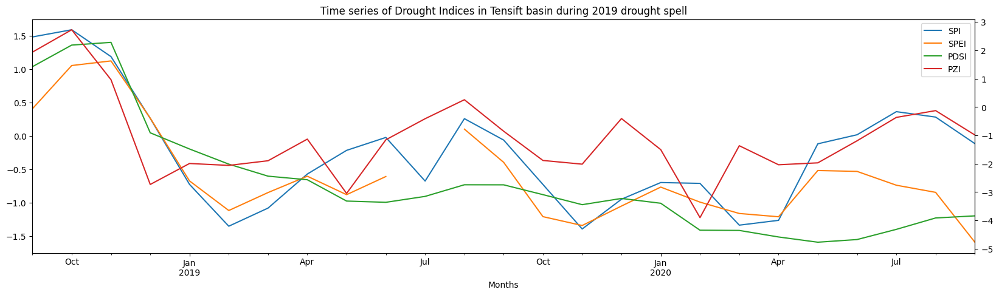

In [658]:
DI_tensift[428:453].loc[:,['SPI','SPEI','PDSI','PZI']].plot(secondary_y=['PDSI', 'PZI'], mark_right=False, figsize = (20,5), xlabel='Months', title='Time series of Drought Indices in Tensift basin during 2019 drought spell')

RAI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.6457450970456375, z=-0.45968115637214557, Tau=-0.05263157894736842, s=-39.0, var_s=6833.666666666667, slope=-0.00414645401124647, intercept=-0.7347267065524163)
SPI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.9806980673807666, z=-0.02419374507221819, Tau=-0.004048582995951417, s=-3.0, var_s=6833.666666666667, slope=-0.00037054419489068735, intercept=-0.09627467207771719)
SPEI :  Mann_Kendall_Test(trend='decreasing', h=True, p=0.012704186640628334, z=-2.4919557424384733, Tau=-0.2793522267206478, s=-207.0, var_s=6833.666666666667, slope=-0.022342802810880795, intercept=0.4316676370340211)
scPDSI :  Mann_Kendall_Test(trend='decreasing', h=True, p=0.022953240882480408, z=-2.2742120367885095, Tau=-0.2550607287449393, s=-189.0, var_s=6833.666666666667, slope=-0.07686847299094558, intercept=1.1712913428721916)
PZI :  Mann_Kendall_Test(trend='decreasing', h=True, p=0.03530386033195576, z=-2.104855821282982, Tau=-0.2361673414304993

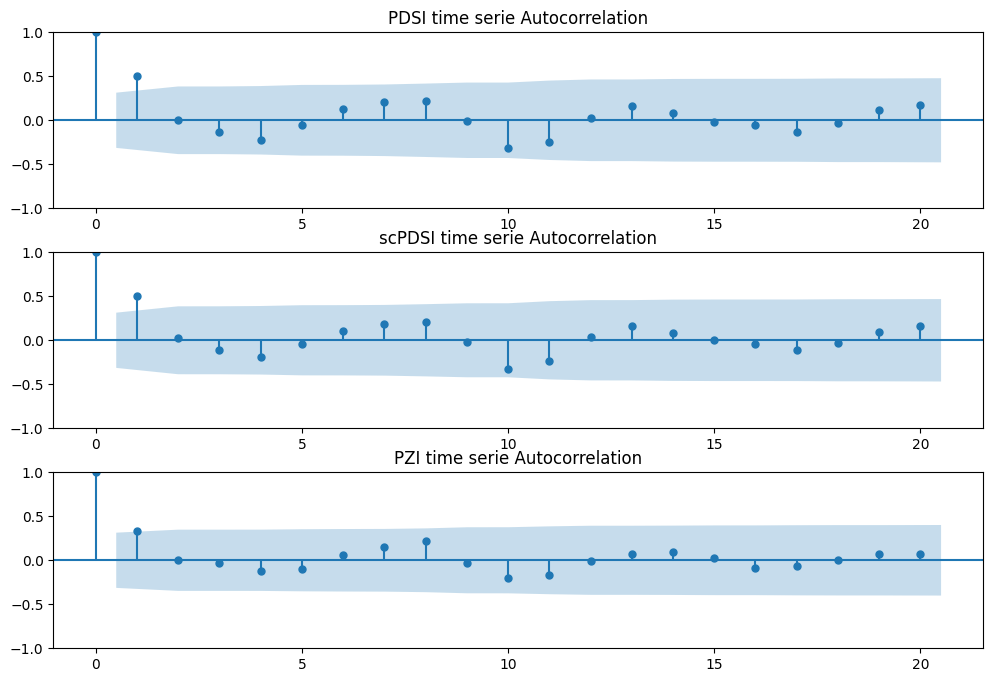

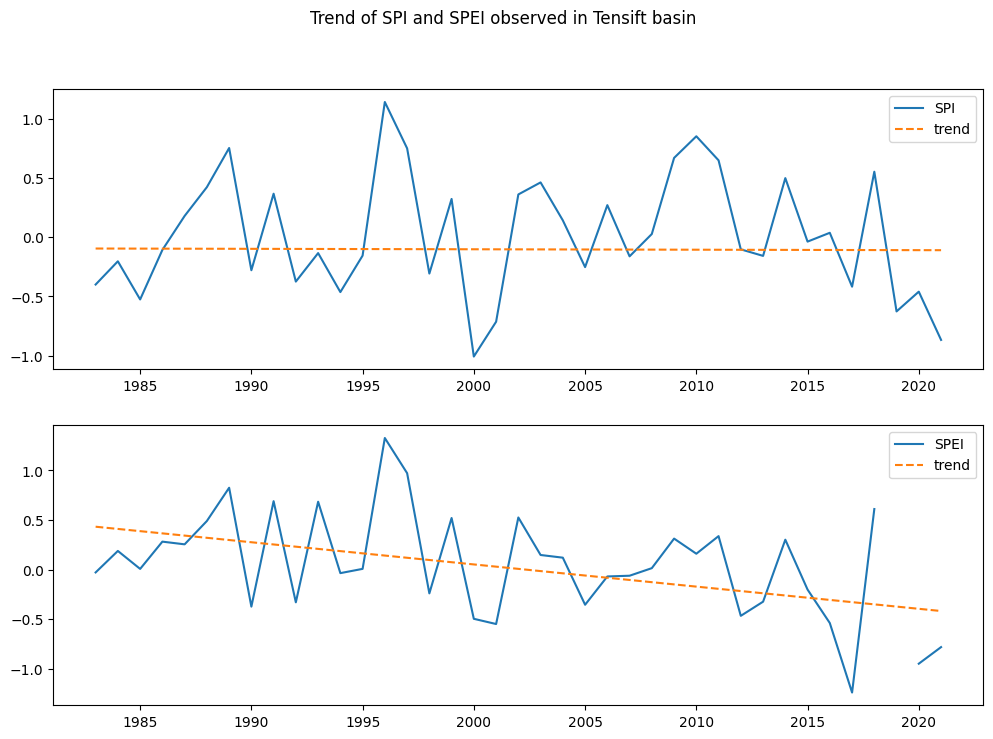

In [38]:
#trend analysis of spi and spei
arai = [np.nansum(DI_tensift['RAI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspi = [np.nansum(DI_tensift['SPI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspei = [np.nansum(DI_tensift['SPEI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apdsi = [np.nansum(DI_tensift['PDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
ascpdsi = [np.nansum(DI_tensift['scPDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apzi = [np.nansum(DI_tensift['PZI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

rai_trend = mk.original_test(arai)
spi_trend = mk.original_test(aspi)
spei_trend = mk.original_test(aspei)
pdsi_trend = mk.original_test(apdsi)
scpdsi_trend = mk.original_test(ascpdsi)
pzi_trend = mk.original_test(apzi)
# perform Mann-Kendall Trend Test
print('RAI : ', rai_trend)
print('SPI : ', spi_trend)
print('SPEI : ', spei_trend)
print('scPDSI : ', scpdsi_trend)
print('PZI : ', pzi_trend)

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(3, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(apdsi, lags=20, ax=axs[0], alpha=0.05, title='PDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ascpdsi, lags=20, ax=axs[1], alpha=0.05, title='scPDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(apzi, lags=20, ax=axs[2], alpha=0.05, title='PZI time serie Autocorrelation')
plt.show()

datetime_series = pd.Series(pd.date_range("1982", periods=39, freq="Y"))

fig, ax = plt.subplots(2, figsize=(12, 8))
fig.suptitle('Trend of SPI and SPEI observed in Tensift basin')
ax[0].plot(datetime_series, aspi, label='SPI')
spi_line = np.arange(len(aspi)) * spi_trend.slope + spi_trend.intercept
ax[0].plot(datetime_series, spi_line, linestyle='--', label='trend')
ax[0].legend()

ax[1].plot(datetime_series, aspei, label='SPEI')
spei_line = np.arange(len(aspei)) * spei_trend.slope + spei_trend.intercept
ax[1].plot(datetime_series, spei_line, linestyle='--', label='trend')
ax[1].legend()

plt.show()

**Sous-Massa Basin with mask on pixels > 1000m**

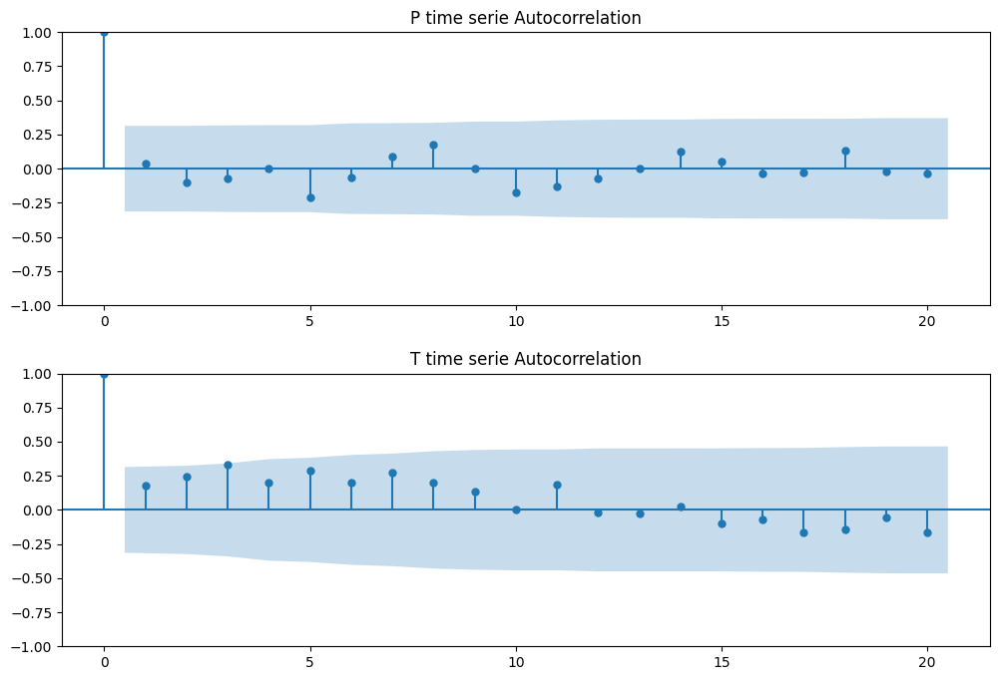

rainfall :  Mann_Kendall_Test(trend='no trend', h=False, p=0.1534557123832827, z=-1.4274309592608732, Tau=-0.16059379217273953, s=-119.0, var_s=6833.666666666667, slope=-1.1869588436527787, intercept=181.76183416712104)
temps :  Mann_Kendall_Test(trend='increasing', h=True, p=0.0001456226035256858, z=3.7984179763382557, Tau=0.4251012145748988, s=315.0, var_s=6833.666666666667, slope=0.028385407696759124, intercept=19.801279374131944)


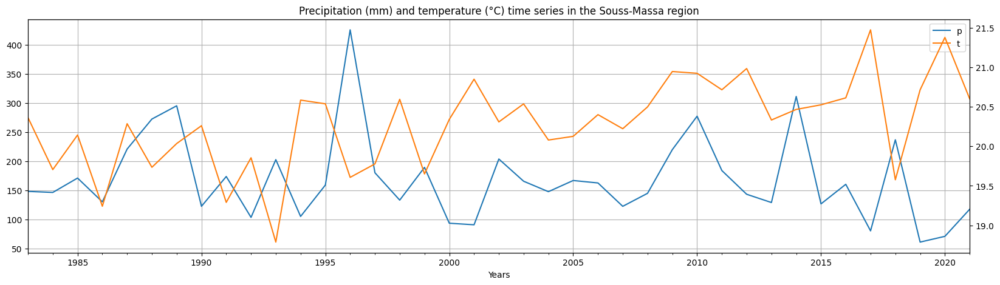

In [7]:
pop = [1906, 1907, 1908,
       1977, 1978, 1979,
       2049, 2050,
       2121]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
annual = pd.DataFrame()
annual["Dates"]=p["Dates"]
newp = p.drop(['Dates'], axis=1)
newp *= np.array(shpa)
newp = newp.replace(0, np.nan)
annual['p'] = newp.mean(axis=1, skipna=True)

newt = t.drop(['Dates'], axis=1)
newt *= np.array(shpa)
newt = newt.replace(0, np.nan)
annual['t'] = newt.mean(axis=1, skipna=True)

pa = [np.nansum(annual['p'].to_list()[i*12:(i + 1)*12]) for i in range(39)]
ta = [sum(annual['t'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

datetime_series = pd.Series(pd.date_range("1983", periods=39, freq="Y"))
avgs = pd.DataFrame()
avgs["Dates"]=datetime_series
avgs['p'] = pa
avgs['t'] = ta
avgs.set_index("Dates", inplace = True)
avgs.index = pd.to_datetime(avgs.index, format='%Y/%m/%d')

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(2, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(pa, lags=20, ax=axs[0], alpha=0.05, title='P time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ta, lags=20, ax=axs[1], alpha=0.05, title='T time serie Autocorrelation')
plt.show()

avgs.loc[:,['p','t']].plot(secondary_y=['t'], mark_right=False, figsize = (20,5), grid=True, xlabel='Years', title='Precipitation (mm) and temperature (°C) time series in the Souss-Massa region')

ptrend = mk.original_test(pa)
ttrend = mk.original_test(ta)
# perform Mann-Kendall Trend Test
print('rainfall : ', ptrend)
print('temps : ', ttrend)

In [32]:
pop = [1906, 1907, 1908,
       1977, 1978, 1979,
       2049, 2050,
       2121]
shpa = []
for i in range(4824):
    if i in pop : shpa.append(1)
    else: shpa.append(0)
DI_souss = pd.DataFrame()
DI_souss["Dates"]=p["Dates"]
DI = pd.read_csv('output/DI.csv', low_memory=False)
DI = DI.drop(['Unnamed: 0'], axis=1)
DI = DI[:-8]
DI = DI.drop(['Dates'], axis=1)
DI *= np.array(shpa)
DI = DI.replace(0, np.nan)
DI_souss["DI"]=DI.mean(axis=1, skipna=True)
PNI = pd.read_csv('output/PNI.csv', low_memory=False)
PNI = PNI.drop(['Unnamed: 0'], axis=1)
#PNI = PNI[:-8]
PNI = PNI.drop(['Dates'], axis=1)
PNI *= np.array(shpa)
PNI = PNI.replace(0, np.nan)
DI_souss["PNI"]=PNI.mean(axis=1, skipna=True)
RAI = pd.read_csv('output/RAI.csv', low_memory=False)
RAI = RAI.drop(['Unnamed: 0'], axis=1)
RAI = RAI[:-8]
RAI = RAI.drop(['Dates'], axis=1)
RAI *= np.array(shpa)
RAI = RAI.replace(0, np.nan)
DI_souss["RAI"]=RAI.mean(axis=1, skipna=True)
ZSI = pd.read_csv('output/ZSI.csv', low_memory=False)
ZSI = ZSI.drop(['Unnamed: 0'], axis=1)
#ZSI = ZSI[:-8]
ZSI = ZSI.drop(['Dates'], axis=1)
ZSI *= np.array(shpa)
ZSI = ZSI.replace(0, np.nan)
DI_souss["ZSI"]=ZSI.mean(axis=1, skipna=True)
CZI = pd.read_csv('output/CZI.csv', low_memory=False)
CZI = CZI.drop(['Unnamed: 0'], axis=1)
#CZI = CZI[:-8]
CZI = CZI.drop(['Dates'], axis=1)
CZI *= np.array(shpa)
CZI = CZI.replace(0, np.nan)
DI_souss["CZI"]=CZI.mean(axis=1, skipna=True)
SPI = pd.read_csv('output/SPI3_R.csv', low_memory=False)
SPI = SPI.drop(['Unnamed: 0'], axis=1)
SPI = SPI.drop(['Dates'], axis=1)
SPI *= np.array(shpa)
SPI = SPI.replace(0, np.nan)
SPI = SPI.replace(-np.inf, np.nan)
DI_souss["SPI"]=SPI.mean(axis=1, skipna=True)
SPEI = pd.read_csv('output/spei.csv', low_memory=False)
SPEI = SPEI.drop(['Unnamed: 0'], axis=1)
SPEI = SPEI[:-8]
SPEI = SPEI.drop(['Dates'], axis=1)
SPEI *= np.array(shpa)
SPEI = SPEI.replace(0, np.nan)
DI_souss["SPEI"]=SPEI.mean(axis=1, skipna=True)
PDSI = pd.read_csv('output/PDSI.csv', low_memory=False)
PDSI = PDSI.drop(['Unnamed: 0'], axis=1)
PDSI *= np.array(shpa)
PDSI = PDSI.replace(0, np.nan)
DI_souss["PDSI"]=PDSI.mean(axis=1, skipna=True)
mPDSI = pd.read_csv('output/mPDSI.csv', low_memory=False)
mPDSI = mPDSI.drop(['Unnamed: 0'], axis=1)
mPDSI *= np.array(shpa)
mPDSI = mPDSI.replace(0, np.nan)
DI_souss["scPDSI"]=mPDSI.mean(axis=1, skipna=True)
PalmerZ = pd.read_csv('output/PalmerZ.csv', low_memory=False)
PalmerZ = PalmerZ.drop(['Unnamed: 0'], axis=1)
PalmerZ *= np.array(shpa)
PalmerZ = PalmerZ.replace(0, np.nan)
DI_souss["PZI"]=PalmerZ.mean(axis=1, skipna=True)
DI_souss

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.560349,-0.560349,-1.681047
1,01-02-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.637784,0.637784,2.082263
2,01-03-83,1.142857,1.000000,0.293107,1.081355,1.081194,-0.014453,-0.509182,-0.937699,-0.937699,-2.669648
3,01-04-83,1.000000,1.000000,0.241017,0.983064,0.983016,0.214851,-0.405119,-1.267659,-1.267659,-1.279628
4,01-05-83,-1.000000,-2.000000,-1.988796,-0.661787,-0.661844,-0.921476,-1.039600,-1.287695,-1.287695,-0.451817
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-2.222222,-2.888889,-2.620688,-0.753598,-0.753661,0.005778,0.419250,-2.045780,-1.682598,0.004728
464,01-09-21,-1.777778,-2.888889,-2.499890,-0.699395,-0.699455,-0.402978,-0.063534,-2.152428,-1.959495,-0.952088
465,01-10-21,-2.111111,-3.000000,-2.634039,-0.763461,-0.763526,-1.077639,-0.381156,-2.622493,-2.582422,-2.075297
466,01-11-21,NaN,-1.555556,-1.853563,-0.422127,-0.422150,-0.921396,-0.766552,-2.658475,-2.651097,-0.918295


In [1013]:
DI_souss.to_csv('output/DI_souss.csv')

In [33]:
DIc_souss = pd.DataFrame()
DIc_souss['Dates'] = DI_souss['Dates']
#DIc_souss['DI'] = DI_souss['DI'].round(0)

index = DI_souss['DI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['DI'] = ic

DIc_souss['PNI'] = DI_souss['PNI'].round(0)
DIc_souss['PNI'] = DIc_souss['PNI'].replace(1, np.nan)

index = DI_souss['RAI'].to_list()
ic = []
for i in index:
    if i <= -3: ic.append(-3)
    elif -3 < i <= -2 : ic.append(-2)
    elif -2 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 2 : ic.append(1)
    elif 2 < i < 3 : ic.append(2)
    elif 3 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['RAI'] = ic

index = DI_souss['ZSI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['ZSI'] = ic

index = DI_souss['CZI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['CZI'] = ic

index = DI_souss['SPI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i < 2 : ic.append(2)
    elif 2 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['SPI'] = ic

index = DI_souss['SPEI'].to_list()
ic = []
for i in index:
    if i <= -1.83: ic.append(-3)
    elif -1.83 < i < -1.43 : ic.append(-2)
    elif -1.43 <= i < -1 : ic.append(-1)
    elif -1 <= i <= 1 : ic.append(0)
    elif 1 < i <= 1.43 : ic.append(1)
    elif 1.43 < i < 1.83 : ic.append(2)
    elif 1.83 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['SPEI'] = ic

index = DI_souss['PDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['PDSI'] = ic

index = DI_souss['scPDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['scPDSI'] = ic

index = DI_souss['PZI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -2 : ic.append(-1)
    elif -2 < i <= 2 : ic.append(0)
    elif 2 < i <= 3 : ic.append(1)
    elif 3 < i < 4 : ic.append(2)
    elif 4 <= i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['PZI'] = ic
DIc_souss

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0
1,01-02-83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,1
2,01-03-83,1.0,NaN,0.0,1.0,1.0,0.0,0.0,0,0,-1
3,01-04-83,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0
4,01-05-83,-1.0,-2.0,-1.0,0.0,0.0,0.0,-1.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-3.0,-3.0,-2.0,0.0,0.0,0.0,0.0,-1,0,0
464,01-09-21,-2.0,-3.0,-2.0,0.0,0.0,0.0,0.0,-1,0,0
465,01-10-21,-3.0,-3.0,-2.0,0.0,0.0,-1.0,0.0,-1,-1,-1
466,01-11-21,NaN,-2.0,-1.0,0.0,0.0,0.0,0.0,-1,-1,0


In [24]:
DI_souss['rand'] = (np.random.rand(len(DI_souss)))/5
DI_souss['CZI'] = DI_souss['CZI'].sub(DI_souss['rand'])
DI_souss['rand'] = (np.random.rand(len(DI_souss)))/5
DI_souss['ZSI'] = DI_souss['ZSI'].sub(DI_souss['rand'])
DI_souss = DI_souss.drop(['rand'], axis=1)

DI_souss

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
0,01-01-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.560349,-0.560349,-1.681047
1,01-02-83,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.637784,0.637784,2.082263
2,01-03-83,1.142857,1.000000,0.293107,0.996534,0.987205,-0.014453,-0.509182,-0.937699,-0.937699,-2.669648
3,01-04-83,1.000000,1.000000,0.241017,0.800054,0.857905,0.214851,-0.405119,-1.267659,-1.267659,-1.279628
4,01-05-83,-1.000000,-2.000000,-1.988796,-0.823748,-0.813830,-0.921476,-1.039600,-1.287695,-1.287695,-0.451817
...,...,...,...,...,...,...,...,...,...,...,...
463,01-08-21,-2.222222,-2.888889,-2.620688,-0.853175,-0.911437,0.005778,0.419250,-2.045780,-1.682598,0.004728
464,01-09-21,-1.777778,-2.888889,-2.499890,-0.881730,-0.721900,-0.402978,-0.063534,-2.152428,-1.959495,-0.952088
465,01-10-21,-2.111111,-3.000000,-2.634039,-0.809109,-0.907632,-1.077639,-0.381156,-2.622493,-2.582422,-2.075297
466,01-11-21,NaN,-1.555556,-1.853563,-0.470219,-0.591211,-0.921396,-0.766552,-2.658475,-2.651097,-0.918295


<AxesSubplot:title={'center':'Souss-Massa Basin (Arid)'}>

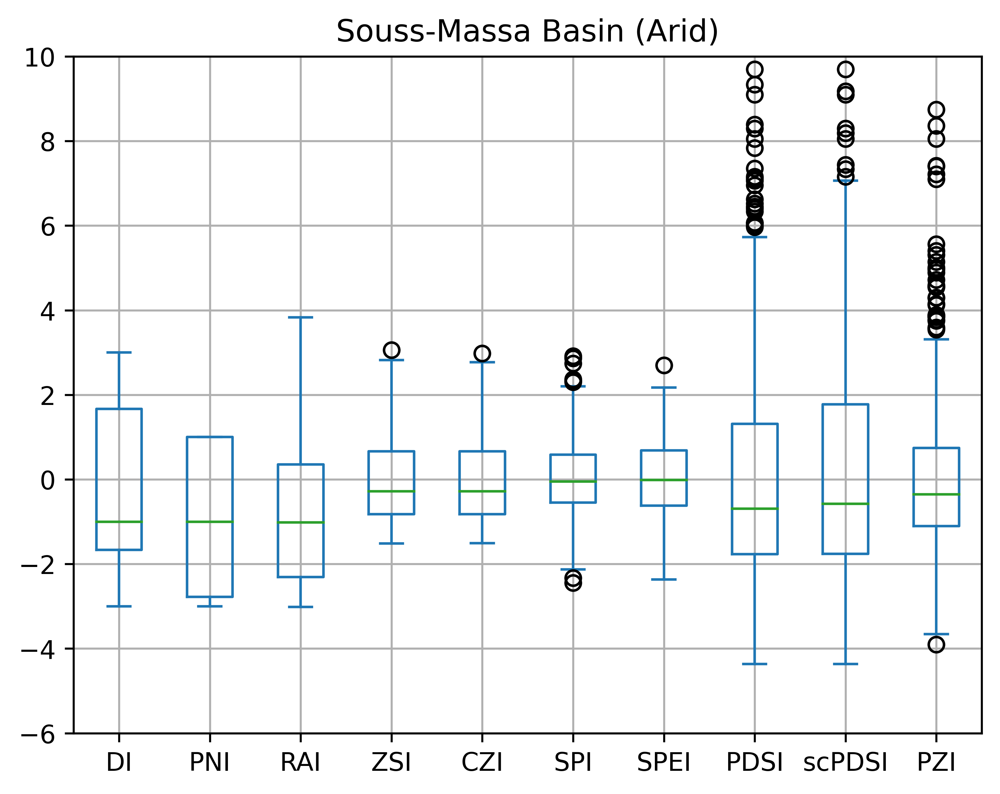

In [34]:
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
DI_souss.plot(kind='box', title='Souss-Massa Basin (Arid)', grid = True, ylim = (-6, 10))

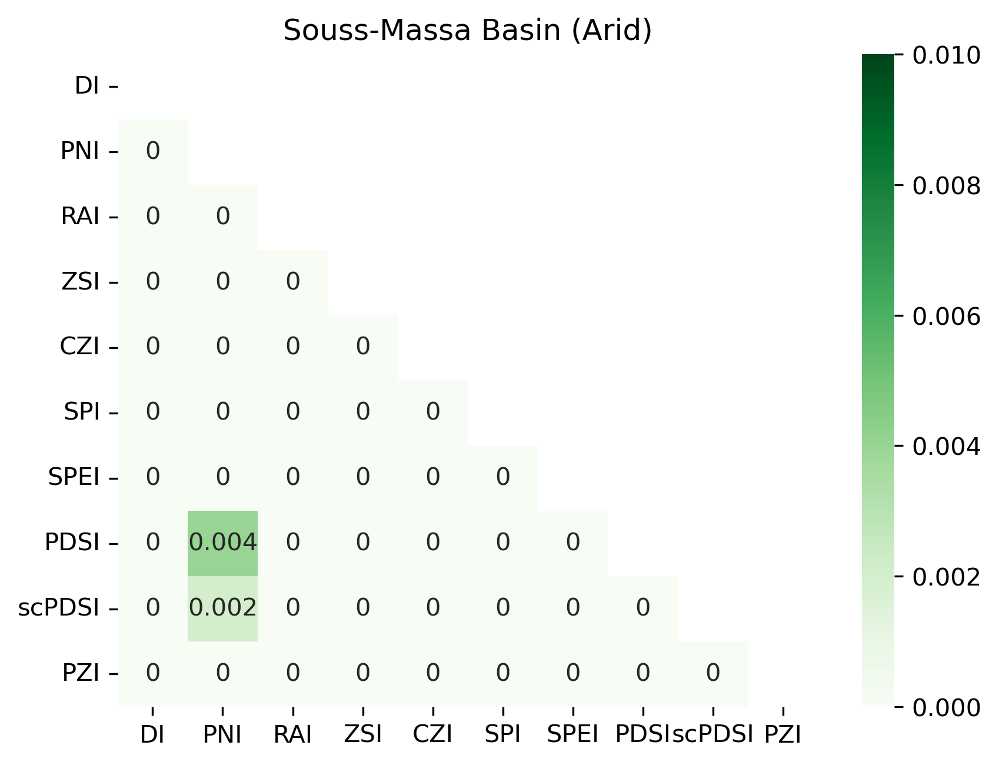

In [90]:
#DI_souss = DI_souss.drop(['Dates'], axis=1)
#DI_souss.replace([np.inf, -np.inf], np.nan, inplace=True)
#DI_souss.dropna()
pvalue = calculate_pvalues(DI_souss)
matrix = DI_souss.corr().round(2)
mask = np.triu(np.ones_like(matrix, dtype=bool))

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
pvalue = pvalue.astype(float).round(3)
sns.heatmap(pvalue, annot=True, vmax=0.01, cmap='Greens', mask=mask)
#sns.heatmap(matrix, annot=True, vmax=1, vmin=-1, center=0, cmap='vlag', mask=mask)
plt.title("Souss-Massa Basin (Arid)")
plt.show()

Text(0, 1, 'PZI')

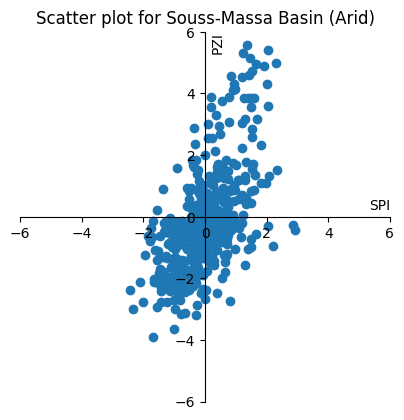

In [60]:
x=DI_souss['SPI']
y=DI_souss['PZI']
fig, ax = plt.subplots()
ax.scatter(x, y)
ax.set_aspect('equal')

# set the x-spine (see below for more info on `set_position`)
ax.spines['left'].set_position('zero')

# turn off the right spine/ticks
ax.spines['right'].set_color('none')
ax.yaxis.tick_left()

# set the y-spine
ax.spines['bottom'].set_position('zero')

# turn off the top spine/ticks
ax.spines['top'].set_color('none')
ax.xaxis.tick_bottom()
ax.set_ylim(-6, 6)
ax.set_xlim(-6, 6)
ax.set_title('Scatter plot for Souss-Massa Basin (Arid)')
ax.set_xlabel('SPI', loc='right', labelpad=-30)
ax.set_ylabel('PZI', loc='top', labelpad=-36)

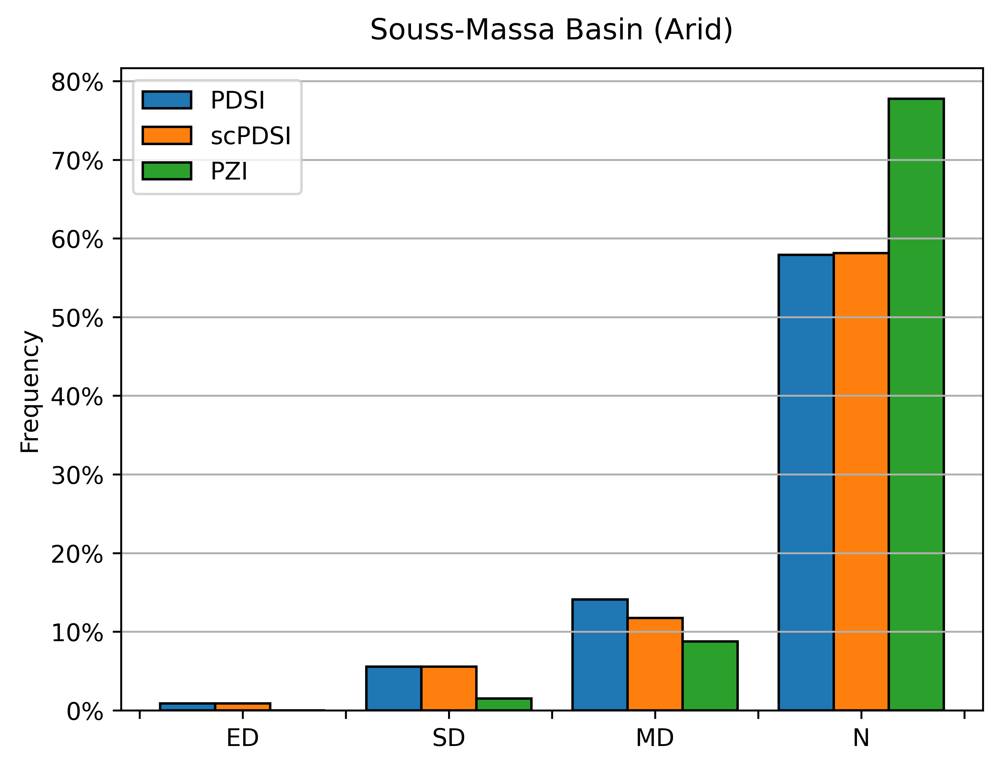

In [137]:
#create relative frequency histogram with percentages on y-axis
data = DIc_souss[['PDSI', 'scPDSI', 'PZI']]
#data = [1, 2 , 3, 0, -3, -1, -2, 0, -1, 0, 2, 2, 0, 0, -2]
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
fig = plt.figure()
ax = fig.add_subplot(111)
ax.hist(data, edgecolor='black', weights=np.ones_like(data)*100 / len(data), label=['PDSI', 'scPDSI', 'PZI'], bins=[-3,-2,-1,0,1], align='left') #, 'ZSI', 'CZI', 'SPI', 'SPEI', 'PDSI', 'scPDSI', 'PZI'
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xticklabels(['', '', 'ED', '', 'SD', '', 'MD', '', 'N'])
ax.grid(axis='y')
ax.set_title('Souss-Massa Basin (Arid)', pad = 12)
ax.set_ylabel('Frequency')
ax.legend()

In [97]:
DI_souss.set_index("Dates", inplace = True)
#DI_souss.index = pd.to_datetime(DI_souss.index, format='%d/%m/%Y')

In [ ]:

data = DI_souss
fig = plt.figure(figsize=(20, 8))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
fig.suptitle('Drought Indices Time Series in the Souss-Massa basin')
axs[0].plot(data.index, data['RAI'], label='RAI')
#axs[0].axhline(y=-3, color='r')
axs[0].legend()
axs[1].plot(data.index, data['SPI'], label='SPI')
axs[1].legend()
axs[2].plot(data.index, data['SPEI'], label='SPEI')
axs[2].legend()

for ax in axs:
    ax.grid()
    ax.label_outer()

In [ ]:
data = DI_souss
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(3, hspace=0)
axs = gs.subplots(sharex=True, sharey=True)
#fig.suptitle('Drought Indices Time Series')
axs[0].plot(data.index, data['PDSI'], label='PDSI')
axs[0].legend()
axs[1].plot(data.index, data['scPDSI'], label='scPDSI')
axs[1].legend()
axs[2].plot(data.index, data['PZI'], label='PZI')
axs[2].legend()
for ax in axs:
    ax.grid()
    ax.label_outer()

In [82]:
DI_souss[394:398]

,Dates,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
394,01-11-15,1.111111,1.000000,0.320526,0.201191,0.201194,0.372054,0.484609,-0.830882,2.218544,-2.492647
395,01-12-15,1.000000,1.000000,0.183738,0.063602,0.063603,-0.304685,-0.605585,-1.804146,-0.380688,-3.176534
396,01-01-16,-1.222222,-2.888889,-2.367723,-0.811759,-0.811815,-2.011692,-2.247895,-2.541254,-2.277420,-2.768806
397,01-02-16,NaN,-1.000000,-0.989548,-0.106266,-0.106268,-0.712400,-1.138457,-2.459046,-2.378374,-0.538622


<Axes: title={'center': 'Time series of Drought Indices in Souss-Massa basin during 2014-2016 drought spell'}, xlabel='Months', ylabel='value of SPI, SPEI and RAI'>

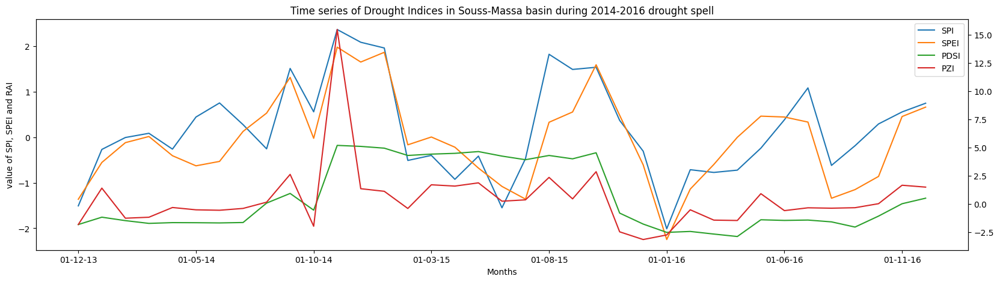

In [109]:
DI_souss[371:408].loc[:,['SPI','SPEI','PDSI','PZI']].plot(secondary_y=['PDSI', 'PZI'], mark_right=False, figsize = (20,5), xlabel='Months', ylabel='value of SPI, SPEI and RAI', title='Time series of Drought Indices in Souss-Massa basin during 2014-2016 drought spell')

RAI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.43881262153485934, z=-0.774199842310982, Tau=-0.08771929824561403, s=-65.0, var_s=6833.666666666667, slope=-0.006915376597368388, intercept=-0.7476659071973241)
SPI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.7531271266832609, z=-0.3145186859388365, Tau=-0.03643724696356275, s=-27.0, var_s=6833.666666666667, slope=-0.00297919402684589, intercept=0.05000113470709163)
SPEI :  Mann_Kendall_Test(trend='decreasing', h=True, p=0.0202006761638156, z=-2.322599526932946, Tau=-0.26045883940620784, s=-193.0, var_s=6833.666666666667, slope=-0.018369883507121064, intercept=0.34265398168728417)
scPDSI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.05292901699473074, z=-1.9354996057774552, Tau=-0.21727395411605938, s=-161.0, var_s=6833.666666666667, slope=-0.04644649378438358, intercept=0.5053640187703192)
PZI :  Mann_Kendall_Test(trend='no trend', h=False, p=0.13361124376778633, z=-1.5000121944775278, Tau=-0.16869095816464239, s=-1

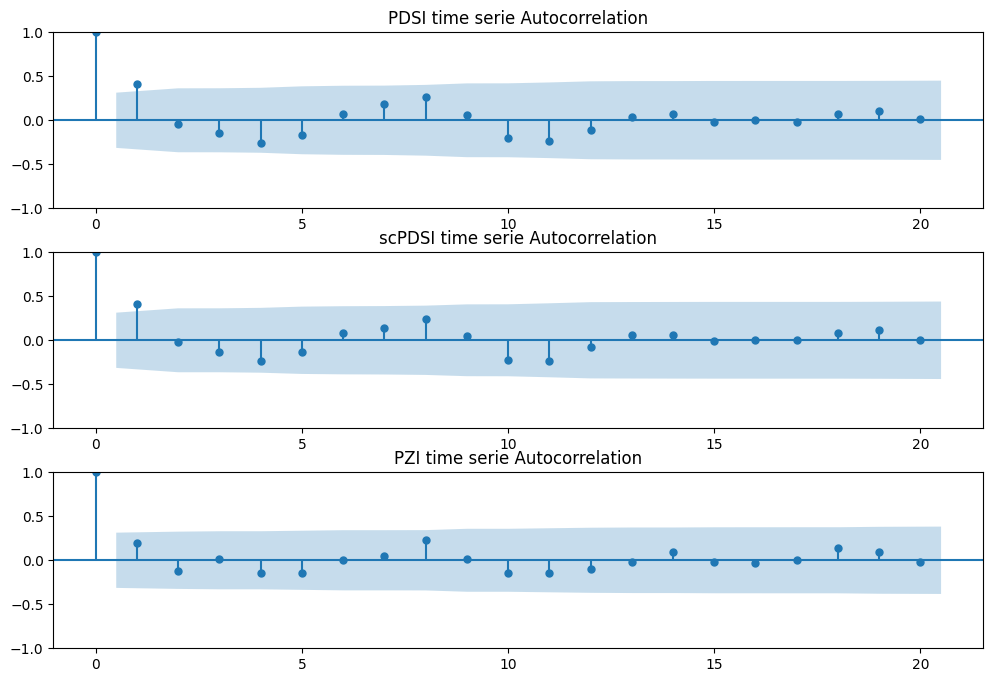

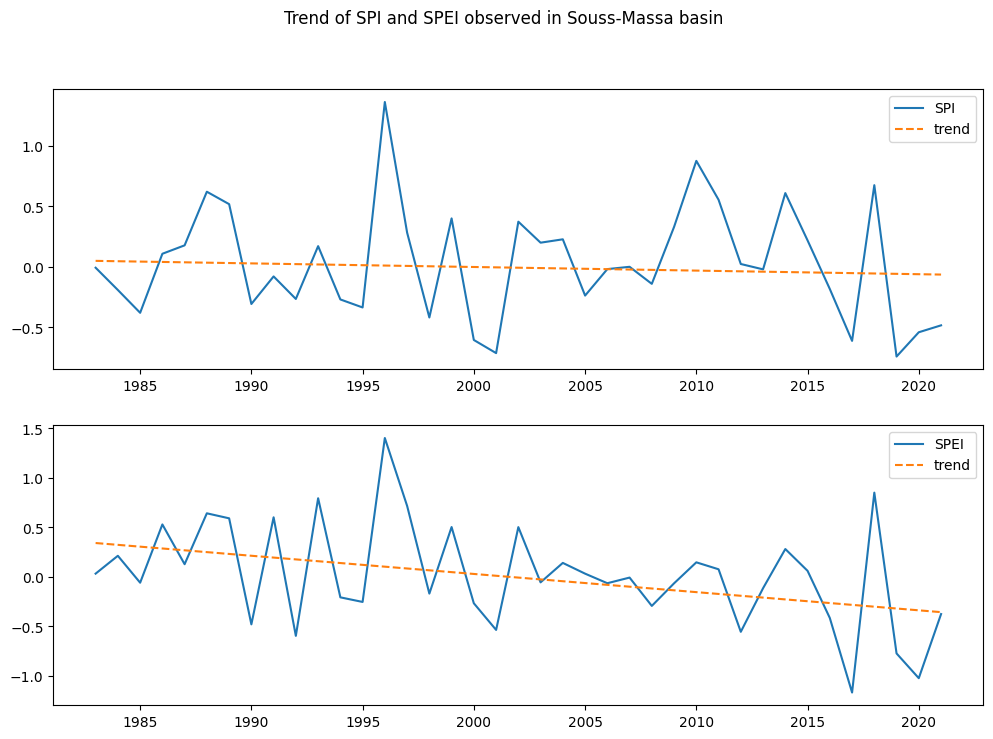

In [39]:
#trend analysis of spi and spei
arai = [np.nansum(DI_souss['RAI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspi = [np.nansum(DI_souss['SPI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
aspei = [np.nansum(DI_souss['SPEI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apdsi = [np.nansum(DI_souss['PDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
ascpdsi = [np.nansum(DI_souss['scPDSI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]
apzi = [np.nansum(DI_souss['PZI'].to_list()[i*12:(i + 1)*12])/12 for i in range(39)]

rai_trend = mk.original_test(arai)
spi_trend = mk.original_test(aspi)
spei_trend = mk.original_test(aspei)
pdsi_trend = mk.original_test(apdsi)
scpdsi_trend = mk.original_test(ascpdsi)
pzi_trend = mk.original_test(apzi)
# perform Mann-Kendall Trend Test
print('RAI : ', rai_trend)
print('SPI : ', spi_trend)
print('SPEI : ', spei_trend)
print('scPDSI : ', scpdsi_trend)
print('PZI : ', pzi_trend)

fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(3, hspace=0.25)
axs = gs.subplots(sharex=False, sharey=True)
sm.graphics.tsa.plot_acf(apdsi, lags=20, ax=axs[0], alpha=0.05, title='PDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(ascpdsi, lags=20, ax=axs[1], alpha=0.05, title='scPDSI time serie Autocorrelation')
sm.graphics.tsa.plot_acf(apzi, lags=20, ax=axs[2], alpha=0.05, title='PZI time serie Autocorrelation')
plt.show()


datetime_series = pd.Series(pd.date_range("1982", periods=39, freq="Y"))

fig, ax = plt.subplots(2, figsize=(12, 8))
fig.suptitle('Trend of SPI and SPEI observed in Souss-Massa basin')
ax[0].plot(datetime_series, aspi, label='SPI')
spi_line = np.arange(len(aspi)) * spi_trend.slope + spi_trend.intercept
ax[0].plot(datetime_series, spi_line, linestyle='--', label='trend')
ax[0].legend()

ax[1].plot(datetime_series, aspei, label='SPEI')
spei_line = np.arange(len(aspei)) * spei_trend.slope + spei_trend.intercept
ax[1].plot(datetime_series, spei_line, linestyle='--', label='trend')
ax[1].legend()

#plt.show()

In [ ]:
DIc_souss = pd.DataFrame()
DIc_souss['Dates'] = DI_souss['Dates']
#DIc_sebou['DI'] = DI_sebou['DI'].round(0)

index = DI_souss['DI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i <= 2 : ic.append(2)
    elif 2 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['DI'] = ic

DIc_souss['PNI'] = DI_souss['PNI'].round(0)

index = DI_souss['RAI'].to_list()
ic = []
for i in index:
    if i <= -3: ic.append(-3)
    elif -3 < i <= -2 : ic.append(-2)
    elif -2 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 2 : ic.append(1)
    elif 2 < i <= 3 : ic.append(2)
    elif 3 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['RAI'] = ic

index = DI_souss['ZSI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i <= 2 : ic.append(2)
    elif 2 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['ZSI'] = ic

index = DI_souss['CZI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i <= 2 : ic.append(2)
    elif 2 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['CZI'] = ic

index = DI_souss['SPI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i <= 2 : ic.append(2)
    elif 2 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['SPI'] = ic

index = DI_souss['SPEI'].to_list()
ic = []
for i in index:
    if i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i <= 2 : ic.append(2)
    elif 2 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['SPEI'] = ic

index = DI_souss['PDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 3 : ic.append(1)
    elif 3 < i <= 4 : ic.append(2)
    elif 4 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['PDSI'] = ic

index = DI_souss['scPDSI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 3 : ic.append(1)
    elif 3 < i <= 4 : ic.append(2)
    elif 4 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['scPDSI'] = ic

index = DI_souss['PZI'].to_list()
ic = []
for i in index:
    if i <= -4: ic.append(-3)
    elif -4 < i <= -3 : ic.append(-2)
    elif -3 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 3 : ic.append(1)
    elif 3 < i <= 4 : ic.append(2)
    elif 4 < i : ic.append(3)
    else : ic.append(np.nan)
DIc_souss['PZI'] = ic
DIc_souss

(67, 72)


<Figure size 640x480 with 0 Axes>

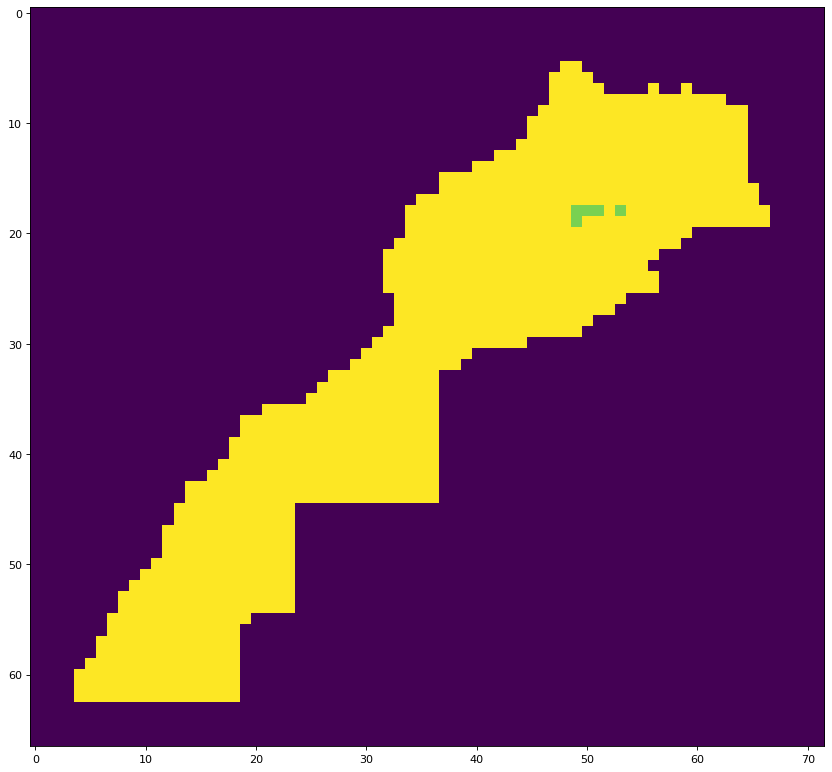

In [27]:
#shp = []
#for i in range(4824):
#    if i in pop : shp.append(1)
#    else: shp.append(0)
shp = pd.read_csv('shapfiles/01shp.csv', low_memory=False)
shp = shp.values.tolist()
shp = np.reshape(shp, (-1, 72))
index = pd.read_csv('output/czi.csv', low_memory=False)
index = index.drop(['Unnamed: 0'], axis=1)
index = index.drop(['Dates'], axis=1)
index = index.values.tolist()

I = np.array(index[397]) #142-6 is Nov 94-Feb 95 #204-7 is Jan-Apr of the year 2000 #394-397 is Nov 2015-Feb 2016
I = np.reshape(I, (-1, 72))
I = I*shp
I[I == 0] = -99
I = I.flatten()
ic = []
for i in I:
    if i == -99: 
        ic.append(-5)
        continue
    elif i <= -2: ic.append(-3)
    elif -2 < i <= -1.5 : ic.append(-2)
    elif -1.5 < i <= -1 : ic.append(-1)
    elif -1 < i <= 1 : ic.append(0)
    elif 1 < i <= 1.5 : ic.append(1)
    elif 1.5 < i <= 2 : ic.append(2)
    elif 2 < i : ic.append(3)
    else : ic.append(np.nan)
 
NI = np.reshape(np.array(ic), (-1, 72))
print(NI.shape)
plt.figure()
plt.figure(figsize=(14, 12), dpi=80)
plt.imshow(NI)

In [28]:
# export
driver = gdal.GetDriverByName("GTiff")
driver.Register()
outds = driver.Create("output/2016_DS/CZI_397.tif", xsize = NI.shape[1],
                      ysize = NI.shape[0], bands = 1, 
                      eType = gdal.GDT_Float32)

# Specify raster location through geotransform array
# (uperleftx, scalex, skewx, uperlefty, skewy, scaley)
# Scale = size of one pixel in units of raster projection
# this example below assumes 100x100
gt = [-17.875, 0.25, 0, 37.125, 0, -0.25]
outds.SetGeoTransform(gt)

# Get raster projection
epsg = 4326
srs = osr.SpatialReference()
srs.ImportFromEPSG(epsg)
proj = srs.ExportToWkt()
outds.SetProjection(proj)

outband = outds.GetRasterBand(1)
outband.WriteArray(NI)
outband.SetNoDataValue(np.nan)
outband.FlushCache()

# close your datasets and bands!!!
outband = None
outds = None

In [895]:
DI_sebou

,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
Dates,,,,,,,,,,
1983-01-01,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,-0.933192,-0.933192,-2.799576
1983-02-01,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,1.123539,1.123539,3.370617
1983-03-01,1.100000,1.000000,0.228651,0.848568,0.848554,-0.206007,-0.119493,-0.645141,-0.458213,-1.763763
1983-04-01,1.470588,1.000000,0.543788,1.216664,1.216132,0.274592,0.390407,-0.904982,-0.835710,-0.978870
1983-05-01,-1.000000,-1.000000,-1.292413,-0.164539,-0.164541,-1.056914,-0.571797,-0.956656,-0.895518,-0.434661
...,...,...,...,...,...,...,...,...,...,...
2021-08-01,-3.000000,-3.000000,-2.879971,-1.151832,-1.151625,-0.535858,0.231045,-0.899669,-0.290673,-0.436939
2021-09-01,-3.000000,-3.000000,-2.800253,-1.112160,-1.112024,-0.795722,-0.307710,-1.188361,-0.918078,-0.983365
2021-10-01,-2.444444,-3.000000,-2.597315,-1.015230,-1.015203,-1.772584,-1.187626,-1.971561,-1.939648,-2.716804


In [913]:
tist = DI_sebou[DI_sebou['SPI'].isnull()]
DI_tensift['PZI'].isnull().sum()

In [914]:
tist

,DI,PNI,RAI,ZSI,CZI,SPI,SPEI,PDSI,scPDSI,PZI
Dates,,,,,,,,,,
1983-01-01,NaN,1.0,NaN,NaN,NaN,NaN,NaN,-0.933192,-0.933192,-2.799576
1983-02-01,NaN,1.0,NaN,NaN,NaN,NaN,NaN,1.123539,1.123539,3.370617
1990-02-01,NaN,1.0,NaN,NaN,NaN,NaN,-0.550969,4.360787,4.360787,3.188410
1990-03-01,NaN,1.0,NaN,NaN,NaN,NaN,-2.150138,3.659418,3.312716,-0.756626
1990-04-01,NaN,1.0,NaN,NaN,NaN,NaN,-2.486620,4.223176,4.223176,2.822034
1992-02-01,NaN,1.0,NaN,NaN,NaN,NaN,-2.359395,-2.048629,-2.233503,-1.904806
1992-03-01,NaN,1.0,NaN,NaN,NaN,NaN,-2.337547,0.008757,-1.302966,0.848345
1992-04-01,NaN,1.0,NaN,NaN,NaN,NaN,-1.584105,0.727674,0.286403,1.962314


In [909]:
DI_tensift['PZI'].isnull().sum()

0

In [908]:
DI_souss['PZI'].isnull().sum()

0